## **PROPOSED TITLE: Supporting Enterprise Cybersecurity Risk Management Through Explainable AI-Driven Stacking Ensemble Intrusion Detection Using the UNSW-NB15 Dataset**
**DATASET SOURCE: https://research.unsw.edu.au/projects/unsw-nb15-dataset**

# **IMPORTING LIBRARIES & INSTALLING DEPENDENCY**

In [1]:
# This instruction prepares the working environment by bringing together numerical handling capability, structured table manipulation support, tools for drawing charts and visuals, utilities for advanced data exploration, algorithms for intelligent pattern learning, techniques to fix uneven category problems, systems for neural computation, boosted decision logic, explanation mechanisms for predictions, and saving or reusing trained systems
!pip install -q numpy pandas matplotlib seaborn scikit-learn xgboost lightgbm catboost lightgbm tensorflow shap lime psutil -q

In [2]:
# ------------------------------------------------------------------------------
# 2. Core System, OS & Performance Tracking Utilities
# ------------------------------------------------------------------------------
# Import packages providing facilities for the manipulation of the operating system and its resources as well as for monitoring purposes.
import os
# Import package for accessing information about the interpreter.
import sys
# Import timing capabilities for performance profiling and analysis.
import time
# Import pseudo random number generator for reproducible stochastic computations.
import random
# Import utilities for querying the hardware and operating systems characteristics.
import platform
# Import package providing facilities to control warnings during execution.
import warnings
# Import utilities for observing the resource consumption by the system.
import psutil
# Import utilities for tracking memory allocation during execution.
import tracemalloc
from sklearn.pipeline import Pipeline, make_pipeline
# ------------------------------------------------------------------------------
# 3. Numerical Computation & Tabular Data Manipulation
# ------------------------------------------------------------------------------

# Defines a section for numerical computations and structured data handling.
# Suppress backend warnings and low-level logs for clean presentation.
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
# Suppress non-critical warnings during execution.
warnings.filterwarnings('ignore')

# Import capabilities for numerical array processing and mathematics.
import numpy as np
# Import tabular data structures and data manipulation facilities.
import pandas as pd
# Import capabilities for rank correlation analysis.
from scipy.stats import spearmanr
# Import chi-squared distribution functionality for computing statistical significance.
from scipy.stats import chi2
# Import categorical encoding functionalities for machine learning preprocessing.
from sklearn.preprocessing import OneHotEncoder

# ------------------------------------------------------------------------------
# 4. Publication-Quality Data Visualization Libraries
# ------------------------------------------------------------------------------

# Defines a section for visualization with an analytical perspective.
# Import core interface for building figures.
import matplotlib.pyplot as plt
# Import facilities for layout management.
import matplotlib.gridspec as gridspec
# Import graphical patch objects for annotations.
import matplotlib.patches as mpatches
# Import axis formatting utilities.
import matplotlib.ticker as mticker
# Import reusable graphical elements for legends and annotations.
from matplotlib.patches import Patch
# Import facilities for building custom continuous color scales.
from matplotlib.colors import LinearSegmentedColormap
# Import statistical visualizations.
import seaborn as sns
# Import flexible formatting functionalities.
from matplotlib.ticker import FuncFormatter

# ------------------------------------------------------------------------------
# 5. Scikit-Learn: Base Estimators, Preprocessing & Feature Selection
# ------------------------------------------------------------------------------

# Specifies a section for preprocessors, estimators and feature selection techniques.
# Imports base interfaces for building compatible machine learning estimators.
from sklearn.base import BaseEstimator, ClassifierMixin
# Imports train/test split and stratification utilities.
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
# Imports data scaling, normalization and label encoding techniques.
from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder
# Imports techniques to reduce variable information content and select predictive features.
from sklearn.feature_selection import (
    VarianceThreshold,
    RFE,
    SequentialFeatureSelector
)

# ------------------------------------------------------------------------------
# 6. Machine Learning & Ensemble Algorithms
# ------------------------------------------------------------------------------

# Specifies a section for classification and ensemble learning algorithms.
# Imports a linear probabilistic classifier for binary prediction.
from sklearn.linear_model import LogisticRegression
# Imports tree classifiers and stacking based ensemble learners.
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
# Imports a gradient boosting classifier for non-linear predictive modeling.
from xgboost import XGBClassifier
# Imports the more general framework to inspect its version.
import xgboost as xgb
# Imports a fast gradient boosting classifier for structured data.
from lightgbm import LGBMClassifier
# Imports the more general framework to inspect its version.
import lightgbm as lgb
# Imports a categorical boosting classifier for heterogenous tabular data.
from catboost import CatBoostClassifier

# ------------------------------------------------------------------------------
# 7. Model Evaluation Metrics (Strictly Binary Setup)
# ------------------------------------------------------------------------------

# Specifies a section for evaluation metrics of binary classification.
# Imports supplementary metrics for assessing predictive accuracy and classification quality.
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report,
    roc_curve,
    auc
)
# Imports additional threshold based metrics to assess precision-recall performance.
from sklearn.metrics import fbeta_score, precision_recall_curve

# ------------------------------------------------------------------------------
# 8. Deep Learning Framework (TensorFlow & Keras Architectures)
# ------------------------------------------------------------------------------

# Specifies a section for neural network computation and sequential learning.
# Imports the main framework for building and training neural prediction models.
import tensorflow as tf
# Imports the high level API for defining and managing neural networks.
from tensorflow import keras
# Imports backend functions to perform customized neural network computations.
import tensorflow.keras.backend as K
# Import reusable building blocks such as layers, models, and regularizers.
from tensorflow.keras import layers, models, regularizers
# Import architectural components like convolutions, recursions, poolings, normalizations, and dense connections.
from tensorflow.keras.layers import (
    Input,
    Conv1D,
    MaxPooling1D,
    Bidirectional,
    LSTM,
    Dense,
    Dropout,
    Flatten,
    Layer,
    BatchNormalization,
    GlobalAveragePooling1D
)
# Import callbacks for early stopping, learning rate scheduling, and model saving during training.
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

# ------------------------------------------------------------------------------
# 9. Explainable Artificial Intelligence (XAI) Modules
# ------------------------------------------------------------------------------

# Declare a segment dedicated to explainable machine-learning tools.
# Import methods for attributing features to model decisions.
import shap
# Import the local interpretability framework independent from the model architecture.
import lime
# Import capabilities for explaining structured tabular observations.
import lime.lime_tabular
# Import utilities for displaying analytical results in notebooks.
from IPython.display import display

# ------------------------------------------------------------------------------
# 10. Deterministic Reproducibility Seed Locking
# ------------------------------------------------------------------------------

# Declare a segment dedicated to experimental reproducibility and consistent stochastic initialization.
# Set a constant initializer seed to have consistent experiments.
RANDOM_SEED = 42

# Import an experiment-wide utility that enables stochastic initialization synchronization.
def set_deterministic_seeds(seed=RANDOM_SEED):
    # Document the use case for the utility that provides experimental reproducibility.
    """Locks random seeds across all libraries for exact reproducibility."""
    # Synchronize a general-purpose pseudo-random generator.
    random.seed(seed)
    # Synchronize random number generation operations by numerical libraries.
    np.random.seed(seed)
    # Synchronize interpreter's hashing initializer for consistent execution.
    os.environ['PYTHONHASHSEED'] = str(seed)
    # Synchronize random number generation within the neural computation framework.
    tf.random.set_seed(seed)
    # Limit framework logging to critical errors only.
    tf.get_logger().setLevel('ERROR')

# Apply the seed to the experiment-wide context.
set_deterministic_seeds(RANDOM_SEED)

# ------------------------------------------------------------------------------
# 11. Hardware Specification & Library Environment Audit
# ------------------------------------------------------------------------------

# Defines the block for hardware, software and reproducibility environment validation.
# Prints the visual separator prior to the environment check.
print("=" * 75)
# Prints the title of the system and reproducibility report.
print("SYSTEM SPECIFICATIONS & REPRODUCIBILITY AUDIT")
# Prints the visual separator under the report title.
print("=" * 75)

# Stores the timestamp of the current run.
print(f"Execution Date/Time  : {time.strftime('%Y-%m-%d %H:%M:%S')}")
# Stores the version of the active interpreter.
print(f"Python Version       : {sys.version.split()[0]}")
# Stores the name of the operating system family and the release.
print(f"Operating System     : {platform.system()} {platform.release()}")
# Stores information about the processor and the number of logical cores.
print(f"CPU Architecture     : {platform.processor()} ({psutil.cpu_count(logical=True)} Logical Cores)")
# Converts the amount of the total system memory to gigabytes.
print(f"Total Available RAM  : {psutil.virtual_memory().total / (1024**3):.2f} GB")

# Extracts the available hardware accelerators from the neural computation library.
gpus = tf.config.list_physical_devices('GPU')
# Checks the existence of an accelerator device.
if gpus:
    # Extracts the id of the detected accelerator.
    gpu_name = tf.test.gpu_device_name()
    # Prints the message about successful detection of the accelerator device and its id.
    print(f"Hardware Accelerator: Active GPU -> {gpu_name}")
# Defines the fallback path in case of the absence of accelerator.
else:
    # Prints the message about the use of the regular CPU.
    print(f"Hardware Accelerator: CPU Mode (No GPU detected)")

# Prints the separator between hardware and software environment information.
print("-" * 75)
# Prints the heading for installed dependencies.
print("CORE DEPENDENCY VERSIONS")
# Prints the separator below the heading of dependencies.
print("-" * 75)

# Prints the installed numerical library version.
print(f"NumPy       : {np.__version__}")
# Prints the installed tabular data library version.
print(f"Pandas      : {pd.__version__}")
# Imports the machine learning framework using shorter namespace for version identification.
import sklearn as sk
# Prints the installed machine learning framework version.
print(f"Scikit-Learn: {sk.__version__}")
# Prints the installed gradient boosting framework version.
print(f"XGBoost     : {xgb.__version__}")
# Prints the installed second boosting framework version.
print(f"LightGBM    : {lgb.__version__}")
# Prints the installed neural computation framework version.
print(f"TensorFlow  : {tf.__version__}")
# Prints the installed feature attribution framework version.
print(f"SHAP        : {shap.__version__}")
# Ensures that the installed local explanation framework is available by specifying the path of the package.
print(f"LIME        : {lime.__file__.split('/')[-2] if hasattr(lime, '__file__') else 'Installed'}")
# Prints the fixed initial value.
print(f"Random Seed : Locked to {RANDOM_SEED}")
# Prints the separator at the end of the environment audit.
print("=" * 75)
# Ensures proper initialization of the setup for further experiments.
print("[✓] Step 1 Initialized Successfully. Environment Ready.")

SYSTEM SPECIFICATIONS & REPRODUCIBILITY AUDIT
Execution Date/Time  : 2026-10-15 03:57:12
Python Version       : 3.13.15
Operating System     : Linux 6.18.48+
CPU Architecture     : x86_64 (4 Logical Cores)
Total Available RAM  : 31.35 GB
Hardware Accelerator: Active GPU -> /device:GPU:0
---------------------------------------------------------------------------
CORE DEPENDENCY VERSIONS
---------------------------------------------------------------------------
NumPy       : 2.1.3
Pandas      : 2.3.3
Scikit-Learn: 1.6.1
XGBoost     : 3.4.1
LightGBM    : 4.6.0
TensorFlow  : 2.20.0
SHAP        : 0.52.0
LIME        : lime
Random Seed : Locked to 42
[✓] Step 1 Initialized Successfully. Environment Ready.


I0000 00:00:1792036633.790615      48 gpu_device.cc:2020] Created device /device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792036633.794660      48 gpu_device.cc:2020] Created device /device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


# **DATA LOADING & EXPLORATORY DATA ANALYSIS**

In [3]:
# Establishes the initial step towards finding and loading the two benchmark partitions used for conducting the experiment.
# ------------------------------------------------------------------------------
# 1. Loading the Benchmark Datasets
# ------------------------------------------------------------------------------
train_path = '/kaggle/input/datasets/dataset066/unsw-b15-dataset/UNSW_NB15_training-set.csv'

# Determines the main destination of the learning partition.
test_path  = '/kaggle/input/datasets/dataset066/unsw-b15-dataset/UNSW_NB15_testing-set.csv'

# Establishes an alternative file location in case the main expected file location is not available.
# Verifies the initial availability of the file location of the learning file.
if not os.path.exists(train_path):
    # Assigns the file location of the learning file to the current working directory.
    train_path = 'UNSW_NB15_training-set.csv'
    # Assigns the file location of the evaluation file to the current working directory.
    test_path  = 'UNSW_NB15_testing-set.csv'
# Initiates the file import process safely.
try:
    # Loads the learning partition into a table format.
    traindata = pd.read_csv(train_path)
    # Loads the independent evaluation partition into a table format.
    testdata  = pd.read_csv(test_path)
    # Verifies the correct loading of the learning partition and prints the file location.
    print(f"[✓] Successfully loaded Training Partition: {train_path}")
    # Verifies the correct loading of the independent evaluation partition and prints the file location.
    print(f"[✓] Successfully loaded Independent Test Partition: {test_path}")
# Deals with the scenario in which one or more requested files cannot be found.
except FileNotFoundError as e:
    # Indicates the file import failure and suggests checking the file locations.
    print(f"[!] Error loading files: {e}. Please verify file paths.")
    # Exits from the code in case of unresolvable file access problem.
    raise

# Sets up the second phase to measure the structure and approximate storage requirements.
# ------------------------------------------------------------------------------
# 2. Dataset Dimension & Memory Profile
# ------------------------------------------------------------------------------
# Computes the approximate memory requirement of the learning portion in MBs.
train_mem = traindata.memory_usage(deep=True).sum() / (1024**2)
# Computes the approximate memory requirement of the evaluation portion in MBs.
test_mem  = testdata.memory_usage(deep=True).sum() / (1024**2)
# Creates a visual separation prior to presenting the audit summary of the data set.
print("\n" + "=" * 75)
# Presents the primary heading for the benchmark data description.
print("UNSW-NB15 BENCHMARK DATASET OVERVIEW")
# Creates a visual separation below the heading.
print("=" * 75)
# Provides the number of observations and attributes found in the learning portion.
print(f"Training Partition Shape          : {traindata.shape[0]:,} rows × {traindata.shape[1]} columns")
# Provides the number of observations and attributes found in the independent evaluation portion.
print(f"Independent Test Partition Shape  : {testdata.shape[0]:,} rows × {testdata.shape[1]} columns")
# Provides the estimated storage requirement of the learning portion.
print(f"Training Memory Footprint         : {train_mem:.2f} MB")
# Provides the estimated storage requirement of the evaluation portion.
print(f"Testing Memory Footprint          : {test_mem:.2f} MB")
# Provides the total number of unavailable entries in the learning portion.
print(f"Total Missing Values (Train)      : {traindata.isnull().sum().sum()}")
# Provides the total number of unavailable entries in the evaluation portion.
print(f"Total Missing Values (Test)       : {testdata.isnull().sum().sum()}")
# Provides a visual border after the structure and memory summary.
print("-" * 75)
# Sets up the third phase to examine the representation format of the attributes.
# ------------------------------------------------------------------------------
# 3. Data Type Distribution
# ------------------------------------------------------------------------------
# Shows the heading for the representation format summary.
print("FEATURE DATA TYPES BREAKDOWN (TRAIN):")
# Calculates the number of attributes per representation format found in the stored data.
dtype_counts = traindata.dtypes.value_counts()
# Iterates over every identified representation format and its respective number of attributes.
for dt, count in dtype_counts.items():
    # Shows each representation format along with the number of its attributes.
    print(f"  • {str(dt):10s} : {count:2d} features")
# Establishes the fourth stage for identifying non-numeric attributes and inspecting their distinct values.
# ------------------------------------------------------------------------------
# 4. Categorical Feature Inspection
# ------------------------------------------------------------------------------
# Identifies attributes stored in textual form and changes their names to a canonical set.
cat_cols = traindata.select_dtypes(include=['object']).columns.tolist()
# Prints a visual separator before checking the textual attributes.
print("\n" + "-" * 75)
# Prints the heading for checking the categorical attributes.
print("CATEGORICAL ATTRIBUTES AUDIT:")
# Iterates over each identified textual attribute.
for col in cat_cols:
    # Counts the number of distinct values in the training partition.
    train_unq = traindata[col].nunique()
    # Counts the number of distinct values in the test partition.
    test_unq  = testdata[col].nunique()
    # Takes a sample of distinct values for a qualitative review.
    sample_vals = list(traindata[col].unique()[:5])
    # Outputs distinct-value counts in the partitions along with samples.
    print(f"  • {col:12s} | Train Unique: {train_unq:3d} | Test Unique: {test_unq:3d} | Sample: {sample_vals}")
# Establishes the fifth stage for analyzing the two-class result structure.
# ------------------------------------------------------------------------------
# 5. Binary Target Distribution (Normal vs. Attack)
# ------------------------------------------------------------------------------
# Prints a visual separator before the class distribution output.
print("\n" + "-" * 75)
# Prints the heading describing the binary class distribution.
print("BINARY CLASSIFICATION TARGET DISTRIBUTION (label):")
# Prints a visual separator under the target distribution heading.
print("-" * 75)
# Identifies the start of the class distribution in the training partition.
print("1. Training Partition:")
# Iterates over each outcome value and its occurrence frequency in the training partition.
for lbl, cnt in traindata['label'].value_counts().items():
    # Changes numerical codes for outcome values into human-readable classes.
    name = "Normal (Class 0)" if lbl == 0 else "Attack (Class 1)"
    # Computes the percentage of the current class in the training partition.
    pct  = (cnt / len(traindata)) * 100
    # Outputs the class, the number of observations and its relative size.
    print(f"   - {name:18s}: {cnt:7,} records ({pct:6.2f}%)")
# Identifies the start of the class distribution in the test partition.
print("\n2. Independent Benchmark Test Partition:")
# Iterates over each outcome value along with its respective frequency in the independent evaluation partition.
for lbl, cnt in testdata['label'].value_counts().items():
    # Translates the numerical outcome codes into the class description.
    name = "Normal (Class 0)" if lbl == 0 else "Attack (Class 1)"
    # Computes the percentage contribution of the present outcome in the independent evaluation partition.
    pct  = (cnt / len(testdata)) * 100
    # Reports the class description, number of observations, and proportion in the dataset.
    print(f"   - {name:18s}: {cnt:7,} records ({pct:6.2f}%)")
# Defines the sixth phase where the finer-grained event classes will be reported without using the same as the outcome.
# ------------------------------------------------------------------------------
# 6. Attack Category Sub-Class Breakdown (For Reference / Characterization)
# ------------------------------------------------------------------------------
# Determines the presence of an optional categorical descriptor in the learning partition.
if 'attack_cat' in traindata.columns:
    # Constructs a separator before displaying the finer-grained category description.
    print("\n" + "-" * 75)
    # Presents the title that indicates that the category description is provided as a reference only.
    print("SUB-CATEGORY ATTACK DISTRIBUTION (TRAIN - REFERENCE ONLY):")
    # Constructs a separator below the category-description title.
    print("-" * 75)
    # Iterates over each of the available categories along with their respective frequencies.
    for cat, cnt in traindata['attack_cat'].value_counts().items():
        # Computes the percentage contribution of the present category in the entire learning partition.
        pct = (cnt / len(traindata)) * 100
        # Reports the category description, number of observations, and proportion in the dataset.
        print(f"   • {str(cat).strip():22s}: {cnt:7,} ({pct:5.2f}%)")

# Prints the final separator at the end of the audit.
print("=" * 75)
# Indicates the successful completion of the first phase of acquisition and dataset-validation exercise.
print("[✓] Step 2 Initial Ingestion & Dataset Audit Complete.")

[✓] Successfully loaded Training Partition: /kaggle/input/datasets/dataset066/unsw-b15-dataset/UNSW_NB15_training-set.csv
[✓] Successfully loaded Independent Test Partition: /kaggle/input/datasets/dataset066/unsw-b15-dataset/UNSW_NB15_testing-set.csv

UNSW-NB15 BENCHMARK DATASET OVERVIEW
Training Partition Shape          : 175,341 rows × 45 columns
Independent Test Partition Shape  : 82,332 rows × 45 columns
Training Memory Footprint         : 90.21 MB
Testing Memory Footprint          : 42.32 MB
Total Missing Values (Train)      : 0
Total Missing Values (Test)       : 0
---------------------------------------------------------------------------
FEATURE DATA TYPES BREAKDOWN (TRAIN):
  • int64      : 30 features
  • float64    : 11 features
  • object     :  4 features

---------------------------------------------------------------------------
CATEGORICAL ATTRIBUTES AUDIT:
  • proto        | Train Unique: 133 | Test Unique: 131 | Sample: ['tcp', 'udp', 'arp', 'ospf', 'icmp']
  • servic

# **DATA VISUALIZATION**

Generating Publication Visualizations...


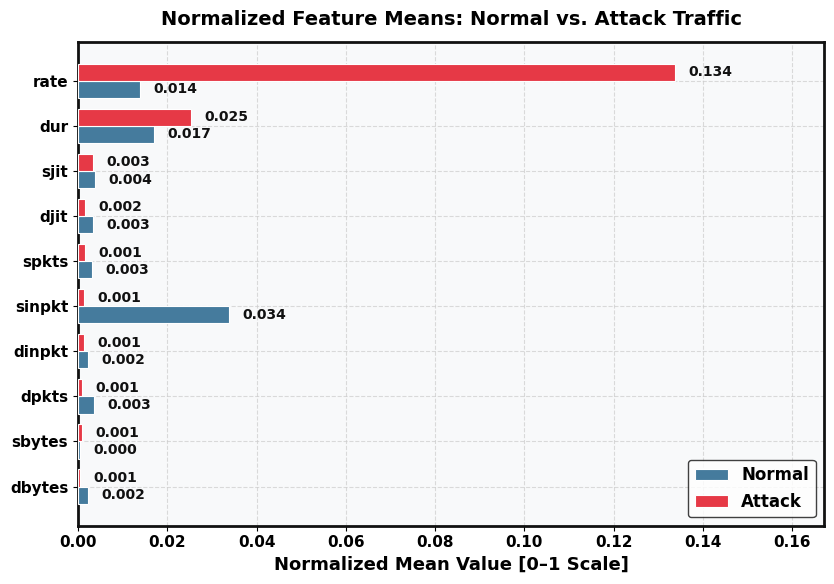

[✓] Plot 1 Generated & Saved: plot_1_feature_means.png


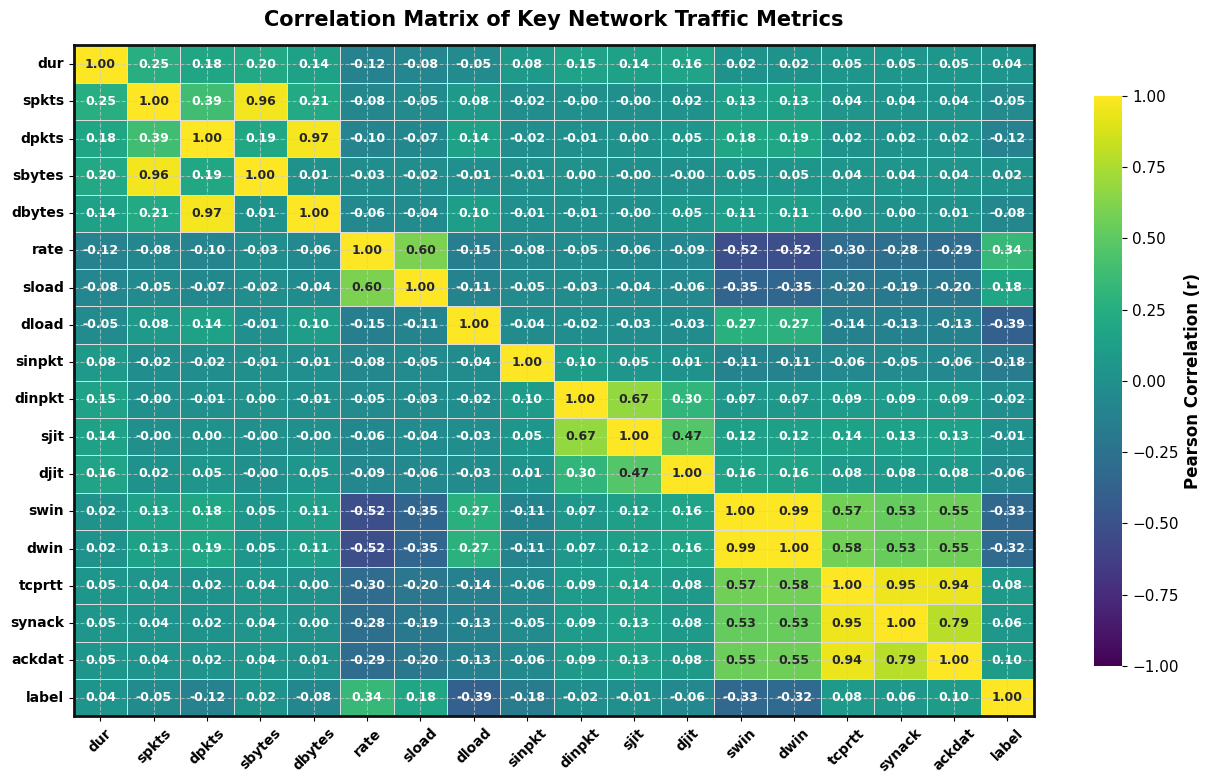

[✓] Plot 2 Generated & Saved: plot_2_correlation_heatmap.png


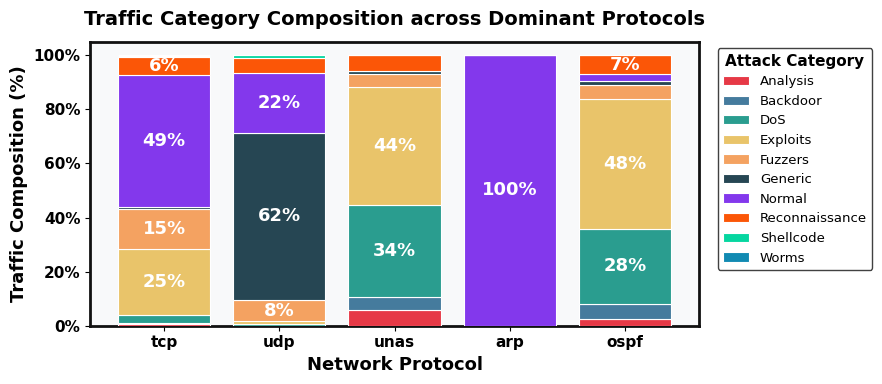

[✓] Plot 3 Generated & Saved: plot_3_protocol_breakdown.png


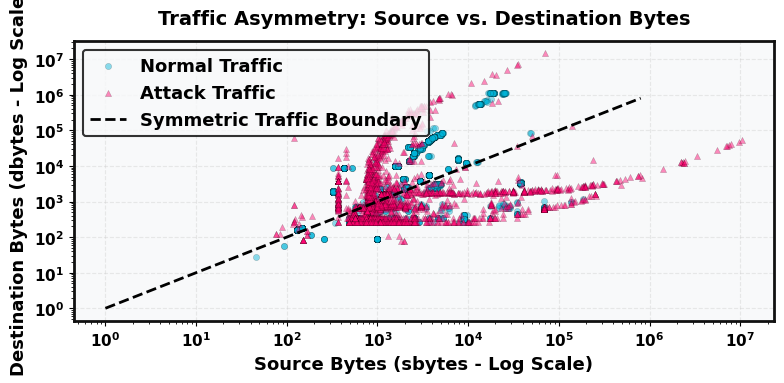

[✓] Plot 4 Generated & Saved: plot_4_bytes_scatter.png


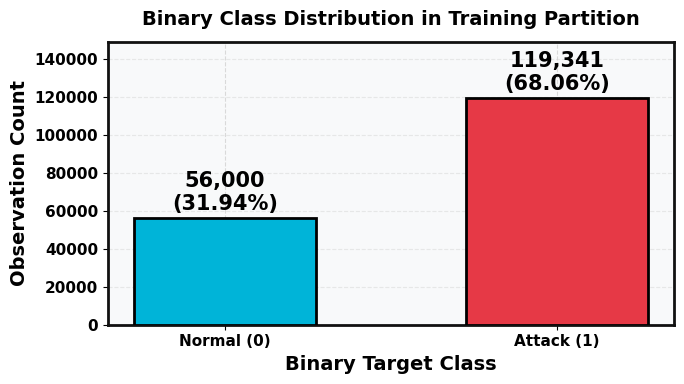

[✓] Plot 5 Generated & Saved: plot_5_binary_distribution.png

[✓] All Step 3 Visualizations Successfully Rendered and Exported.


In [4]:
# Defines the first step in setting up a uniform academic visual representation in all created figures.
# ------------------------------------------------------------------------------
# 1. Global Academic Plotting Style Configuration
# ------------------------------------------------------------------------------
# Specifies the general background of the canvas that should keep a neat presentation.
plt.rcParams.update({
    # Defines the secondary background of the main graphical area.
    'figure.facecolor' : 'white',
    # Specifies the typeface used consistently in all graphical objects.
    'axes.facecolor'   : '#F8F9FA',
    # Defines the default scale of text for visual notes.
    'font.family'      : 'DejaVu Sans',
    # Adds visual emphasis to figure headings.
    'font.size'        : 12,
    # Defines the standard size of axis labels.
    'axes.titleweight' : 'bold',
    # Adds typographic emphasis to axis labels.
    'axes.labelsize'   : 14,
    # Defines the size of text used for horizontal-axis labels.
    'axes.labelweight' : 'bold',
    # Defines the size of text used for vertical-axis labels.
    'xtick.labelsize'  : 11,
    # Allows the use of reference lines to facilitate the readability of graphical representations.
    'ytick.labelsize'  : 11,
    # Gives reference lines a light neutral look.
    'axes.grid'        : True,
    # Uses a dashed line style for reference lines to differentiate them from other graphical elements.
    'grid.color'       : '#CCCCCC',
    # Defines the thickness of reference lines.
    'grid.linestyle'   : '--',
    # Sets the transparency of reference lines.
    'grid.linewidth'   : 0.8,
    # Defines a dark style for the borders of graphical objects.
    'grid.alpha'       : 0.7,
    # Sets the thickness of the borders of graphical objects.
    'axes.edgecolor'   : '#111111',
    # Shows the top border of the graph.
    'axes.linewidth'   : 2.0,
    # Ensures that the correct graphical boundary is visible.
    'axes.spines.top'  : True,
    # Ensures that the correct graphical boundary is visible.
    'axes.spines.right': True,
})
# Specifies a multi-category color scheme for categorizing analysis into distinct groups.
PAL_CAT  = ['#E63946', '#457B9D', '#2A9D8F', '#E9C46A', '#F4A261', '#264653', '#8338EC', '#FB5607', '#06D6A0', '#118AB2']
# Specifies a bi-category color scheme for categorizing the two distinct outcomes.
PAL_DUAL = ['#457B9D', '#E63946'] # 0: Normal (Blue), 1: Attack (Red)
# Specifies output configuration options for generating saved figures at high resolution.
SAVE_OPTS = dict(dpi=300, bbox_inches='tight', facecolor='white')
# Specifies a reusable routine for generating visible borders around analysis figures.
def apply_plot_border(ax, lw=2.0, color='#111111'):
    # Documents the reason for the reusable border-formatting routine.
    """Applies high-visibility academic borders to chart spines."""
    # Iterates over all graphical borders relating to the plotting area.
    for spine in ax.spines.values():
        # Ensures that the graphical borders stay visible.
        spine.set_visible(True)
        # Ensures that the selected border width is applied to the graphical borders.
        spine.set_linewidth(lw)
        # Ensures that the selected border style is applied to the graphical borders.
        spine.set_edgecolor(color)
# Specifies a reusable routine for making the numerical axis labels more prominent.
def make_ticks_bold(ax):
    # Documents the reason for the reusable axis typography routine.
    """Enforces bold typography on tick marks."""
    # Iterates over annotations related to the horizontal and vertical axes.
    for label in ax.get_xticklabels() + ax.get_yticklabels():
        # Makes all axis labels more prominent.
        label.set_fontweight('bold')
# Outputs a progress message that shows the start of the publication-figure creation process.
print("Generating Publication Visualizations...")

# ------------------------------------------------------------------------------
# PLOT 1: Feature Mean Comparison (Normal vs. Attack)
# ------------------------------------------------------------------------------
# Determines the selected numerical variables whose means are going to be compared between the two outcome classes.
features_mean_list = ['dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sinpkt', 'dinpkt', 'sjit', 'djit']
# Begins a range-based scaling process for putting the selected variables on the same numerical scale.
norm_scaler = MinMaxScaler()
# Scales the selected variables to a similar range and saves the result as a table.
scaled_eda_df = pd.DataFrame(norm_scaler.fit_transform(traindata[features_mean_list]), columns=features_mean_list)
# Links the outcome assignments to the scaled variables for further analysis in groups.
scaled_eda_df['label'] = traindata['label'].values
# Calculates the mean scaled value of each selected variable separately for each outcome class.
means_df = scaled_eda_df.groupby('label')[features_mean_list].mean().T
# Gives the two outcome classes new class names for better understanding.
means_df.columns = ['Normal', 'Attack']
# Orders the selected variables according to the average value in the second outcome class.
means_df = means_df.sort_values('Attack', ascending=True)
# Makes a figure and plotting area with suitable dimensions for an academic horizontal comparison.
fig, ax = plt.subplots(figsize=(8.5, 6), facecolor='white')
# Makes sequential vertical positions for the selected variables.
y_pos = np.arange(len(means_df))
# Determines the gap between the horizontal bars that are going to be plotted in pairs.
bar_w = 0.38
# Plots the first set of horizontal bars which represents average values of the first outcome class.
b1 = ax.barh(y_pos - bar_w/2, means_df['Normal'], bar_w, color=PAL_DUAL[0], edgecolor='white', linewidth=0.8, label='Normal', zorder=3)
# Plots the second set of horizontal bars which represents average values of the second outcome class.
b2 = ax.barh(y_pos + bar_w/2, means_df['Attack'], bar_w, color=PAL_DUAL[1], edgecolor='white', linewidth=0.8, label='Attack', zorder=3)
# Loops over each bar which is created to show its value on the figure.
for bar in list(b1) + list(b2):
    # Gets the width of the current bar for value annotation.
    w_val = bar.get_width()
    # Inserts the respective value next to the current bar using appropriate decimal precision and highlighted font.
    ax.text(w_val + 0.003, bar.get_y() + bar.get_height() / 2, f'{w_val:.3f}', va='center', fontsize=10, fontweight='bold', color='#111111')
# Specifies the locations of the vertical axis ticks.
ax.set_yticks(y_pos)
# Assigns the measurement labels to the vertical axis values and highlights the font.
ax.set_yticklabels(means_df.index, fontweight='bold', fontsize=11)
# Specifies the title of the horizontal measurement axis and the relevant formatting.
ax.set_xlabel('Normalized Mean Value [0–1 Scale]', fontweight='bold', fontsize=13)
# Widens the horizontal view range in order to allocate enough space for the numeric labels.
ax.set_xlim(0, max(means_df.max().max() * 1.25, 0.15))
# Inserts the reference grid behind the main graphic elements.
ax.set_axisbelow(True)
# Applies the previously specified academic borders formatting to the plotting area.
apply_plot_border(ax)
# Highlights the font for the axis ticks annotations.
make_ticks_bold(ax)
# Adds a legend that identifies the two compared groups of outcomes with the clear frame around it.
ax.legend(fontsize=11, frameon=True, edgecolor='#111111', facecolor='white', prop={'weight': 'bold'})
# Specifies the descriptive heading of the figure that explains its purpose.
plt.title('Normalized Feature Means: Normal vs. Attack Traffic', fontsize=14, fontweight='bold', pad=12)
# Adjusts automatically the figure spacing in order to avoid overlap of the graphic elements.
plt.tight_layout()
# Saves the figure as an image using the specified output format.
plt.savefig('plot_1_feature_means.png', **SAVE_OPTS)
# Plots the figure in the active notebook environment.
plt.show()
# Verifies the successful creation and saving of the first visualization.
print("[✓] Plot 1 Generated & Saved: plot_1_feature_means.png")

# ------------------------------------------------------------------------------
# PLOT 2: Pearson Correlation Heatmap
# ------------------------------------------------------------------------------
# Identify numerical attributes chosen for correlation analysis and outcome variable for correlation analysis.
corr_cols = ['dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sload', 'dload',
             'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'dwin', 'tcprtt', 'synack', 'ackdat', 'label']

# Determine the correlations among the selected attributes.
corr_mat = traindata[corr_cols].corr()

# Create a figure and plotting area that would fit for matrix visualization.
fig, ax = plt.subplots(figsize=(13, 8), facecolor='white')

# Construct a colorized matrix that represents the strength and the direction of correlations calculated.
sns.heatmap(corr_mat, ax=ax, cmap='viridis', vmin=-1, vmax=1, center=0,
            annot=True, fmt='.2f', annot_kws={'size': 9, 'weight': 'bold'},
            linewidths=0.5, linecolor='#DDDDDD', cbar_kws={'shrink': 0.85, 'label': 'Pearson Correlation (r)'})

# Extract the scale legend relevant for the matrix visualization.
cbar = ax.collections[0].colorbar
# Change the text size of numeric labels on the scale legend.
cbar.ax.tick_params(labelsize=11)
# Assign a title to the scale legend and emphasize the typography.
cbar.set_label('Pearson Correlation (r)', fontsize=12, fontweight='bold')
# Rotate the labels of the horizontal axis.
ax.tick_params(axis='x', rotation=45, labelsize=10)
# Preserve the orientation of the labels of the vertical axis and set text size for them.
ax.tick_params(axis='y', rotation=0, labelsize=10)
# Emphasize the typography of the labels of both axes.
make_ticks_bold(ax)
# Apply the pre-defined academic formatting of borders to the plotting area.
apply_plot_border(ax)
# Add a heading to explain the purpose of the matrix visualization.
plt.title('Correlation Matrix of Key Network Traffic Metrics', fontsize=15, fontweight='bold', pad=14)
# Automatically adjust the spacing of the figure to avoid overlapping of visual objects.
plt.tight_layout()
# Save the matrix visualization with pre-defined high-resolution settings.
plt.savefig('plot_2_correlation_heatmap.png', **SAVE_OPTS)
# Show the visualization created in the active notebook.
plt.show()
# Verify the completion of creating and saving the second visualization.
print("[✓] Plot 2 Generated & Saved: plot_2_correlation_heatmap.png")

# ------------------------------------------------------------------------------
# PLOT 3: Attack Category × Top Protocols Stacked Breakdown
# ------------------------------------------------------------------------------
# Determines the top five network communication protocols.
top_protos = traindata['proto'].value_counts().nlargest(5).index.tolist()
# Filters the data set to keep those observations that belong to the determined top protocols.
proto_sub = traindata[traindata['proto'].isin(top_protos)]
# Computes the frequency distribution of event categories by protocol.
proto_pivot = proto_sub.groupby(['proto', 'attack_cat']).size().unstack(fill_value=0)
# Computes the percentage composition of each event category in the top protocols.
proto_pct = proto_pivot.div(proto_pivot.sum(axis=1), axis=0) * 100
# Ranks the protocols by their frequency of observation.
proto_pct = proto_pct.loc[proto_pivot.sum(axis=1).sort_values(ascending=False).index]
# Creates a figure and plotting space appropriate for the analysis of compositions.
fig, ax = plt.subplots(figsize=(9, 4), facecolor='white')
# Sets up cumulative positions needed to build the stacked plot.
bottom_stack = np.zeros(len(proto_pct))
# Extracts the list of available event categories for loop plotting.
cats_list = proto_pct.columns.tolist()
# Loops over the event categories and builds their stacked segments.
for idx, cat in enumerate(cats_list):
    # Extracts the percentage composition values for the current event category.
    vals = proto_pct[cat].values
    # Builds the stacked bar segment for the current event category in the top protocols.
    bars = ax.bar(proto_pct.index, vals, bottom=bottom_stack, color=PAL_CAT[idx % len(PAL_CAT)],
                  edgecolor='white', linewidth=0.8, label=cat, zorder=3)
    # Loops over the graph segments and the corresponding values and starting positions.
    for bar, v, b in zip(bars, vals, bottom_stack):
        # Plots numeric annotations only if the segment value is high enough.
        if v >= 6:
            # Positions the annotation in the middle of the segment.
            ax.text(bar.get_x() + bar.get_width()/2, b + v/2, f'{v:.0f}%',
                    ha='center', va='center', fontsize=13, fontweight='bold', color='white')
    # Accumulates the cumulative position such that the next segment would be placed on top.
    bottom_stack += vals
# Expands the vertical view range slightly beyond the full percentage composition.
ax.set_ylim(0, 105)
# Specifies the descriptive label for the horizontal dimension and emphasized formatting.
ax.set_xlabel('Network Protocol', fontweight='bold', fontsize=13)
# Gives descriptive label to the vertical coordinate and applies highlighted text format.
ax.set_ylabel('Traffic Composition (%)', fontweight='bold', fontsize=13)
# Uses percentage representation in the vertical numeric scale.
ax.yaxis.set_major_formatter(mticker.PercentFormatter())
# Implements pre-defined academic plot border format.
apply_plot_border(ax)
# Uses highlighted text format for the axis labels.
make_ticks_bold(ax)
# Puts reference lines behind the main graphic elements.
ax.set_axisbelow(True)
# Shows horizontal reference lines to support comparison between percentages.
ax.grid(axis='y')
# Omits vertical reference lines to maintain the categorical appearance.
ax.grid(axis='x', visible=False)
# Includes descriptive legend showing the category of events represented in the composition.
ax.legend(title='Attack Category', title_fontproperties={'weight': 'bold', 'size': 11},
          fontsize=9.5, frameon=True, edgecolor='#111111', facecolor='white',
          bbox_to_anchor=(1.02, 1), loc='upper left')
# Adds descriptive heading describing the comparison of event composition by dominant protocols.
plt.title('Traffic Category Composition across Dominant Protocols', fontsize=14, fontweight='bold', pad=12)
# Auto-adjusts graphical spacing to avoid overlapping of the figure elements.
plt.tight_layout()
# Saves the final graph with the pre-defined high resolution settings.
plt.savefig('plot_3_protocol_breakdown.png', **SAVE_OPTS)
# Displays the final graph within the current notebook environment.
plt.show()
# Verifies the generation and saving of the third analysis graph.
print("[✓] Plot 3 Generated & Saved: plot_3_protocol_breakdown.png")

# ------------------------------------------------------------------------------
# PLOT 4: Source vs. Destination Bytes Log-Scale Relationship
# ------------------------------------------------------------------------------
# Selects a fixed number of observations using the set reproducibility parameter.
sample_scatter = traindata.sample(n=12000, random_state=RANDOM_SEED)
# Filters the observations with a positive source and destination bytes for logarithmic representation.
sample_scatter = sample_scatter[(sample_scatter['sbytes'] > 0) & (sample_scatter['dbytes'] > 0)]
# Initializes the figure and plotting area with the adequate size for scatter comparison.
fig, ax = plt.subplots(figsize=(8, 4), facecolor='white')
# Loops over the two outcome classes defining unique plotting symbols and appearance.
for lbl_val, lbl_name, color, marker in [(0, 'Normal Traffic', '#00B4D8', 'o'), (1, 'Attack Traffic', '#FF006E', '^')]:
    # Selects observations of the current outcome class.
    sub_df = sample_scatter[sample_scatter['label'] == lbl_val]
    # Plots the source and destination byte relations for the current outcome class.
    ax.scatter(sub_df['sbytes'], sub_df['dbytes'], c=color, marker=marker, s=20, alpha=0.45,
               edgecolors='black', linewidths=0.2, label=lbl_name, zorder=3)
# Sets the common upper boundary for the plot based on the ninety-ninth percentile of the measurements.
lim_val = max(sample_scatter['sbytes'].quantile(0.99), sample_scatter['dbytes'].quantile(0.99))
# Draws the reference line indicating equal magnitude of the source and destination bytes.
ax.plot([1, lim_val], [1, lim_val], linestyle='--', color='black', linewidth=2.0, label='Symmetric Traffic Boundary', zorder=4)
# Sets the horizontal axis to logarithmic scale.
ax.set_xscale('log')
# Sets the vertical axis to logarithmic scale.
ax.set_yscale('log')
# Defines the descriptive name of the horizontal measurement axis.
ax.set_xlabel('Source Bytes (sbytes - Log Scale)', fontsize=13, fontweight='bold')
# Defines the descriptive name of the vertical measurement axis.
ax.set_ylabel('Destination Bytes (dbytes - Log Scale)', fontsize=13, fontweight='bold')
# Applies the predefined academic borders format to the plotting area.
apply_plot_border(ax)
# Employs boldface typography for the axis labels.
make_ticks_bold(ax)
# Uses transparent dashed reference lines for better graph interpretation.
ax.grid(True, linestyle='--', alpha=0.4)
# Constructs the formatted legend explaining the plotted classes and reference line.
legend = ax.legend(fontsize=13, frameon=True, loc='upper left', edgecolor='black')
# Adjusts the thickness of the legend borders.
legend.get_frame().set_linewidth(1.5)
# Iterates over all string elements of the legend.
for t in legend.get_texts():
    # Employs boldface typography for the legend entries.
    t.set_fontweight('bold')
# Adds a descriptive heading to explain the comparison of both byte directions.
plt.title('Traffic Asymmetry: Source vs. Destination Bytes', fontsize=14, fontweight='bold', pad=12)
# Adjusts the graphical spacing automatically to ensure there is no overlapping of any figure components.
plt.tight_layout()
# Saves the created visualization with the defined high-resolution file format.
plt.savefig('plot_4_bytes_scatter.png', **SAVE_OPTS)
# Shows the visualization in the current notebook interface.
plt.show()
# Verifies successful creation and saving of the fourth visualization.
print("[✓] Plot 4 Generated & Saved: plot_4_bytes_scatter.png")

# ------------------------------------------------------------------------------
# PLOT 5: Binary Class Balance Summary
# ------------------------------------------------------------------------------
# Specifies how often the observations fall into each of the two binary outcome groups.
binary_counts = traindata['label'].value_counts()
# Sets the descriptive names for the two outcome groups.
labels = ['Normal (0)', 'Attack (1)']
# Collects the number of observations in each of the two outcome groups, setting the value to zero when one of the outcome groups is missing.
values = [binary_counts.get(0, 0), binary_counts.get(1, 0)]
# Computes the total number of observations covered by the two outcome groups.
total_samples = sum(values)
# Generates the figure and plotting region with the appropriate size for binary distribution visualization.
fig, ax = plt.subplots(figsize=(7, 4), facecolor='white')
# Draws the vertical bars that show the number of observations in each outcome group.
bars = ax.bar(labels, values, color=['#00B4D8', '#E63946'], edgecolor='black', linewidth=2.0, width=0.55, zorder=3)
# Runs through all graphical bars and their observation numbers.
for bar, val in zip(bars, values):
    # Computes the share of the current outcome group relative to the total number of observations.
    pct = val / total_samples * 100
    # Positions the observation number and percentage on top of each graphical bar.
    ax.text(bar.get_x() + bar.get_width()/2, val + max(values)*0.02, f'{val:,}\n({pct:.2f}%)',
            ha='center', va='bottom', fontsize=15, fontweight='bold', color='black')
# Specifies the descriptive name of the horizontal categorical axis.
ax.set_xlabel('Binary Target Class', fontsize=14, fontweight='bold')
# Specifies the descriptive name of the vertical axis with the number of observations.
ax.set_ylabel('Observation Count', fontsize=14, fontweight='bold')
# Expands the vertical view to give enough room for numerical labels.
ax.set_ylim(0, max(values) * 1.25)
# Uses the predefined academic border style for the plotting region.
apply_plot_border(ax)
# Applies typography emphasis to the axis labels.
make_ticks_bold(ax)
# Uses reference lines behind the main elements of the graph.
ax.set_axisbelow(True)
# Uses horizontal dotted reference lines to aid in the comparison of observation numbers.
ax.grid(axis='y', linestyle='--', alpha=0.4)
# Provides a title that explains the distribution of the binary results.
plt.title('Binary Class Distribution in Training Partition', fontsize=14, fontweight='bold', pad=12)
# Automatically adjusts graphical spacing to avoid overlapping elements in the figures.
plt.tight_layout()
# Saves the generated visualization in the high-resolution format set previously.
plt.savefig('plot_5_binary_distribution.png', **SAVE_OPTS)
# Displays the generated visualization in the current notebook.
plt.show()
# Verifies that the fifth analytical visualization is generated and saved successfully.
print("[✓] Plot 5 Generated & Saved: plot_5_binary_distribution.png")
# Generates a visual separator before the visualization summary.
print("\n" + "=" * 75)
# Verifies that all visualizations in the current stage are generated and saved successfully.
print("[✓] All Step 3 Visualizations Successfully Rendered and Exported.")
# Generates a visual separator at the end of the visualization summary.
print("=" * 75)

# **DATA PREPROCESSING**
* **DATA PREPROCESSING, ONE-HOT ENCODING & STRATIFIED PARTITIONING**

In [5]:
print("=" * 75)
print("[STEP 4] DATA PREPROCESSING & ONE-HOT ENCODING")
print("=" * 75)

# ------------------------------------------------------------------------------
# 1. Feature-Target Separation (Drop IDs & Qualitative Meta-Labels)
# ------------------------------------------------------------------------------
# Identify metadata variables that are not part of the predictor features.
drop_metadata_cols = ['label', 'attack_cat', 'id']
# Exclude the label, attack category and identifier variables from the predictor input features.
# Separate the predictor features from the training dataset.
X_train_raw = traindata.drop(columns=[c for c in drop_metadata_cols if c in traindata.columns]).copy()
# Isolate the binary labels from the training dataset and encode them as integers.
y_train_raw = traindata['label'].astype(int).copy()
# Separate the predictor features from the independent testing dataset.
X_test_raw = testdata.drop(columns=[c for c in drop_metadata_cols if c in testdata.columns]).copy()
# Isolate the binary labels from the independent testing dataset and encode them as integers.
y_test_raw = testdata['label'].astype(int).copy()
# Print the dimensions of the training input feature matrix.
print(f"Raw Training Input Shape : {X_train_raw.shape}")
# Print the dimensions of the testing input feature matrix.
print(f"Raw Testing Input Shape  : {X_test_raw.shape}")
# ------------------------------------------------------------------------------
# 2. Categorical vs. Numerical Attribute Identification
# ------------------------------------------------------------------------------
# Identify categorical and numerical variables in the training input features.
# Select categorical variables whose datatype is 'object'.
categorical_features = X_train_raw.select_dtypes(include=['object']).columns.tolist()
# Select numerical variables whose datatype is not 'object'.
numerical_features = X_train_raw.select_dtypes(exclude=['object']).columns.tolist()
# Print the number of categorical variables.
print(f"\nCategorical Features ({len(categorical_features)}) : {categorical_features}")
# Print the number of numerical variables.
print(f"Numerical Features   ({len(numerical_features)}) : {len(numerical_features)} features identified")

# ------------------------------------------------------------------------------
# 3. STRATIFIED TRAIN–VALIDATION SPLIT *BEFORE* ENCODER FITTING
# ------------------------------------------------------------------------------
# Split the development data in its raw form into the training and validation sets via stratified sampling.
# Perform the split operation prior to fitting the encoder to avoid data leakage.
# Maintain the class distribution in the raw development training set and validation set.
X_dev_train_raw, X_dev_val_raw, y_train_split, y_val_split = train_test_split(
    X_train_raw,
    y_train_raw,
    test_size=0.20,
    random_state=RANDOM_SEED,
    stratify=y_train_raw
)
# Confirm that the split is done before fitting the encoder.
print("\n" + "-" * 75)
print("LEAK-FREE SPLIT ORDER: train/val split performed BEFORE encoder fitting")
print("-" * 75)
# Show the number of samples in the raw development training set.
print(f"Development Train (raw) : {X_dev_train_raw.shape[0]:,} samples")
# Show the number of samples in the raw development validation set.
print(f"Development Val   (raw) : {X_dev_val_raw.shape[0]:,} samples")
# ------------------------------------------------------------------------------
# 4. Leak-Free One-Hot Encoding (Fitted STRICTLY on Development-Train Subset)
# ------------------------------------------------------------------------------
# Initialize the One-Hot Encoder based on the parameter supported by the current installation of scikit-learn.
try:
    # Produce dense numerical representation when the sparse_output parameter is supported.
    ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
except TypeError:
    # Revert to the sparse parameter if an older scikit-learn is being used.
    ohe = OneHotEncoder(handle_unknown='ignore', sparse=False)
# Fit the One-Hot Encoder only on the categorical variables of the development-training set to avoid data leakage.
ohe.fit(X_dev_train_raw[categorical_features])
# Collect all names of the categorical indicator variables produced by the fitted encoder.
encoded_cat_names = ohe.get_feature_names_out(categorical_features).tolist()
# Encode the categorical variables of the development-training set with the fitted encoder.
# Keep the original index of rows when producing the encoded training DataFrame.
X_train_ohe_cat = pd.DataFrame(
    ohe.transform(X_dev_train_raw[categorical_features]),
    columns=encoded_cat_names,
    index=X_dev_train_raw.index
)
# Encode the categorical variables of the development-validation set without refitting the encoder.
# Keep the original index of rows when producing the encoded validation DataFrame.
X_val_ohe_cat = pd.DataFrame(
    ohe.transform(X_dev_val_raw[categorical_features]),
    columns=encoded_cat_names,
    index=X_dev_val_raw.index
)
# Encode the categorical variables of the independent test set without refitting the encoder.
# Keep the original index of rows when producing the encoded test DataFrame.
X_test_ohe_cat = pd.DataFrame(
    ohe.transform(X_test_raw[categorical_features]),
    columns=encoded_cat_names,
    index=X_test_raw.index
)
# Concatenate numerical and one-hot encoded categorical variables of each data partition and Combine numerical and encoded categorical variables of the development-training set.
X_train_split = pd.concat(
    [X_dev_train_raw[numerical_features].reset_index(drop=True),
     X_train_ohe_cat.reset_index(drop=True)],
    axis=1
)
# Combine numerical and encoded categorical variables of the development-validation set.
X_val_split = pd.concat(
    [X_dev_val_raw[numerical_features].reset_index(drop=True),
     X_val_ohe_cat.reset_index(drop=True)],
    axis=1
)
# Combine numerical and encoded categorical variables of the independent test set.
X_test_encoded = pd.concat(
    [X_test_raw[numerical_features].reset_index(drop=True),
     X_test_ohe_cat.reset_index(drop=True)],
    axis=1
)
# Re-index the training target labels according to the re-indexed training features.
y_train_split = y_train_split.reset_index(drop=True)
# Re-index the validation target labels according to the re-indexed validation features.
y_val_split = y_val_split.reset_index(drop=True)
# Re-index the independent test target labels according to the re-indexed test features.
y_test_raw = y_test_raw.reset_index(drop=True)

# ------------------------------------------------------------------------------
# 5. Encoding + Partition Summary
# ------------------------------------------------------------------------------
# Show the opening delimiter for the encoding report.
print("\n" + "-" * 75)
# Specify the categorical variable transformation report.
print("ONE-HOT ENCODING SUMMARY (fit on development-train only)")
# Show the closing delimiter for the report title.
print("-" * 75)
# Show the number of predictors before the transformation process.
print(f"Original feature count              : {X_train_raw.shape[1]}")
# Show the number of indicators created from the categorical features.
print(f"Categorical features expanded into  : {len(encoded_cat_names)} one-hot columns")
# Show the resulting dimensionality of the transformed learning set.
print(f"Total encoded features              : {X_train_split.shape[1]}")
# Check for missing values in the learning matrix.
print(f"Any Missing Values (Train)          : {X_train_split.isnull().sum().sum()}")
# Check for missing values in the validation matrix.
print(f"Any Missing Values (Val)            : {X_val_split.isnull().sum().sum()}")
# Check for missing values in the independent evaluation matrix.
print(f"Any Missing Values (Test)           : {X_test_encoded.isnull().sum().sum()}")
# Show the opening delimiter for the partition report.
print("\n" + "=" * 75)
# Specify the report on sample distribution and binary labels proportions.
print("DATA PARTITIONING & CLASS DISTRIBUTION AUDIT")
# Show the closing delimiter for the report title.
print("=" * 75)
# Show the learning set size and its resulting predictor dimensionality.
print(f"1. Development Training Set : {X_train_split.shape[0]:,} samples | Features: {X_train_split.shape[1]}")
# Calculate the number and proportion of malicious instances in the learning set.
print(f"   - Attack (Class 1)       : {(y_train_split == 1).sum():,} ({(y_train_split == 1).mean()*100:.2f}%)")
# Calculate the number and proportion of benign instances in the learning set.
print(f"   - Normal (Class 0)       : {(y_train_split == 0).sum():,} ({(y_train_split == 0).mean()*100:.2f}%)")
# Show the validation set size and its resulting predictor dimensionality.
print(f"\n2. Stratified Validation Set: {X_val_split.shape[0]:,} samples | Features: {X_val_split.shape[1]}")
# Calculate the number and proportion of malicious instances in the validation set.
print(f"   - Attack (Class 1)       : {(y_val_split == 1).sum():,} ({(y_val_split == 1).mean()*100:.2f}%)")
# Calculate the number and proportion of benign instances in the validation set.
print(f"   - Normal (Class 0)       : {(y_val_split == 0).sum():,} ({(y_val_split == 0).mean()*100:.2f}%)")
# Show the independent evaluation set size and its resulting predictor dimensionality.
print(f"\n3. Independent Test Set     : {X_test_encoded.shape[0]:,} samples | Features: {X_test_encoded.shape[1]}")
# Calculate the number and proportion of malicious instances in the independent evaluation set.
print(f"   - Attack (Class 1)       : {(y_test_raw == 1).sum():,} ({(y_test_raw == 1).mean()*100:.2f}%)")
# Determine the count and percentage of observations that are benign in the independent test dataset.
print(f"   - Normal (Class 0)       : {(y_test_raw == 0).sum():,} ({(y_test_raw == 0).mean()*100:.2f}%)")
# Close the audit report and acknowledge completion of the stage of categorical transformation.
print("=" * 75)
print("[✓] Step 4 Complete — Encoder fitted ONLY on development-train.")

[STEP 4] DATA PREPROCESSING & ONE-HOT ENCODING
Raw Training Input Shape : (175341, 42)
Raw Testing Input Shape  : (82332, 42)

Categorical Features (3) : ['proto', 'service', 'state']
Numerical Features   (39) : 39 features identified

---------------------------------------------------------------------------
LEAK-FREE SPLIT ORDER: train/val split performed BEFORE encoder fitting
---------------------------------------------------------------------------
Development Train (raw) : 140,272 samples
Development Val   (raw) : 35,069 samples

---------------------------------------------------------------------------
ONE-HOT ENCODING SUMMARY (fit on development-train only)
---------------------------------------------------------------------------
Original feature count              : 42
Categorical features expanded into  : 153 one-hot columns
Total encoded features              : 192
Any Missing Values (Train)          : 0
Any Missing Values (Val)            : 0
Any Missing Values (Test) 

# **HYBRID FILTER–WRAPPER FEATURE SELECTION & STANDARDIZATION ON TRAINING DATA**

[STEP 5] HYBRID FILTER–WRAPPER FEATURE SELECTION PIPELINE

--- [Stage 1/3] Variance Threshold Filter ---
  • Original Features     : 192
  • Low-Variance Removed  : 137
  • Retained Features     : 55

--- [Stage 2/3] Recursive Feature Elimination (RFE Wrapper) ---
  • Features Selected by RFE : 40 (Elapsed: 10.55s)

--- [Stage 3/3] Sequential Forward Selection (SFS Wrapper) ---
  • Final Features Selected by SFS : 25 (Elapsed: 127.76s)

---------------------------------------------------------------------------
FINAL FEATURE EXTRACTION (Scaling Deferred to Model Pipelines)
---------------------------------------------------------------------------
  • Final Training Matrix Shape   : (140272, 25)
  • Final Validation Matrix Shape : (35069, 25)
  • Final Test Matrix Shape       : (82332, 25)
  • Total Selection Duration      : 138.79 seconds

Final 25 Retained Features:
   01. dur
   02. spkts
   03. sbytes
   04. rate
   05. dttl
   06. sload
   07. sloss
   08. sinpkt
   09. dinpkt
   

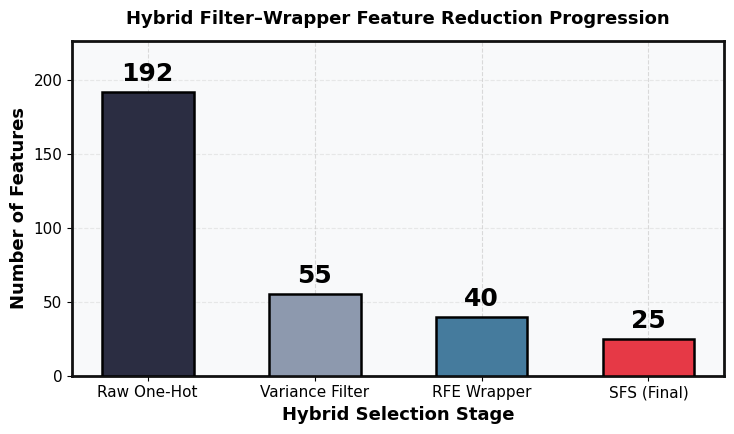


[✓] Step 5 Feature Selection Complete.


In [6]:
# Show the initial delimiter for the section on dimensionality reduction.
print("=" * 75)
# Recognize that the fifth step is a statistical and model-based variable selection.
print("[STEP 5] HYBRID FILTER–WRAPPER FEATURE SELECTION PIPELINE")
# Show the ending delimiter for the section header.
print("=" * 75)
# Record the starting timestamp to calculate the entire run time.
total_start_time = time.time()
# ------------------------------------------------------------------------------
# STAGE 1: FILTER METHOD — Variance Threshold
# ------------------------------------------------------------------------------
# Declare the first step where predictors with inadequate variance are filtered out.
print("\n--- [Stage 1/3] Variance Threshold Filter ---")
# Set a threshold dispersion value required to keep an input variable.
var_filter = VarianceThreshold(threshold=0.005)
# Assess predictor variance only using the training sample.
var_filter.fit(X_train_split)
# Get the list of variables meeting the stated dispersion criteria.
selected_var_cols = X_train_split.columns[var_filter.get_support()].tolist()
# Determine the number of predictors excluded in the first screening step.
removed_var_count = X_train_split.shape[1] - len(selected_var_cols)
# State the initial number of predictors.
print(f"  • Original Features     : {X_train_split.shape[1]}")
# State the number of predictors excluded due to inadequate variance.
print(f"  • Low-Variance Removed  : {removed_var_count}")
# State the number of predictors remaining after the first screening process.
print(f"  • Retained Features     : {len(selected_var_cols)}")
# Use the resulting set of variables consistently on the training sample.
X_train_stage1 = X_train_split[selected_var_cols]
# Use the same set of variables on the validation sample without reapplying the screening criteria.
X_val_stage1   = X_val_split[selected_var_cols]
# Use the same set of variables on the independent test sample without reapplying the screening criteria.
X_test_stage1  = X_test_encoded[selected_var_cols]
# ------------------------------------------------------------------------------
# STAGE 2: WRAPPER METHOD 1 — Recursive Feature Elimination (RFE)
# ------------------------------------------------------------------------------
# Initiate the second stage, where the predictors are ranked via model-based iterative elimination.
print("\n--- [Stage 2/3] Recursive Feature Elimination (RFE Wrapper) ---")

# Note the starting timestamp for evaluating the time needed to select the predictors.
rfe_start = time.time()

# Specify a tree-based classifier to compute the predictor importance in iterative elimination.
rfe_estimator = RandomForestClassifier(
    n_estimators=40, max_depth=10, random_state=RANDOM_SEED, n_jobs=-1
)
# Set the required number of selected variables to be 40 or less if there are fewer candidates.
n_target_rfe = min(40, len(selected_var_cols))
# Specify recursive elimination to drop five predictors per iteration to achieve the target number.
rfe_selector = RFE(estimator=rfe_estimator, n_features_to_select=n_target_rfe, step=5)
# Learn the predictor ranking only on the basis of the learning subset and its response labels.
rfe_selector.fit(X_train_stage1, y_train_split)
# Retrieve the names of predictors selected in the recursive elimination procedure.
selected_rfe_cols = X_train_stage1.columns[rfe_selector.get_support()].tolist()
# Return the number of selected predictors and the duration of the second stage.
print(f"  • Features Selected by RFE : {len(selected_rfe_cols)} (Elapsed: {time.time() - rfe_start:.2f}s)")
# Constrain the learning subset to the predictors selected in the second stage.
X_train_stage2 = X_train_stage1[selected_rfe_cols]
# Constrain the validation subset to the same set of predictors.
X_val_stage2   = X_val_stage1[selected_rfe_cols]
# Constrain the independent evaluation subset to the same set of predictors.
X_test_stage2  = X_test_stage1[selected_rfe_cols]
# ------------------------------------------------------------------------------
# STAGE 3: WRAPPER METHOD 2 — Sequential Feature Selector (SFS Forward)
# ------------------------------------------------------------------------------
# State the start of the third stage where the predictor subset is gradually constructed.
print("\n--- [Stage 3/3] Sequential Forward Selection (SFS Wrapper) ---")
# Note the beginning time stamp to determine the duration of the last selection stage.
sfs_start = time.time()
# Incorporate the standardization procedure and the linear classifier to learn scaling parameters separately in each cross-validation training fold.
sfs_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('lr', LogisticRegression(max_iter=1000, random_state=RANDOM_SEED, solver='lbfgs'))
])
# Restrict the search subset size to be 30,000 rows or the number of learning observations, whichever is smaller.
sfs_sample_size = min(30000, len(X_train_stage2))
# Choose a consistent random sample of row indexes to minimize computational burden.
sample_idx = np.random.RandomState(RANDOM_SEED).choice(len(X_train_stage2), sfs_sample_size, replace=False)
# Indicate the number of predictors desired for the reduced representation.
n_final_features = 25
# Set up predictor addition sequentially on the basis of cross-validated F1.
sfs_selector = SequentialFeatureSelector(
    estimator=sfs_pipeline, # Make sure scaling occurs separately within each cross-validation training fold.
    n_features_to_select=n_final_features,
    direction='forward',
    scoring='f1',
    cv=3,
    n_jobs=-1
)
# Find the selected predictor subset based on the sampled learning observations only.
# The combined pipeline performs standardization internally within each cross-validation training fold.
sfs_selector.fit(X_train_stage2.iloc[sample_idx], y_train_split.iloc[sample_idx])
# Obtain the names of the predictors selected in the last sequential selection stage.
final_selected_features = X_train_stage2.columns[sfs_selector.get_support()].tolist()
# Provide the predictor number and the duration of the third stage.
print(f"  • Final Features Selected by SFS : {len(final_selected_features)} (Elapsed: {time.time() - sfs_start:.2f}s)")

# ------------------------------------------------------------------------------
# 4. Final Feature Extraction (NO GLOBAL SCALING 
# ------------------------------------------------------------------------------
# Designate the last step for extracting the retained predictor features without global standardization.
# Print the starting delimiter for the last extraction part.
print("\n" + "-" * 75)
# Specify the step name and indicate that standardization will be performed separately within each model pipeline.
print("FINAL FEATURE EXTRACTION (Scaling Deferred to Model Pipelines)")
# Print the ending delimiter for the section header.
print("-" * 75)
# Extract the retained predictor features from the learning dataset without global standardization.
X_train_final = X_train_split[final_selected_features].copy()
# Extract the retained predictor features from the validation dataset without refitting transformations.
X_val_final = X_val_split[final_selected_features].copy()
# Extract the retained predictor features from the test dataset without refitting transformations.
X_test_final = X_test_encoded[final_selected_features].copy()
# Save the target labels of the learning dataset.
y_train_final = y_train_split.copy()
# Save the target labels of the validation dataset.
y_val_final   = y_val_split.copy()
# Save the target labels of the test dataset.
y_test_final  = y_test_raw.copy()
# Print the shape of the final learning dataset.
print(f"  • Final Training Matrix Shape   : {X_train_final.shape}")
# Print the shape of the final validation dataset.
print(f"  • Final Validation Matrix Shape : {X_val_final.shape}")
# Print the shape of the final test dataset.
print(f"  • Final Test Matrix Shape       : {X_test_final.shape}")
# Print the overall execution time for the entire feature selection process.
print(f"  • Total Selection Duration      : {time.time() - total_start_time:.2f} seconds")
# Print the header for the list of retained predictors.
print("\nFinal 25 Retained Features:")
# Print all retained predictors one-by-one in the retained order.
for i, f_name in enumerate(final_selected_features, 1):
    print(f"   {i:02d}. {f_name}")
# ------------------------------------------------------------------------------
# 5.  Visualization: Feature Reduction Progression Chart
# ------------------------------------------------------------------------------
# Define the successive selection steps used in tracking predictor dimensionality reduction.
stages = ['Raw One-Hot', 'Variance Filter', 'RFE Wrapper', 'SFS (Final)']
# Capture the predictor number remaining at each successive selection step.
counts = [X_train_split.shape[1], len(selected_var_cols), len(selected_rfe_cols), len(final_selected_features)]
# Create a plot surface using the predefined dimensions and background color.
fig, ax = plt.subplots(figsize=(7.5, 4.5), facecolor='white')
# Plot a bar chart of the predictor numbers per successive selection step.
bars = ax.bar(stages, counts, color=['#2B2D42', '#8D99AE', '#457B9D', '#E63946'], edgecolor='black', linewidth=1.8, width=0.55, zorder=3)
# Mark the predictor numbers at the corresponding bars for easy comparison.
for bar, val in zip(bars, counts):
    ax.text(bar.get_x() + bar.get_width()/2, val + 4, str(val),
            ha='center', va='bottom', fontsize=18, fontweight='bold', color='black')
# Set the y-axis range to allow enough clearance above the highest bar.
ax.set_ylim(0, max(counts) * 1.18)
# Label the y-axis as the number of predictors kept by the model.
ax.set_ylabel('Number of Features', fontsize=13, fontweight='bold')
# Label the x-axis as the number of successive selection steps used.
ax.set_xlabel('Hybrid Selection Stage', fontsize=13, fontweight='bold')
# Ensure that the grid lines do not overlap the chart elements.
ax.set_axisbelow(True)
# Include subtle reference lines to help compare the predictor numbers.
ax.grid(axis='y', linestyle='--', alpha=0.4)
# Create a header explaining the overall predictor reduction obtained via hybrid selection.
plt.title('Hybrid Filter–Wrapper Feature Reduction Progression', fontsize=13, fontweight='bold', pad=12)
# Arrange the chart appropriately to avoid clipping any chart elements.
plt.tight_layout()
# Show the completed chart illustrating predictor reduction.
plt.show()
print("\n" + "=" * 75)
print("[✓] Step 5 Feature Selection Complete.")
print("=" * 75)

# **MODEL TRAINING IMPLEMENTATION**

In [7]:
# Implement a comprehensive benchmarking function that assesses predictive accuracy and model efficiency.
# Take in the estimator, learning samples, validation samples, testing samples, model id, and maximum sample size per batch.
def evaluate_cyber_model_comprehensive(model, X_tr, y_tr, X_val, y_val, X_te, y_te, model_name="Model", n_jitter_batches=30):
    # Output the id of the estimator currently being evaluated.
    print(f"\n>> Benchmarking End-to-End: {model_name}...")

    # Note the start time prior to fitting in order to determine model fitting time.
    t_train_start = time.perf_counter()
    # Fit the estimator using the provided learning samples and associated labels.
    model.fit(X_tr, y_tr)
    # Note the end time after model fitting.
    t_train_end = time.perf_counter()
    # Determine the overall elapsed time used for model fitting.
    training_time_sec = t_train_end - t_train_start
    # Determine the predicted class labels for the validation samples.
    val_pred = model.predict(X_val)
    # Retrieve the probability of positive class prediction where available; otherwise, use predicted classes.
    val_prob = model.predict_proba(X_val)[:, 1] if hasattr(model, "predict_proba") else val_pred
    # Calculate the accuracy of the validation samples.
    v_acc = accuracy_score(y_val, val_pred)
    # Determine the precision score for predicting the positive class label.
    v_prec = precision_score(y_val, val_pred, zero_division=0)
    # Calculate the true positive rate, i.e., recall.
    v_rec = recall_score(y_val, val_pred, zero_division=0)
    # Compute the harmonic mean of the precision and recall.
    v_f1 = f1_score(y_val, val_pred, zero_division=0)
    # Determine the measure of agreement between predicted and observed validation labels using the Matthews correlation coefficient.
    v_mcc = matthews_corrcoef(y_val, val_pred)
    # Estimate the area under the receiver operating characteristic curve from validation scores.
    v_auc = roc_auc_score(y_val, val_prob)
    # Measure time taken for independent evaluation, including any transformations that are done in the estimator pipeline.
    t_test_start = time.perf_counter()
    # Make predictions for the independent test observations.
    test_pred = model.predict(X_te)
    # Measure time stamp for the end of the independent inference process.
    t_test_end = time.perf_counter()
    # Measure time taken for processing the entire test data set.
    total_infer_time = t_test_end - t_test_start
    # Get the probability estimates for the positive class for independent evaluation if available from the estimator.
    test_prob = model.predict_proba(X_te)[:, 1] if hasattr(model, "predict_proba") else test_pred
    # Measure accuracy for the independent test data set.
    t_acc = accuracy_score(y_te, test_pred)
    # Measure precision for the independent test data set belonging to the positive class.
    t_prec = precision_score(y_te, test_pred, zero_division=0)
    # Measure the true positive rate (TPR) of the independent test data set.
    t_rec = recall_score(y_te, test_pred, zero_division=0)
    # Measure F-score or harmonic mean of precision and recall for the independent test data set.
    t_f1 = f1_score(y_te, test_pred, zero_division=0)
    # Measure the concordance between predictions and true labels using the Matthews correlation coefficient.
    t_mcc = matthews_corrcoef(y_te, test_pred)
    # Measure the ROC-AUC for the independent test predictions.
    t_auc = roc_auc_score(y_te, test_prob)
    # Calculate processing throughput as the number of analyzed observations per second.
    throughput_fps = len(X_te) / total_infer_time
    # Calculate average time per observation needed for inference and translate the value into microseconds.
    mean_latency_us = (total_infer_time / len(X_te)) * 1e6
    # Set up the configuration for measuring batch-based inference time variability.
    batch_size = 1000
    # Set up an empty collection for storing batch latencies for each individual observation.
    batch_latencies = []
    # Calculate the total number of observations that could be used for batch-based analysis.
    n_samples = len(X_te)
    # Process the whole batches until the limit set up in the configuration is reached.
    for i in range(min(n_jitter_batches, n_samples // batch_size)):
        # Collect the current batch of observations by positional indexing.
        batch_slice = X_te.iloc[i * batch_size : (i + 1) * batch_size]
        # Set the initial timestamp prior to analyzing the current batch.
        t_b_start = time.perf_counter()
        # Analyze the selected batch in order to estimate its processing time.
        _ = model.predict(batch_slice)
        # Define the end timestamp after batch analysis has been completed.
        t_b_end = time.perf_counter()
        # Translate the batch processing time into average microseconds per observation.
        batch_latency_us = ((t_b_end - t_b_start) / batch_size) * 1e6
        # Store the measured latency for subsequent variability analysis.
        batch_latencies.append(batch_latency_us)
    # Compute latency variability among recorded batches, reporting zero in case there are not enough measurements.
    jitter_us = float(np.std(batch_latencies)) if len(batch_latencies) > 1 else 0.
    # Aggregate estimator identifier, measures of computational efficiency, performance on validation, performance on test data set, and predictions.
    metrics = {

        # Preserve estimator identifier for later comparison among tested algorithms.
        "Model": model_name,
        # Register the time in seconds needed to fit the model.
        "Train_Time_s": round(training_time_sec, 2),
        # Register the estimated throughput in observations per second.
        "Throughput_fps": round(throughput_fps, 1),
        # Register average latency in microseconds per observation.
        "Latency_us": round(mean_latency_us, 2),
        # Register standard deviation of measured latencies in batches as jitter estimate.
        "Jitter_us": round(jitter_us, 2),
        # Register accuracy, precision, recall, F1, MCC, and ROC-AUC on validation data set.
        "Val_Acc": v_acc, "Val_Prec": v_prec, "Val_Rec": v_rec,
        "Val_F1": v_f1, "Val_MCC": v_mcc, "Val_AUC": v_auc,
        # Register independent accuracy, precision, recall, F1, MCC, and ROC-AUC on test data set.
        "Test_Acc": t_acc, "Test_Prec": t_prec, "Test_Rec": t_rec,
        "Test_F1": t_f1, "Test_MCC": t_mcc, "Test_AUC": t_auc,
        # Persist validation predictions along with positive class scores.
        "y_val_pred": val_pred, "y_val_prob": val_prob,
        # Persist test predictions along with positive class scores.
        "y_test_pred": test_pred, "y_test_prob": test_prob
    }
    # Present the training time, throughput, average latency, and batch jitter as obtained.
    print(f"   [✓] Fitted in {training_time_sec:.2f}s | Throughput: {throughput_fps:,.1f} flows/s | Latency: {mean_latency_us:.2f}μs | Jitter: {jitter_us:.2f}μs")
    # Show the test set accuracy, F1-score, and ROC-AUC to provide an evaluation summary.
    print(f"       Test Accuracy: {t_acc:.4f} | Test F1-Score: {t_f1:.4f} | Test ROC-AUC: {t_auc:.4f}")
    # Provide the evaluation results along with the trained estimator.
    return metrics, model

# **BASE MODELS & MODEL 1 (HESN)**

In [8]:
print("=" * 85)
print("[STEP 6 ] COMPUTATIONAL BENCHMARKING ENGINE & MODEL 1 (HESN)")
print("=" * 85)

# ------------------------------------------------------------------------------
# 2. Standalone Base Models Instantiation (Leak-Free Pipelines)
# ------------------------------------------------------------------------------
# Create the pipeline of preprocessing followed by each standalone classifier to guarantee uniform preprocessing of inputs.
# Set up the baseline ensemble classifiers with appropriate parameters and random states.
models_to_evaluate = [
    ("Random Forest (Baseline)", make_pipeline(StandardScaler(), RandomForestClassifier(n_estimators=80, max_depth=8, random_state=RANDOM_SEED, n_jobs=-1))),
    ("XGBoost (Baseline)", make_pipeline(StandardScaler(), XGBClassifier(n_estimators=80, max_depth=6, learning_rate=0.1, random_state=RANDOM_SEED, eval_metric='logloss', n_jobs=-1))),
    ("LightGBM (Baseline)", make_pipeline(StandardScaler(), LGBMClassifier(n_estimators=80, learning_rate=0.1, num_leaves=25, random_state=RANDOM_SEED, n_jobs=-1, verbose=-1))),
    ("CatBoost (Baseline)", make_pipeline(StandardScaler(), CatBoostClassifier(iterations=80, learning_rate=0.1, depth=8, random_state=RANDOM_SEED, verbose=0)))
]
# Create an empty container to save all performance metrics and benchmarking results.
all_evaluation_records = []
# Create an empty dictionary to store the fitted estimators for further analysis.
fitted_estimators_dict = {}
# Test each configured classifier on the learning, validation, and independent test datasets.
for m_name, clf in models_to_evaluate:
    # Obtain the benchmarking results along with the fitted estimator from the benchmarking procedure.
    res, fitted_m = evaluate_cyber_model_comprehensive(
        clf, X_train_final, y_train_final, X_val_final, y_val_final, X_test_final, y_test_final, model_name=m_name
    )
    # Save all obtained metrics in the single container for further comparison.
    all_evaluation_records.append(res)
    # Store the obtained fitted estimator with its identifier in the dictionary.
    fitted_estimators_dict[m_name] = fitted_m
# ------------------------------------------------------------------------------
# 3. MODEL 1: Hybrid Ensemble Stacking Network (HESN)
# ------------------------------------------------------------------------------
# Exhibit the starting delimiter for the development and training of the first hybrid ensemble model.
print("\n" + "-" * 85)
# Name the first proposed architecture the Hybrid Ensemble Stacking Network (HESN).
print("CONSTRUCTING & TRAINING MODEL 1: HYBRID ENSEMBLE STACKING NETWORK (HESN)")
# Exhibit the ending delimiter for the section heading.
print("-" * 85)
# Set up the base classifiers as pipelines for ensuring that there is fold-wise standardization during internal cross-validation.
# Avoid out-of-fold leakage by fitting scaling parameters on each internal training fold before transforming its corresponding held-out fold.
# Specify the Random Forest, XGBoost, and LightGBM base models along with their respective hyperparameters and random states.
hesn_base_learners = [
    ('rf', make_pipeline(StandardScaler(), RandomForestClassifier(n_estimators=100, max_depth=10, random_state=RANDOM_SEED, n_jobs=-1))),
    ('xgb', make_pipeline(StandardScaler(), XGBClassifier(n_estimators=100, max_depth=6, learning_rate=0.1, random_state=RANDOM_SEED, eval_metric='logloss', n_jobs=-1))),
    ('lgbm', make_pipeline(StandardScaler(), LGBMClassifier(n_estimators=100, learning_rate=0.1, random_state=RANDOM_SEED, n_jobs=-1, verbose=-1)))
]
# Specify logistic regression as the meta-classifier to aggregate predictions from the base classifiers.
hesn_meta_learner = LogisticRegression(max_iter=1000, random_state=RANDOM_SEED)
# Set up the stacking classifier using the specified base learners and logistic regression meta-classifier.
model_1_hesn = StackingClassifier(
    estimators=hesn_base_learners,
    final_estimator=hesn_meta_learner,
    # Perform five-fold cross-validation to get the out-of-fold predictions for training the meta-learner.
    cv=5,
    # Use parallelization to speed up computations.
    n_jobs=-1,
    # Do not include the original feature variables in the meta-learner but use base-learner predictions instead.
    passthrough=False
)
# Benchmark the stacking architecture using the learning, validation, and independent test datasets.
# Gather the evaluation metrics and the fitted stacking classifier from the benchmarking function.
res_hesn, fitted_hesn = evaluate_cyber_model_comprehensive(
    model_1_hesn, X_train_final, y_train_final, X_val_final, y_val_final, X_test_final, y_test_final,
    model_name="Model 1: HESN (Stacking)"
)
# Add the stacking model's metrics to the evaluation records.
all_evaluation_records.append(res_hesn)
# Save the trained stacking estimator using its assigned identifier for later analysis.
fitted_estimators_dict["Model 1: HESN"] = fitted_hesn
# ------------------------------------------------------------------------------
# 4. Master Comparative Tables Generation
# ------------------------------------------------------------------------------
# Transform the data of evaluations into a tabular form for further comparison.
results_df = pd.DataFrame(all_evaluation_records)
# Extract the computational efficiency criteria and prepare descriptive column names for them.
comp_table = results_df[["Model", "Train_Time_s", "Throughput_fps", "Latency_us", "Jitter_us"]].copy()
# Rename the required fields into descriptive names with appropriate measurement units.
comp_table.columns = ["Model Architecture", "Train Time (s)", "Throughput (flows/s)", "Latency (μs/flow)", "Jitter (μs)"]
# Extract the independent evaluation criteria for comparing classification performance of models.
test_table = results_df[["Model", "Test_Acc", "Test_Prec", "Test_Rec", "Test_F1", "Test_MCC", "Test_AUC"]].copy()
# Provide standardized headings for the independent evaluation criteria.
test_table.columns = ["Model Architecture", "Accuracy", "Precision", "Recall", "F1-Score", "MCC", "ROC-AUC"]
# Extract validation criteria for comparing model prediction performance.
val_table = results_df[["Model", "Val_Acc", "Val_Prec", "Val_Rec", "Val_F1", "Val_MCC", "Val_AUC"]].copy()
# Provide standardized headings for the validation performance criteria.
val_table.columns = ["Model Architecture", "Accuracy", "Precision", "Recall", "F1-Score", "MCC", "ROC-AUC"]
# Print the beginning delimiter for the computational efficiency report.
print("\n" + "=" * 95)
# Identify the first table as a summary of computational performance and resources consumption.
print("TABLE 1: COMPUTATIONAL RESOURCE & REAL-TIME PERFORMANCE PROFILING")
# Print the ending delimiter for the table heading.
print("=" * 95)
# Print the computational benchmarking results without row indices.
print(comp_table.to_string(index=False))
# Print the beginning delimiter for the independent evaluation report.
print("\n" + "=" * 95)
# Identify the second table as a comparison of classification performance on new observations.
print("TABLE 2: CLASSIFICATION PERFORMANCE ON INDEPENDENT TEST PARTITION")
# Print the ending delimiter for the table heading.
print("=" * 95)
# Print the independent evaluation criteria with values rounded to five decimal places.
print(test_table.to_string(index=False, float_format=lambda x: f"{x:.5f}"))
# Print the beginning delimiter for the validation performance report.
print("\n" + "=" * 95)
# Identify the third table as a comparison of classification performance on validation observations.
print("TABLE 3: CLASSIFICATION PERFORMANCE ON VALIDATION PARTITION")
# Print the ending delimiter for the table heading.
print("=" * 95)
# Print the validation performance criteria with values rounded to five decimal places.
print(val_table.to_string(index=False, float_format=lambda x: f"{x:.5f}"))
print("=" * 95)
print("\n[✓] Step 6 Complete. Leak-free Base Models and Model 1 (HESN) Benchmarked Successfully.")

[STEP 6 ] COMPUTATIONAL BENCHMARKING ENGINE & MODEL 1 (HESN)

>> Benchmarking End-to-End: Random Forest (Baseline)...
   [✓] Fitted in 3.74s | Throughput: 680,158.4 flows/s | Latency: 1.47μs | Jitter: 0.86μs
       Test Accuracy: 0.8146 | Test F1-Score: 0.8555 | Test ROC-AUC: 0.9666

>> Benchmarking End-to-End: XGBoost (Baseline)...
   [✓] Fitted in 0.77s | Throughput: 1,050,539.1 flows/s | Latency: 0.95μs | Jitter: 0.25μs
       Test Accuracy: 0.8521 | Test F1-Score: 0.8789 | Test ROC-AUC: 0.9735

>> Benchmarking End-to-End: LightGBM (Baseline)...
   [✓] Fitted in 1.02s | Throughput: 632,069.9 flows/s | Latency: 1.58μs | Jitter: 0.61μs
       Test Accuracy: 0.8590 | Test F1-Score: 0.8834 | Test ROC-AUC: 0.9746

>> Benchmarking End-to-End: CatBoost (Baseline)...
   [✓] Fitted in 2.34s | Throughput: 1,660,435.9 flows/s | Latency: 0.60μs | Jitter: 0.12μs
       Test Accuracy: 0.8537 | Test F1-Score: 0.8798 | Test ROC-AUC: 0.9728

----------------------------------------------------------

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


   [✓] Fitted in 49.51s | Throughput: 214,767.3 flows/s | Latency: 4.66μs | Jitter: 2.45μs
       Test Accuracy: 0.8637 | Test F1-Score: 0.8861 | Test ROC-AUC: 0.9738

TABLE 1: COMPUTATIONAL RESOURCE & REAL-TIME PERFORMANCE PROFILING
      Model Architecture  Train Time (s)  Throughput (flows/s)  Latency (μs/flow)  Jitter (μs)
Random Forest (Baseline)            3.74              680158.4               1.47         0.86
      XGBoost (Baseline)            0.77             1050539.1               0.95         0.25
     LightGBM (Baseline)            1.02              632069.9               1.58         0.61
     CatBoost (Baseline)            2.34             1660435.9               0.60         0.12
Model 1: HESN (Stacking)           49.51              214767.3               4.66         2.45

TABLE 2: CLASSIFICATION PERFORMANCE ON INDEPENDENT TEST PARTITION
      Model Architecture  Accuracy  Precision  Recall  F1-Score     MCC  ROC-AUC
Random Forest (Baseline)   0.81462    0.74927 0.

### **Visualizations for MODEL 1: Confusion Matrix & ROC Curve**

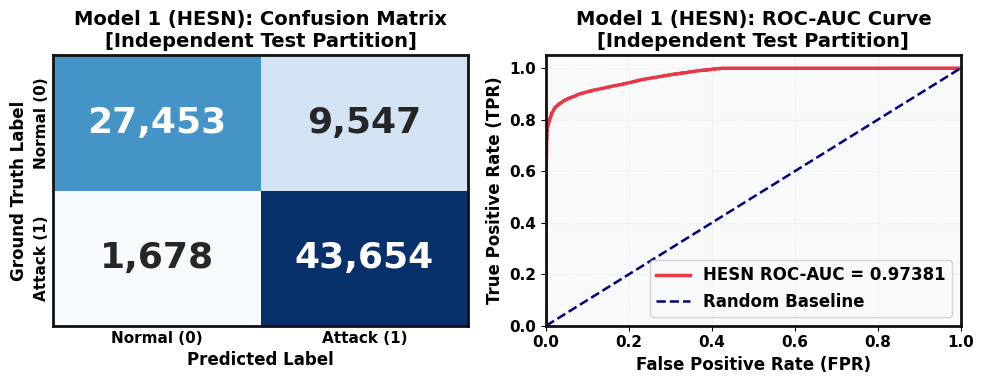

In [9]:
# Builds a two-pane figure for assessment of the designed architecture via complementary visual diagnostic tools.
fig, axes = plt.subplots(1, 2, figsize=(10, 4), facecolor='white')
# Calculates the classification error matrix based on the independent evaluation set predictions.
cm_hesn = confusion_matrix(y_test_final, res_hesn['y_test_pred'])
# Shows the classification error matrix with marked observation numbers and labeled outcomes.
sns.heatmap(cm_hesn, ax=axes[0], annot=True, fmt=',d', cmap='Blues',
            xticklabels=['Normal (0)', 'Attack (1)'], yticklabels=['Normal (0)', 'Attack (1)'],
            annot_kws={"size": 26, "weight": "bold"}, cbar=False,
            linewidths=0)
# Erases any artifacts remaining on the edges of the cells in the matrix form.
axes[0].collections[0].set_edgecolor('face')
# Adds the title to the classification error matrix.
axes[0].set_title('Model 1 (HESN): Confusion Matrix\n[Independent Test Partition]', fontsize=14, fontweight='bold')
# Specifies the description of the horizontal axis of predicted outcomes.
axes[0].set_xlabel('Predicted Label', fontsize=12, fontweight='bold')
# Specifies the description of the vertical axis of observed outcomes.
axes[0].set_ylabel('Ground Truth Label', fontsize=12, fontweight='bold')
# Formats the academic border for the classification matrix.
apply_plot_border(axes[0])
# Improves the typography of the matrix axis labels.
make_ticks_bold(axes[0])
# Omits the background reference lines of the classification matrix.
axes[0].grid(False)
# Omits the ticks from the matrix.
axes[0].tick_params(length=0)
# Computes false and true positive rates along classification cutoff points.
fpr_hesn, tpr_hesn, _ = roc_curve(y_test_final, res_hesn['y_test_prob'])
# Plots receiver operating characteristic curve of the suggested architecture with its area.
axes[1].plot(fpr_hesn, tpr_hesn, color='#E63946', lw=2.5, label=f'HESN ROC-AUC = {res_hesn["Test_AUC"]:.5f}')
# Plots the line indicating reference performance, which is random classification.
axes[1].plot([0, 1], [0, 1], color='navy', lw=1.8, linestyle='--', label='Random Baseline')
# Sets the horizontal viewing window for the receiver operating characteristic curve.
axes[1].set_xlim([0.0, 1.0])
# Sets the vertical viewing window for the receiver operating characteristic curve.
axes[1].set_ylim([0.0, 1.05])
# Places label on the horizontal axis of the receiver operating characteristic plot using false positive rate measure.
axes[1].set_xlabel('False Positive Rate (FPR)', fontsize=12, fontweight='bold')
# Places label on the vertical axis of the receiver operating characteristic plot using true positive rate measure.
axes[1].set_ylabel('True Positive Rate (TPR)', fontsize=12, fontweight='bold')
# Assigns header to the receiver operating characteristic analysis.
axes[1].set_title('Model 1 (HESN): ROC-AUC Curve\n[Independent Test Partition]', fontsize=14, fontweight='bold')
# Adds a legend to identify receiver operating characteristic lines.
axes[1].legend(loc="lower right", frameon=True, prop={'weight': 'bold', 'size': 12})
# Uses light grid lines for better visual understanding of the receiver operating characteristic curves.
axes[1].grid(True, linestyle=':', alpha=0.35)
# Formats receiver operating characteristic panel according to the academic style border definition.
apply_plot_border(axes[1])
# Improves receiver operating characteristic axis labeling typography.
make_ticks_bold(axes[1])
# Fixes distance between both panels to avoid overlapping.
plt.tight_layout()
# Saves the evaluation figure to the file according to the predefined high resolution.
plt.savefig('plot_8_model_1_hesn_evaluation.png', **SAVE_OPTS)
# Shows the evaluation figure in the notebook environment.
plt.show()

# **MODEL 2 — DEEP ATTENTION-BASED CNN-BiLSTM NETWORK (DACBN) HYBRID STACK**

In [10]:
print("=" * 85)
print("[STEP 8] CONSTRUCTING & TRAINING MODEL 2: DACBN HYBRID STACK")
print("=" * 85)

# ------------------------------------------------------------------------------
# 1. Custom Attention Layer Definition
# ------------------------------------------------------------------------------
# Registers the custom attention layer with Keras to support saving and loading.
@tf.keras.utils.register_keras_serializable(package="Custom")
class SimpleAttention(Layer):
    """
    Computes Bahdanau-style self-attention over the sequence dimensions
    emitted by the preceding recurrent layer.
    """
    # Instantiates the custom layer by utilizing the configurations passed to the superclass.
    def __init__(self, **kwargs):
        # Configures the layer by passing all keyword arguments to the base layer constructor.
        super(SimpleAttention, self).__init__(**kwargs)
    # Defines the parameters for calculating the alignment score between the sequence representations.
    def build(self, input_shape):
        # The weight matrix transforms the sequence representation to scalar alignment scores.
        self.W = self.add_weight(
            name="att_weight",
            shape=(input_shape[-1], 1),
            # Applies Glorot uniform initialization for the attention projections.
            initializer="glorot_uniform",
            # Enables optimization of the attention projections through gradient descent.
            trainable=True
        )
        # Creates the bias vector containing one entry per sequence position.
        self.b = self.add_weight(
            name="att_bias",
            shape=(input_shape[1], 1),
            # Initializes the biases with zeros.
            initializer="zeros",
            trainable=True
        )
        # Completes the creation of the layer parameters using the shape of the input tensor.
        super(SimpleAttention, self).build(input_shape)
    # Calculates the nonlinear alignment scores of the sequence representations.
    def call(self, x):
        # Uses the hyperbolic tangent to bound the alignment scores.
        e = K.tanh(K.dot(x, self.W) + self.b)
        # Removes the final singleton dimension from the alignment scores.
        e = K.squeeze(e, axis=-1)
        # Calculates the attention weights based on the nonlinear alignment scores.
        # Uses softmax to normalize the scores to weights in the [0,1] range.
        alpha = K.softmax(e)
        # Adds back the last singleton dimension in order to multiply with the input sequence representations.
        alpha = K.expand_dims(alpha, axis=-1)
        # Calculates the weighted sequence representation based on attention weights.
        context = x * alpha
        # Sum up the weighted representations along the sequence axis to generate the context vector.
        return K.sum(context, axis=1)
    # Provide the configuration needed for recreating the custom module when loading the model.
    def get_config(self):
        # Obtain the configuration of the inherited module and keep it for serialization purposes.
        config = super(SimpleAttention, self).get_config()
        return config


# ------------------------------------------------------------------------------
# 2. Sequential Deep CNN-BiLSTM-Attention Model Factory
# ------------------------------------------------------------------------------
# Function to create a deep learning sequence classifier based on convolution, recurrent modeling, attention, and fully connected layers.
def create_complex_dl_model(input_dim):
    """
    # Describe the sequence-based architecture starting from feature extraction up to binary classification.
    """
    # Set the input dimensionality needed to build the architecture.
    # Define the input tensor with an extra channel axis for one-dimensional convolution.
    inputs = Input(shape=(input_dim, 1))  # Reshaped for spatial 1D convolutions
    # Stage 1: Local Feature Extraction
    # Apply one-dimensional convolution to find local features of the sequence.
    x = Conv1D(filters=64, kernel_size=3, activation='relu', padding='same')(inputs)
    # Normalize the activations to ensure proper training and model convergence.
    x = BatchNormalization()(x)
    # Reduce the sequence length while keeping the important local activations.
    x = MaxPooling1D(pool_size=2)(x)
    # Stage 2: Bidirectional Recurrent Context Modeling
    # Apply bidirectional LSTM layers to capture long-term dependencies in both directions of the sequence.
    x = Bidirectional(LSTM(64, return_sequences=True))(x)
    # Add dropout regularization to avoid overfitting of the model.
    x = Dropout(0.3)(x)
    # Stage 3: Attention-Based Representation
    # Apply the customized attention mechanism to weigh the sequence representations.
    x = SimpleAttention()(x)
    # Stage 4: Fully Connected Classification
    # Map the context representation to a new nonlinear feature space.
    x = Dense(64, activation='relu')(x)
    # Regularize the hidden representation by dropout to avoid overfitting.
    x = Dropout(0.2)(x)
    # Generate a probability for the positive class using a sigmoid activation.
    outputs = Dense(1, activation='sigmoid')(x)
    # Combine the input and output tensors to form a functional Keras model.
    model = models.Model(inputs, outputs)
    # Configure the model using the needed optimizer, loss, and metric.
    model.compile(
        # Use Adam optimizer for optimization of the parameters.
        optimizer='adam',
        # Binary cross entropy as the loss function for measuring error.
        loss='binary_crossentropy',
        # Monitor classification performance during training and validation.
        metrics=['accuracy']
    )
    # Return the compiled deep learning model for further training and validation.
    return model
# ------------------------------------------------------------------------------
# 3. Keras-to-Scikit-Learn Estimator Interface Wrapper
#    Proper classes_, get_tags, and robust array handling
# ------------------------------------------------------------------------------
# Create a scikit-learn-compatible wrapper for a custom deep learning classifier.
# Explicitly identify the wrapper as a classification estimator.
# Inherit from the base estimator and classifier mixin to follow scikit-learn conventions.
class ComplexDLWrapper(BaseEstimator, ClassifierMixin):
    _estimator_type = "classifier"

    # Initialize the input dimensions, training duration, and batch size.
    def __init__(self, input_dim=25, epochs=8, batch_size=512):
        # Store the expected number of input features.
        self.input_dim = input_dim
        # Store the number of training epochs.
        self.epochs = epochs
        # Store the number of training samples processed per batch.
        self.batch_size = batch_size
        # Initialize the neural network as unavailable until training.
        self.model = None
        # Set the default class labels for binary classification.
        self.classes_ = np.array([0, 1])

    # Convert the input observations into a NumPy array with a consistent data type.
    def _to_numpy(self, X):
        # Check whether the input provides a DataFrame-like values attribute.
        if hasattr(X, 'values'):
            # Extract the underlying values and convert them to 32-bit floating-point numbers.
            return np.asarray(X.values, dtype=np.float32)
        # Convert other supported input objects directly into a NumPy array.
        return np.asarray(X, dtype=np.float32)

    # Reshape the input matrix into the three-dimensional format required by the convolutional network.
    def _reshape(self, X):
        # Convert the supplied observations into a numerical matrix.
        X_np = self._to_numpy(X)
        # Add a channel dimension while preserving the sample and feature dimensions.
        return X_np.reshape(X_np.shape[0], X_np.shape[1], 1)

    # Train the wrapped neural network using the supplied observations and target labels.
    def fit(self, X, y):
        # Convert the input observations into a numerical array.
        X_np = self._to_numpy(X)
        # Convert the target labels into a one-dimensional array.
        y_np = np.asarray(y).ravel()
        # Identify the distinct class labels in the training targets.
        self.classes_ = np.unique(y_np)
        # Update the network input dimension based on the training features.
        self.input_dim = X_np.shape[1]
        # Create a new neural network using the determined input dimension.
        self.model = create_complex_dl_model(self.input_dim)
        # Reshape the training observations to match the neural network's input format.
        X_reshaped = self._reshape(X_np)
        # Train the network using the configured epochs and batch size without displaying training logs.
        self.model.fit(X_reshaped, y_np, epochs=self.epochs, batch_size=self.batch_size, verbose=0)
        # Return the trained wrapper to support method chaining.
        return self

    # Estimate class probabilities for the supplied observations.
    def predict_proba(self, X):
        # Convert the observations into a shape compatible with the neural network.
        X_reshaped = self._reshape(X)
        # Obtain the predicted positive-class probabilities from the trained network.
        probs = self.model.predict(X_reshaped, verbose=0)
        # Construct a two-column array containing negative-class and positive-class probabilities.
        return np.hstack([1.0 - probs, probs])

    # Generate discrete class predictions for the supplied observations.
    def predict(self, X):
        # Obtain the estimated class probabilities from the fitted neural network.
        proba = self.predict_proba(X)
        # Select the class associated with the maximum probability for each observation.
        return self.classes_[np.argmax(proba, axis=1)]
# ------------------------------------------------------------------------------
# 4. Building and Training Model 2: Advanced Hybrid Stacking Ensemble
#  Every base learner wrapped in StandardScaler pipeline
# so Stacking internal CV fits scaler fold-wise → zero OOF scaling leakage.
# ------------------------------------------------------------------------------
print("\nInitializing Advanced Hybrid Stacking base learners (leak-free pipelines)...")

dacbn_base_learners = [
    (
        'xgb',
        make_pipeline(
            StandardScaler(),
            XGBClassifier(
                n_estimators=200,
                max_depth=6,
                learning_rate=0.1,
                random_state=RANDOM_SEED,
                eval_metric='logloss',
                n_jobs=-1
            )
        )
    ),
    (
        'lgbm',
        make_pipeline(
            StandardScaler(),
            LGBMClassifier(
                n_estimators=200,
                learning_rate=0.1,
                num_leaves=31,
                random_state=RANDOM_SEED,
                n_jobs=-1,
                verbose=-1
            )
        )
    ),
    (
        'dacbn_deep',
        make_pipeline(
            StandardScaler(),   # DL also receives fold-wise scaled inputs
            ComplexDLWrapper(
                input_dim=X_train_final.shape[1],
                epochs=8,
                batch_size=512
            )
        )
    )
]
# Initialize the logistic regression meta-learner for aggregating predictions of the base learners.
# Define the maximum number of optimization iterations and use a predefined seed value for random state.
dacbn_meta_learner = LogisticRegression(max_iter=1000, random_state=RANDOM_SEED)
# Create the DACBN stacking model based on the set of base learners and the meta-learner.
model_2_stack = StackingClassifier(
    estimators=dacbn_base_learners,
    final_estimator=dacbn_meta_learner,
    # Train the meta-learner via five-fold cross-validation on out-of-fold predictions.
    cv=5,
    # Disable parallel processing using the default single-process execution option.
    n_jobs=None
)
# Train and evaluate the performance of Model 2 on the training, validation, and independent test sets.
# Collect the scores and fitted stacking model.
res_model2, fitted_model2 = evaluate_cyber_model_comprehensive(
    model_2_stack,
    X_train_final, y_train_final,
    X_val_final, y_val_final,
    X_test_final, y_test_final,
    model_name="Model 2: DACBN (Hybrid Stack)"
)
# Store the model's performance scores for the purpose of comparison with other models.
all_evaluation_records.append(res_model2)
# Store the DACBN fitted model in the estimator dictionary.
fitted_estimators_dict["Model 2: DACBN"] = fitted_model2
# ------------------------------------------------------------------------------
# 1. Tabular Comparison: Validation vs. Independent Test Set
# ------------------------------------------------------------------------------
# Creates a performance comparison table for Model 2 using the validation and independent test partitions.
model2_comparison_df = pd.DataFrame([
    # Stores the classification performance metrics obtained from the validation partition.
    {
        "Partition": "Validation Partition (35,069 samples)",
        "Accuracy": res_model2["Val_Acc"],
        "Precision": res_model2["Val_Prec"],
        "Recall": res_model2["Val_Rec"],
        "F1-Score": res_model2["Val_F1"],
        "MCC": res_model2["Val_MCC"],
        "ROC-AUC": res_model2["Val_AUC"]
    },
    # Stores the classification performance metrics obtained from the independent test partition.
    {
        "Partition": "Independent Test Partition (82,332 samples)",
        "Accuracy": res_model2["Test_Acc"],
        "Precision": res_model2["Test_Prec"],
        "Recall": res_model2["Test_Rec"],
        "F1-Score": res_model2["Test_F1"],
        "MCC": res_model2["Test_MCC"],
        "ROC-AUC": res_model2["Test_AUC"]
    }
])
# Displays the heading of the performance summary table for Model 2.
print("\n--- Summary Performance Table ---")
# Displays the performance measures for the validation and independent test partitions.
print(model2_comparison_df.to_string(index=False, float_format=lambda x: f"{x:.5f}"))
# ------------------------------------------------------------------------------
# 2. Computational & Real-Time Profiling Summary
# ------------------------------------------------------------------------------
# Shows the heading for the computational efficiency profiling results.
print("\n--- Computational Efficiency Profiling ---")
# Shows the total time taken for model training, including validation and final training.
print(f"  • Training Time (CV + Fit)  : {res_model2['Train_Time_s']:.2f} seconds")
# Shows the inference throughput in terms of number of flows per second.
print(f"  • Throughput                : {res_model2['Throughput_fps']:,.1f} flows/sec")
# Shows the average inference latency to process one network flow.
print(f"  • Mean Inference Latency    : {res_model2['Latency_us']:.2f} μs/flow")
# Shows the standard deviation of inference latency for the measurement batches.
print(f"  • Latency Jitter (Std Dev)  : {res_model2['Jitter_us']:.2f} μs")
# ------------------------------------------------------------------------------
# 3. Detailed Classification Reports (Validation & Test)
# ------------------------------------------------------------------------------
# Separates the output of classification report from the validation partition.
print("\n" + "-" * 90)
# The heading of the classification report on the validation partition is printed here.
print("CLASSIFICATION REPORT — VALIDATION PARTITION")
# A separator is generated below the heading of the validation classification report.
print("-" * 90)
# Prints detailed metrics of the validation classification report for normal and attack classes.
print(classification_report(y_val_final, res_model2["y_val_pred"], target_names=['Normal (0)', 'Attack (1)'], digits=5))
# A separator is created before the classification report of the independent test partition.
print("\n" + "-" * 90)
# The heading of the classification report on the independent benchmark test partition is printed here.
print("CLASSIFICATION REPORT — INDEPENDENT BENCHMARK TEST PARTITION")
# A separator is generated below the heading of the independent test classification report.
print("-" * 90)
# Prints detailed metrics of the independent test classification report for normal and attack classes.
print(classification_report(y_test_final, res_model2["y_test_pred"], target_names=['Normal (0)', 'Attack (1)'], digits=5))
print("=" * 90)
print("\n[✓] Step 8 Complete — Model 2 DACBN trained with fold-wise scaling .")

[STEP 8] CONSTRUCTING & TRAINING MODEL 2: DACBN HYBRID STACK

Initializing Advanced Hybrid Stacking base learners (leak-free pipelines)...

>> Benchmarking End-to-End: Model 2: DACBN (Hybrid Stack)...


I0000 00:00:1792037018.044945      48 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792037018.046543      48 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


   [✓] Fitted in 164.07s | Throughput: 9,875.1 flows/s | Latency: 101.26μs | Jitter: 12.87μs
       Test Accuracy: 0.8681 | Test F1-Score: 0.8891 | Test ROC-AUC: 0.9743

--- Summary Performance Table ---
                                  Partition  Accuracy  Precision  Recall  F1-Score     MCC  ROC-AUC
      Validation Partition (35,069 samples)   0.95589    0.96500 0.97038   0.96768 0.89825  0.99274
Independent Test Partition (82,332 samples)   0.86808    0.82765 0.96040   0.88910 0.74087  0.97432

--- Computational Efficiency Profiling ---
  • Training Time (CV + Fit)  : 164.07 seconds
  • Throughput                : 9,875.1 flows/sec
  • Mean Inference Latency    : 101.26 μs/flow
  • Latency Jitter (Std Dev)  : 12.87 μs

------------------------------------------------------------------------------------------
CLASSIFICATION REPORT — VALIDATION PARTITION
------------------------------------------------------------------------------------------
              precision    recall  f1-s

### **Visualizing for MODEL 2: Confusion Matrix & ROC Curve**

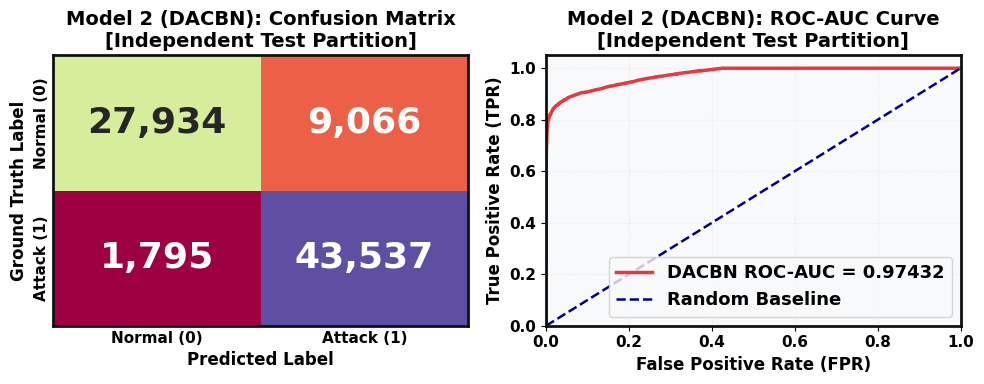


[✓] Model 2 Training, Prediction, Metric-Verification & Plot-Generation Complete.


In [11]:
# Constructs a two-panel chart for assessment of the second proposed architecture based on supplementary visualization diagnostics.
fig, axes = plt.subplots(1, 2, figsize=(10, 4), facecolor='white')
# Determines the classification error matrix based on the predicted values produced by the second proposed architecture.
cm_dacbn = confusion_matrix(y_test_final, res_model2['y_test_pred'])
# Presents the classification error matrix together with observation numbers and properly labeled outcomes.
sns.heatmap(cm_dacbn, ax=axes[0], annot=True, fmt=',d', cmap='Spectral',
            xticklabels=['Normal (0)', 'Attack (1)'], yticklabels=['Normal (0)', 'Attack (1)'],
            annot_kws={"size": 26, "weight": "bold"}, cbar=False,
            linewidths=0)
# Eliminates remaining artifacts at the edges of neighboring cells in the matrix.
axes[0].collections[0].set_edgecolor('face')
# Includes a title for the classification error matrix of the second architecture.
axes[0].set_title('Model 2 (DACBN): Confusion Matrix\n[Independent Test Partition]', fontsize=14, fontweight='bold')
# Defines the horizontal axis of the matrix as the predicted outcome categories.
axes[0].set_xlabel('Predicted Label', fontsize=12, fontweight='bold')
# Identifies the vertical axis of the matrix as the observed outcome categories.
axes[0].set_ylabel('Ground Truth Label', fontsize=12, fontweight='bold')
# Uses predefined academic formatting for the borders of the classification matrix.
apply_plot_border(axes[0])
# Enhances the typography of the axis labels of the matrix.
make_ticks_bold(axes[0])
# Eliminates background reference lines of the classification matrix.
axes[0].grid(False)
# Eliminates the tick marks from the classification matrix.
axes[0].tick_params(length=0)
# Determines false-positive and true-positive rates at classification cutoffs using probabilities from the second architecture.
fpr_dacbn, tpr_dacbn, _ = roc_curve(y_test_final, res_model2['y_test_prob'])
# Constructs the receiver operating characteristic curve and determines the corresponding area value.
axes[1].plot(fpr_dacbn, tpr_dacbn, color='#E63946', lw=2.5, label=f'DACBN ROC-AUC = {res_model2["Test_AUC"]:.5f}')
# Constructs the reference trajectory for a random classifier.
axes[1].plot([0, 1], [0, 1], color='navy', lw=1.8, linestyle='--', label='Random Baseline')
# Sets the horizontal view limits for the receiver operating characteristic analysis.
axes[1].set_xlim([0.0, 1.0])
# Sets the vertical view limits for the receiver operating characteristic analysis.
axes[1].set_ylim([0.0, 1.05])
# Labels the horizontal axis with the false positive rate measure.
axes[1].set_xlabel('False Positive Rate (FPR)', fontsize=12, fontweight='bold')
# Labels the vertical axis with the true positive rate measure.
axes[1].set_ylabel('True Positive Rate (TPR)', fontsize=12, fontweight='bold')
# Furnishes a descriptive caption for the second architecture's receiver operating characteristic analysis.
axes[1].set_title('Model 2 (DACBN): ROC-AUC Curve\n[Independent Test Partition]', fontsize=14, fontweight='bold')
# Inserts a formatted legend specifying the curve and reference line for the analysis.
axes[1].legend(loc="lower right", frameon=True, prop={'weight': 'bold', 'size': 13})
# Inserts faint reference lines for improved readability of the receiver operating characteristic plot.
axes[1].grid(True, linestyle=':', alpha=0.35)
# Formats the academic border on the receiver operating characteristic plot according to the template.
apply_plot_border(axes[1])
# Improves the typography of the receiver operating characteristic axis labels.
make_ticks_bold(axes[1])
# Modifies the spacing between figure elements to avoid overlaps.
plt.tight_layout()
# Saves the second architecture evaluation plot in high-resolution format.
plt.savefig('plot_9_model_2_dacbn_evaluation.png', **SAVE_OPTS)
# Displays the completed second architecture evaluation graph in the notebook.
plt.show()
# Provides a visual separation prior to the completion statement.
print("\n" + "=" * 85)
# Concludes the training, prediction, metrics validation, and visual generation for the second architecture.
print("[✓] Model 2 Training, Prediction, Metric-Verification & Plot-Generation Complete.")
# Provides a visual separation after the completion statement.
print("=" * 85)

# **MODEL 3 — TCI-ENHANCED INTELLIGENT FUSION FRAMEWORK (TCI-IFF)**

In [12]:
print("=" * 85)
print("[STEP 9] TCI FEATURE ENGINEERING & MODEL 3 (TCI-IFF) EXECUTION")
print("=" * 85)

# ------------------------------------------------------------------------------
# 1. Leak-Free Robust TCI (Temporal Correlation Index) Feature Engine
# ------------------------------------------------------------------------------
# Function to create temporal correlation intensity features individually in each data partition.
# Calculation of rolling statistics, one-step lag values, and dynamic rolling correlation features.
# Copying the input data to preserve the original data.
def generate_tci_features_independent(df_input, window=5):
    df = df_input.copy()
    # Choosing potential continuous traffic intensity measures to create temporal features.
    candidate_cols = ['sload', 'dload', 'dur', 'sbytes', 'spkts', 'dpkts', 'sjit', 'djit', 'dmean']
    # Selection of the candidate continuous traffic intensity measures present in the input data.
    active_cols = [c for c in candidate_cols if c in df.columns]
    # Creation of an empty dataframe to store the temporal features.
    tci_generated = pd.DataFrame(index=df.index)
    # Loop over each chosen continuous measure to create temporal features.
    for col in active_cols:
        # Calculation of the rolling mean with respect to the defined window size with regard to the available observations.
        tci_generated[f'{col}_roll_mean'] = df[col].rolling(window=window, min_periods=1).mean()
        # Creation of one-step lag features to preserve the value of the previous observation.
        tci_generated[f'{col}_lag'] = df[col].shift(1).fillna(0.0)
        # Calculation of the rolling Pearson correlation between the current measure and its lag.
        # Replacing the infinite correlation values with missing values and filling the missing values with zeros.
        roll_corr = df[col].rolling(window=window, min_periods=2).corr(tci_generated[f'{col}_lag'])
        tci_generated[f'{col}_tci_corr'] = roll_corr.replace([np.inf, -np.inf], np.nan).fillna(0.0)
    # Cleaning the created temporal features with replacement of infinite and missing values with zeros.
    tci_generated = tci_generated.replace([np.inf, -np.inf], np.nan).fillna(0.0)
    # Clipping the temporal features with respect to the defined numerical range.
    tci_generated = tci_generated.clip(lower=-1e5, upper=1e5)
    # Returning the temporal correlation intensity features created.
    return tci_generated
# Calculation of the raw temporal correlation intensity features individually in each data partition.
print("Computing partition-isolated RAW TCI features...")

# Create raw temporal correlation intensity features separately in each partition to preserve the isolation of partitions.
# Create temporal features from the training partition by employing a rolling window of five observations.
tci_train_raw = generate_tci_features_independent(X_train_final, window=5)
# Create temporal features from the validation partition by employing the same window settings.
tci_val_raw   = generate_tci_features_independent(X_val_final, window=5)
# Create temporal features from the independent test partition by employing the same window settings.
tci_test_raw  = generate_tci_features_independent(X_test_final, window=5)

# Combine the original selected features with the created raw temporal features for Model 3.
# Maintain the original training features and add the corresponding temporal features.
X_train_tci = pd.concat([X_train_final, tci_train_raw], axis=1)
# Maintain the original validation features and add the corresponding temporal features.
X_val_tci   = pd.concat([X_val_final, tci_val_raw], axis=1)
# Maintain the original independent test features and add the corresponding temporal features.
X_test_tci  = pd.concat([X_test_final, tci_test_raw], axis=1)

# Delay feature scaling to cross-validation pipelines to avoid any kind of preprocessing leakage.

# Show the number of original selected features before temporal feature augmentation.
print(f"  • Base Selected Features       : {X_train_final.shape[1]}")
# Show the number of temporal correlation intensity features created.
print(f"  • TCI Features Added           : {tci_train_raw.shape[1]}")
# Show the total number of features after augmentation.
print(f"  • Total Augmented Features     : {X_train_tci.shape[1]}")
# Show the dimensions of the augmented training data for Model 3.
print(f"  • Training Shape (Model 3)     : {X_train_tci.shape}")
# Show the dimensions of the augmented validation data for Model 3.
print(f"  • Validation Shape (Model 3)   : {X_val_tci.shape}")
# Show the dimensions of the independent test data after augmentation.
print(f"  • Independent Test Shape       : {X_test_tci.shape}")
# ------------------------------------------------------------------------------
# 2. Deep Learning Wrapper for Augmented Feature Space
# ------------------------------------------------------------------------------
# Provide a wrapper for the Keras CNN-BiLSTM-Attention classifier suitable for use with scikit-learn that is adjusted to the increased TCI feature dimensionality.
class DLHighPerfWrapper(BaseEstimator, ClassifierMixin):
    """
    Keras CNN-BiLSTM-Attention Estimator adapted to the expanded TCI feature dimension.
    """

    # Set the input dimensionality, number of training epochs, and batch size.
    def __init__(self, input_dim=None, epochs=8, batch_size=512):
        # Save the specified input dimensionality.
        self.input_dim = input_dim
        # Save the specified number of training epochs.
        self.epochs = epochs
        # Save the number of observations used in each batch during training.
        self.batch_size = batch_size
        # Specify that the neural network has not yet been fitted to the data.
        self.model = None
        # Provide the default class labels for binary classification.
        self.classes_ = np.array([0, 1])

    # Convert the passed DataFrame or array into a numerical NumPy array.
    def _to_numpy(self, X):
        """Safely convert DataFrame / array-like to ndarray."""
        # Determine if the provided input contains a DataFrame-style values property.
        if hasattr(X, 'values'):
            # Get the values property and convert it into a NumPy array of float32 type.
            return np.asarray(X.values, dtype=np.float32)
        # Otherwise, convert any other input format into a suitable NumPy array.
        return np.asarray(X, dtype=np.float32)

    # Reshape the observations to the three-dimensional form expected by the neural network.
    def _reshape(self, X):
        # Convert the provided observations into a numerical array.
        X_np = self._to_numpy(X)
        # Add the channel dimension, but keep the sample and feature dimensions the same.
        return X_np.reshape(X_np.shape[0], X_np.shape[1], 1)

    # Train the deep learning classifier on the provided observations and target labels.
    def fit(self, X, y):
        # Convert the provided observations into a numerical array.
        X_np = self._to_numpy(X)
        # Convert the provided target labels into a one-dimensional array.
        y_np = np.asarray(y).ravel()

        # Obtain the unique class labels from the training targets.
        self.classes_ = np.unique(y_np)
        # Update the input dimension with respect to the number of features in the training data.
        self.input_dim = X_np.shape[1]
        # Construct the CNN-BiLSTM-Attention model with the calculated input dimension.
        self.model = create_complex_dl_model(self.input_dim)

        # Convert the training observations to the appropriate shape for feeding into the neural network.
        X_reshaped = X_np.reshape(X_np.shape[0], X_np.shape[1], 1)
        # Train the neural network using the set number of epochs and batch size without logging the training process.
        self.model.fit(
            X_reshaped, y_np,
            epochs=self.epochs,
            batch_size=self.batch_size,
            verbose=0
        )
        # Return the fitted estimator in order to facilitate method chaining.
        return self

    # Predict class probabilities for the passed observations.
    def predict_proba(self, X):
        # Convert the observations to the right shape for the trained neural network.
        X_reshaped = self._reshape(X)
        # Calculate the positive class probabilities using the neural network.
        probs = self.model.predict(X_reshaped, verbose=0)
        # Create a matrix containing negative and positive class probabilities.
        return np.hstack([1.0 - probs, probs])

    # Produce class predictions for the passed observations.
    def predict(self, X):
        # Extract the predicted class probabilities for the fitted estimator.
        proba = self.predict_proba(X)
        # Choose the class with the maximum probability for the observations.
        return self.classes_[np.argmax(proba, axis=1)]

    # Enable compatibility with the estimator tagging system of scikit-learn.
    def __sklearn_tags__(self):
        # Fetch the estimator tags of the parent estimator if possible.
        tags = super().__sklearn_tags__() if hasattr(super(), '__sklearn_tags__') else None
        # Return the fetched tags in order to ensure estimator compatibility.
        return tags

    # Specify estimator tags for the binary classifier with target-dependent fitting.
    def _more_tags(self):
        return {"binary_only": True, "requires_y": True}

# ------------------------------------------------------------------------------
# 3. Constructing MODEL 3: TCI-IFF Architecture
#    Stacking internal CV fits scaler per-fold on both base + TCI features.
# ------------------------------------------------------------------------------
# Show the initialization header for Model 3 containing TCI-IFF base learners and meta-learner.
print("\n" + "-" * 85)
print("INITIALIZING MODEL 3 (TCI-IFF) BASE LEARNERS & META-LEARNER")
print("-" * 85)

# Instantiate the base learners for the TCI-IFF stacking ensemble.
tci_base_learners = [
    (
        'lgbm_tci',
        # Standardize the dataset prior to fitting the LightGBM classifier.
        make_pipeline(
            StandardScaler(),
            # Set the LightGBM parameters along with the random seed.
            LGBMClassifier(
                n_estimators=250,
                learning_rate=0.05,
                num_leaves=31,
                random_state=RANDOM_SEED,
                n_jobs=-1,
                verbose=-1
            )
        )
    ),
    (
        'catboost_tci',
        # Standardize the dataset prior to fitting the CatBoost classifier.
        make_pipeline(
            StandardScaler(),
            # Set the iterations, learning rate, depth of the trees and the random seed in the CatBoost model.
            CatBoostClassifier(
                iterations=200,
                learning_rate=0.05,
                depth=6,
                random_state=RANDOM_SEED,
                verbose=0
            )
        )
    ),
    (
        'dl_tci',
        # Standardize the dataset prior to fitting the deep learning classifier.
        make_pipeline(
            StandardScaler(),
            # Initialize the CNN-BiLSTM-Attention ensemble wrapper with the extended TCI feature dimension.
            DLHighPerfWrapper(
                input_dim=X_train_tci.shape[1],
                # Set the number of epochs and batch size in the deep learning model.
                epochs=8,
                batch_size=512
            )
        )
    )
]
# Initialize the Random Forest meta-learner that will combine the base learners predictions.
tci_meta_learner = RandomForestClassifier(
    # Set the number of trees, max_depth, random_state, and parallelization in the Random Forest meta-learner.
    n_estimators=100,
    max_depth=6,
    random_state=RANDOM_SEED,
    n_jobs=-1
)
# Create the TCI-IFF stacking ensemble with the defined base learners and meta-learner.
model_3_tci_iff = StackingClassifier(
    estimators=tci_base_learners,
    final_estimator=tci_meta_learner,
    # Use the three-fold cross-validation to get out-of-fold predictions for the meta-learner.
    cv=3,
    # Disable the parallelization at the stacking level.
    n_jobs=None
)
# Test Model 3 on the enhanced train, validation and independent test sets.
res_model3, fitted_model3 = evaluate_cyber_model_comprehensive(
    model_3_tci_iff, X_train_tci, y_train_final, X_val_tci, y_val_final, X_test_tci, y_test_final,
    model_name="Model 3: TCI-IFF (Flagship)"
)
# Append Model 3 evaluation results for comparison with other models.
all_evaluation_records.append(res_model3)
# Store the fitted TCI-IFF model for future analysis and prediction.
fitted_estimators_dict["Model 3: TCI-IFF"] = fitted_model3

# ------------------------------------------------------------------------------
# 4. Detailed Results Audit: Validation vs. Independent Test
# ------------------------------------------------------------------------------
# Show the header for the full performance audit of Model 3 (TCI-IFF).
print("\n" + "=" * 90)
print("MODEL 3: TCI-IFF COMPLETE PERFORMANCE AUDIT")
print("=" * 90)

# Make the comparative performance table for the validation and independent test sets.
model3_comparison_df = pd.DataFrame([
    {
        # Capture the size of the validation set and its evaluation measures.
        "Partition": "Validation Partition (35,069 samples)",
        # Get the accuracy, precision, recall, F1-score, MCC, and ROC-AUC for validation.
        "Accuracy": res_model3["Val_Acc"],
        "Precision": res_model3["Val_Prec"],
        "Recall": res_model3["Val_Rec"],
        "F1-Score": res_model3["Val_F1"],
        "MCC": res_model3["Val_MCC"],
        "ROC-AUC": res_model3["Val_AUC"]
    },
    {
        # Capture the size of the independent test set and its evaluation measures.
        "Partition": "Independent Test Partition (82,332 samples)",
        # Get the accuracy, precision, recall, F1-score, MCC, and ROC-AUC for independent test.
        "Accuracy": res_model3["Test_Acc"],
        "Precision": res_model3["Test_Prec"],
        "Recall": res_model3["Test_Rec"],
        "F1-Score": res_model3["Test_F1"],
        "MCC": res_model3["Test_MCC"],
        "ROC-AUC": res_model3["Test_AUC"]
    }
])

# Show the summary performance table with five decimals of numerical precision.
print("\n--- Summary Performance Table ---")
print(model3_comparison_df.to_string(index=False, float_format=lambda x: f"{x:.5f}"))
# Show the computational efficiency profiling results.
print("\n--- Computational Efficiency Profiling ---")
# Show the total time spent on training, which includes cross-validation and modeling.
print(f"  • Training Time (CV + Fit)  : {res_model3['Train_Time_s']:.2f} seconds")
# Show the inference speed measured by number of network flows per second.
print(f"  • Throughput                : {res_model3['Throughput_fps']:,.1f} flows/sec")
# Show the average latency for inference per network flow in microseconds.
print(f"  • Mean Inference Latency    : {res_model3['Latency_us']:.2f} μs/flow")
# Show the latency jitter by the standard deviation of inference latency.
print(f"  • Latency Jitter (Std Dev)  : {res_model3['Jitter_us']:.2f} μs")
# Show the classification report of the validation set.
print("\n" + "-" * 90)
print("CLASSIFICATION REPORT — VALIDATION PARTITION")
print("-" * 90)
# Show precision, recall, F1-score, and support of each class based on validation predictions.
print(classification_report(y_val_final, res_model3["y_val_pred"], target_names=['Normal (0)', 'Attack (1)'], digits=5))
# Show the classification report of the independent benchmark test set.
print("\n" + "-" * 90)
print("CLASSIFICATION REPORT — INDEPENDENT BENCHMARK TEST PARTITION")
print("-" * 90)
# Show precision, recall, F1-score, and support of each class based on independent test predictions.
print(classification_report(y_test_final, res_model3["y_test_pred"], target_names=['Normal (0)', 'Attack (1)'], digits=5))
# Show the closing separator for Model 3 performance audit.
print("=" * 90)
print("\n[✓] Model 3 (TCI-IFF) Training & Comprehensive Evaluation Completed.")

[STEP 9] TCI FEATURE ENGINEERING & MODEL 3 (TCI-IFF) EXECUTION
Computing partition-isolated RAW TCI features...
  • Base Selected Features       : 25
  • TCI Features Added           : 15
  • Total Augmented Features     : 40
  • Training Shape (Model 3)     : (140272, 40)
  • Validation Shape (Model 3)   : (35069, 40)
  • Independent Test Shape       : (82332, 40)

-------------------------------------------------------------------------------------
INITIALIZING MODEL 3 (TCI-IFF) BASE LEARNERS & META-LEARNER
-------------------------------------------------------------------------------------

>> Benchmarking End-to-End: Model 3: TCI-IFF (Flagship)...
   [✓] Fitted in 133.70s | Throughput: 9,778.1 flows/s | Latency: 102.27μs | Jitter: 6.94μs
       Test Accuracy: 0.8600 | Test F1-Score: 0.8840 | Test ROC-AUC: 0.9745

MODEL 3: TCI-IFF COMPLETE PERFORMANCE AUDIT

--- Summary Performance Table ---
                                  Partition  Accuracy  Precision  Recall  F1-Score     MCC 

### **Visualizations for MODEL 3: Confusion Matrix & ROC Curve**

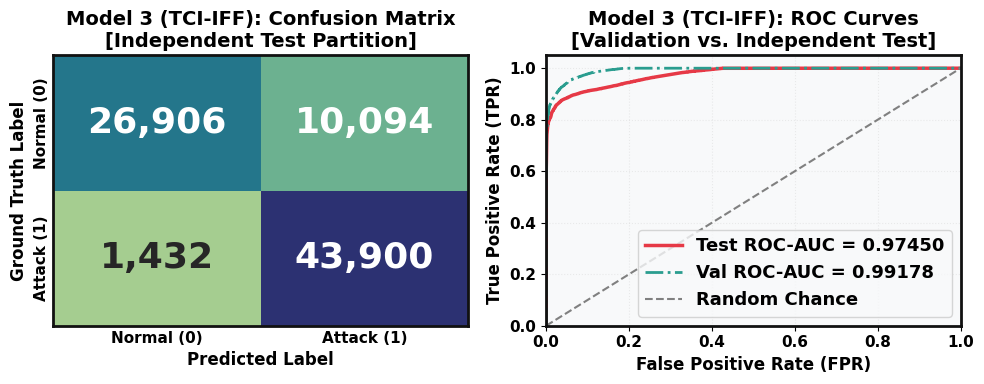

In [13]:
# Develops a two-pane chart for the analysis of the third architecture through additional diagnostic visuals.
fig, axes = plt.subplots(1, 2, figsize=(10, 4), facecolor='white')
# Develops the classification error matrix based on the predictions made exclusively by the third architecture.
cm_tci = confusion_matrix(y_test_final, res_model3['y_test_pred'])
# Shows the classification error matrix with counts and clearly marked outcome classes.
sns.heatmap(cm_tci, ax=axes[0], annot=True, fmt=',d', cmap='crest',
            xticklabels=['Normal (0)', 'Attack (1)'], yticklabels=['Normal (0)', 'Attack (1)'],
            annot_kws={"size": 26, "weight": "bold"}, cbar=False,
            linewidths=0)
# Eliminates any possible artifacts at the edges of adjacent cells in the matrix.
axes[0].collections[0].set_edgecolor('face')
# Adds an informative caption to the classification error matrix of the third architecture.
axes[0].set_title('Model 3 (TCI-IFF): Confusion Matrix\n[Independent Test Partition]', fontsize=14, fontweight='bold')
# Denotes the horizontal axis as the predicted outcome classes.
axes[0].set_xlabel('Predicted Label', fontsize=12, fontweight='bold')
# Denotes the vertical axis as the observed outcome classes.
axes[0].set_ylabel('Ground Truth Label', fontsize=12, fontweight='bold')
# Uses the pre-established academic border style for the classification matrix.
apply_plot_border(axes[0])
# Enhances the typography for the axis captions in the matrix.
make_ticks_bold(axes[0])
# Eliminates the background reference lines in the classification matrix.
axes[0].grid(False)
# Eliminates the tick marks for a clearer matrix visualization.
axes[0].tick_params(length=0)
# Computes receiver operating characteristic coordinates for the validation data set.
fpr_tci_val, tpr_tci_val, _ = roc_curve(y_val_final, res_model3['y_val_prob'])
# Computes receiver operating characteristic coordinates for the independent evaluation data set.
fpr_tci_test, tpr_tci_test, _ = roc_curve(y_test_final, res_model3['y_test_prob'])
# Plots the independent evaluation receiver operating characteristic curve with its area value.
axes[1].plot(fpr_tci_test, tpr_tci_test, color='#E63946', lw=2.5, label=f'Test ROC-AUC = {res_model3["Test_AUC"]:.5f}')
# Plots the validation receiver operating characteristic curve along with its area.
axes[1].plot(fpr_tci_val, tpr_tci_val, color='#2A9D8F', lw=2.0, linestyle='-.', label=f'Val ROC-AUC = {res_model3["Val_AUC"]:.5f}')
# Plots the reference line indicating the random classification case.
axes[1].plot([0, 1], [0, 1], color='gray', lw=1.5, linestyle='--', label='Random Chance')
# Sets the viewing limits on the horizontal axis for the receiver operating characteristic analysis.
axes[1].set_xlim([0.0, 1.0])
# Sets the viewing limits on the vertical axis for the receiver operating characteristic analysis.
axes[1].set_ylim([0.0, 1.05])
# Names the horizontal axis with the help of the false-positive rate metric.
axes[1].set_xlabel('False Positive Rate (FPR)', fontsize=12, fontweight='bold')
# Names the vertical axis with the help of the true-positive rate metric.
axes[1].set_ylabel('True Positive Rate (TPR)', fontsize=12, fontweight='bold')
# Gives a name to the receiver operating characteristic curves of validation and independent evaluation.
axes[1].set_title('Model 3 (TCI-IFF): ROC Curves\n[Validation vs. Independent Test]', fontsize=14, fontweight='bold')
# Includes a legend that specifies the validation, independent evaluation, and reference receiver operating characteristics.
axes[1].legend(loc="lower right", frameon=True, prop={'weight': 'bold', 'size': 13})
# Inserts the subtle reference lines into the receiver operating characteristic panel.
axes[1].grid(True, linestyle=':', alpha=0.35)
# Uses the predefined academic border style for the receiver operating characteristic panel.
apply_plot_border(axes[1])
# Improves the typography of the receiver operating characteristic axis labels.
make_ticks_bold(axes[1])
# Changes the spacing between the figure elements to avoid overlapping.
plt.tight_layout()
# Saves the third figure for architecture evaluation in high resolution.
plt.savefig('plot_10_model_3_tci_iff_evaluation.png', **SAVE_OPTS)
# Shows the third architecture evaluation figure in the notebook.
plt.show()

# **MASTER COMPARATIVE BENCHMARK**

In [14]:
# Shows the separator at the beginning of the master benchmarking and statistical analysis phase.
print("=" * 95)
# Designates the tenth phase of the experiment design.
print("[STEP 10] MASTER BENCHMARK TABULATION & STATISTICAL SIGNIFICANCE TESTING")
# Shows the separator after the phase designation.
print("=" * 95)
# Converts all recorded results of model performance evaluation into one analysis table.
master_df = pd.DataFrame(all_evaluation_records)

# Extracts the classification metrics from the independent evaluation subset.
master_test_table = master_df[[
    "Model", "Test_Acc", "Test_Prec", "Test_Rec", "Test_F1", "Test_MCC", "Test_AUC"
]].copy()
# Creates the independent version of extracted performance metrics.
master_test_table.columns = ["Model Architecture", "Accuracy", "Precision", "Recall", "F1-Score", "MCC", "ROC-AUC"]
# Shows the separator before the presentation of the first master performance table.
print("\n" + "=" * 95)
# Names the first master performance table, which is classification performance on the independent evaluation subset.
print("MASTER TABLE 1: CLASSIFICATION PERFORMANCE ON INDEPENDENT TEST PARTITION (82,332 Flows)")
# Shows the separator after the first master table name.
print("=" * 95)
# Shows the independent evaluation performance table with numerically formatted data.
print(master_test_table.to_string(index=False, float_format=lambda x: f"{x:.5f}"))
# Extracts the classification metrics from the validation subset.
master_val_table = master_df[[
    "Model", "Val_Acc", "Val_Prec", "Val_Rec", "Val_F1", "Val_MCC", "Val_AUC"
]].copy()
# Creates the validation version of extracted performance metrics.
master_val_table.columns = ["Model Architecture", "Accuracy", "Precision", "Recall", "F1-Score", "MCC", "ROC-AUC"]
# Shows the separator before the presentation of the second master performance table.
print("\n" + "=" * 95)
# Shows the header for the classification performance on the stratified validation set.
print("MASTER TABLE 2: CLASSIFICATION PERFORMANCE ON STRATIFIED VALIDATION PARTITION (35,069 Flows)")
# Shows the separator under the second master table header.
print("=" * 95)
# Shows the validation performance table with numerical standardization.
print(master_val_table.to_string(index=False, float_format=lambda x: f"{x:.5f}"))
# Chooses the computational efficiency criteria for all architectures tested.
master_comp_table = master_df[[
    "Model", "Train_Time_s", "Throughput_fps", "Latency_us", "Jitter_us"
]].copy()
# Creates the computational profiling table including the chosen criteria.
master_comp_table.columns = ["Model Architecture", "Train Time (s)", "Throughput (flows/s)", "Latency (μs/flow)", "Jitter (μs)"]
# Chooses names for the computational profiling criteria.
# Shows the separator prior to showing the computational benchmarking table.
print("\n" + "=" * 95)
# Shows the header for computational and real-time performance for all tested architectures.
print("MASTER TABLE 3: COMPUTATIONAL & REAL-TIME OPERATIONAL BENCHMARK (All 7 Models)")
# Shows the separator under the computational benchmarking header.
print("=" * 95)
# Shows the computational profiling table without any row indexing.
print(master_comp_table.to_string(index=False))
# Shows the final separator for the master benchmarking tables.
print("=" * 95)

[STEP 10] MASTER BENCHMARK TABULATION & STATISTICAL SIGNIFICANCE TESTING

MASTER TABLE 1: CLASSIFICATION PERFORMANCE ON INDEPENDENT TEST PARTITION (82,332 Flows)
           Model Architecture  Accuracy  Precision  Recall  F1-Score     MCC  ROC-AUC
     Random Forest (Baseline)   0.81462    0.74927 0.99691   0.85553 0.66103  0.96665
           XGBoost (Baseline)   0.85215    0.80026 0.97476   0.87893 0.71622  0.97355
          LightGBM (Baseline)   0.85901    0.81093 0.97011   0.88341 0.72702  0.97458
          CatBoost (Baseline)   0.85365    0.80317 0.97254   0.87978 0.71813  0.97284
     Model 1: HESN (Stacking)   0.86366    0.82055 0.96298   0.88608 0.73338  0.97381
Model 2: DACBN (Hybrid Stack)   0.86808    0.82765 0.96040   0.88910 0.74087  0.97432
  Model 3: TCI-IFF (Flagship)   0.86001    0.81305 0.96841   0.88396 0.72829  0.97450

MASTER TABLE 2: CLASSIFICATION PERFORMANCE ON STRATIFIED VALIDATION PARTITION (35,069 Flows)
           Model Architecture  Accuracy  Precision  Reca

# **VALIDATION EVALUATION — 3 PROPOSED MODELS**

[PLOTS] VALIDATION EVALUATION — 3 PROPOSED MODELS


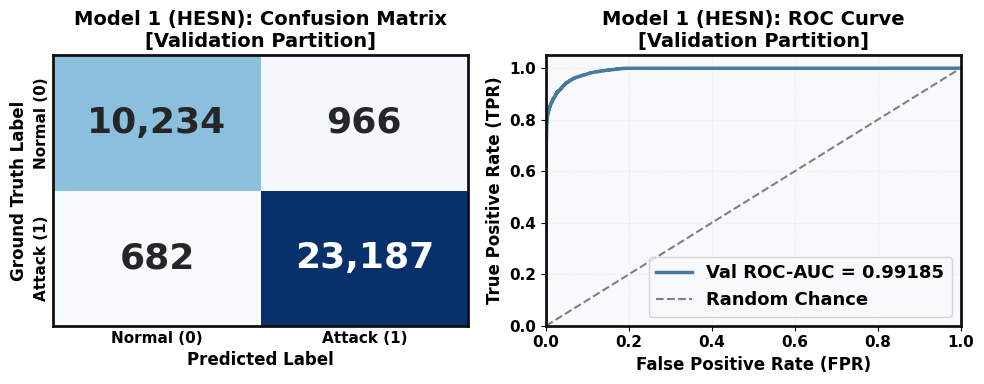

[✓] Saved: plot_val_model_1_hesn_evaluation.png


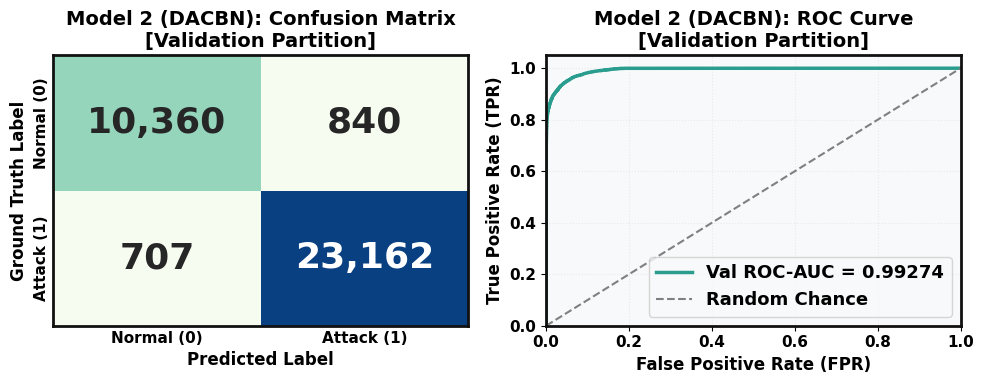

[✓] Saved: plot_val_model_2_dacbn_evaluation.png


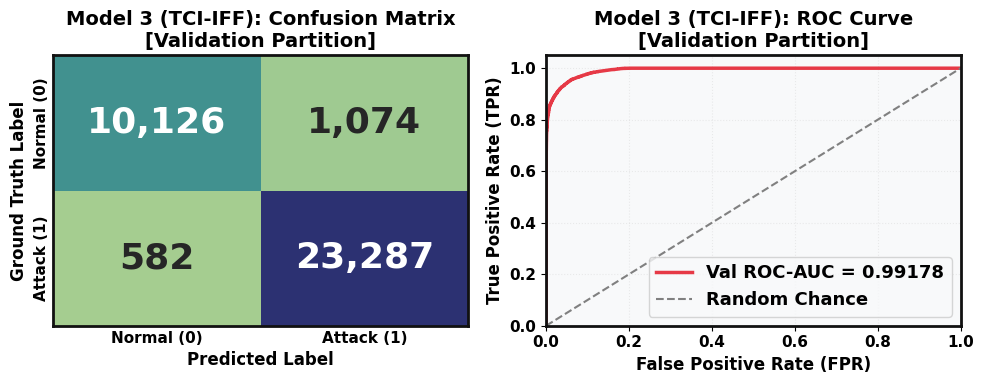

[✓] Saved: plot_val_model_3_tci_iff_evaluation.png


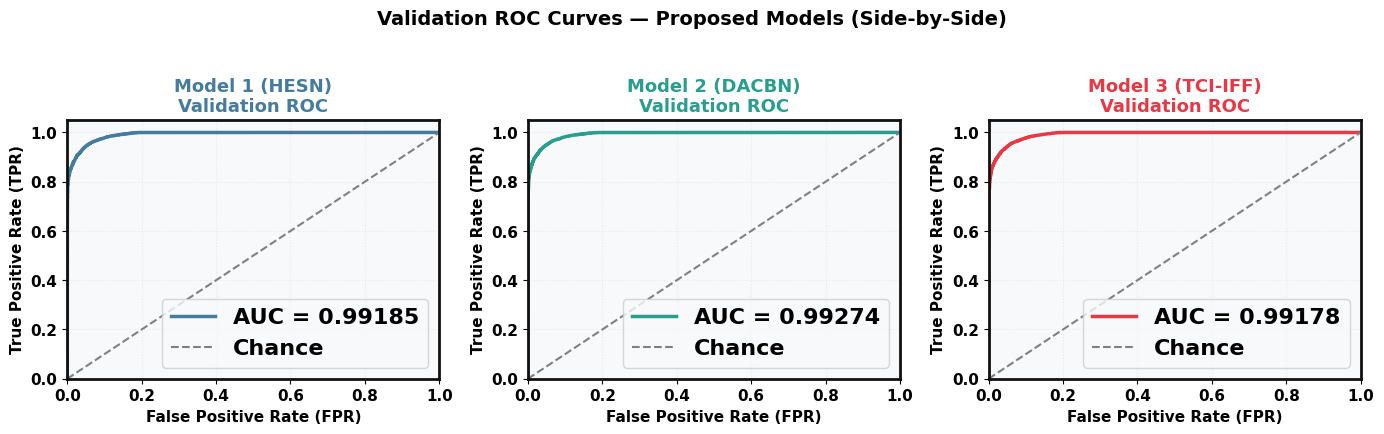

[✓] Saved: plot_val_roc_side_by_side_3models.png


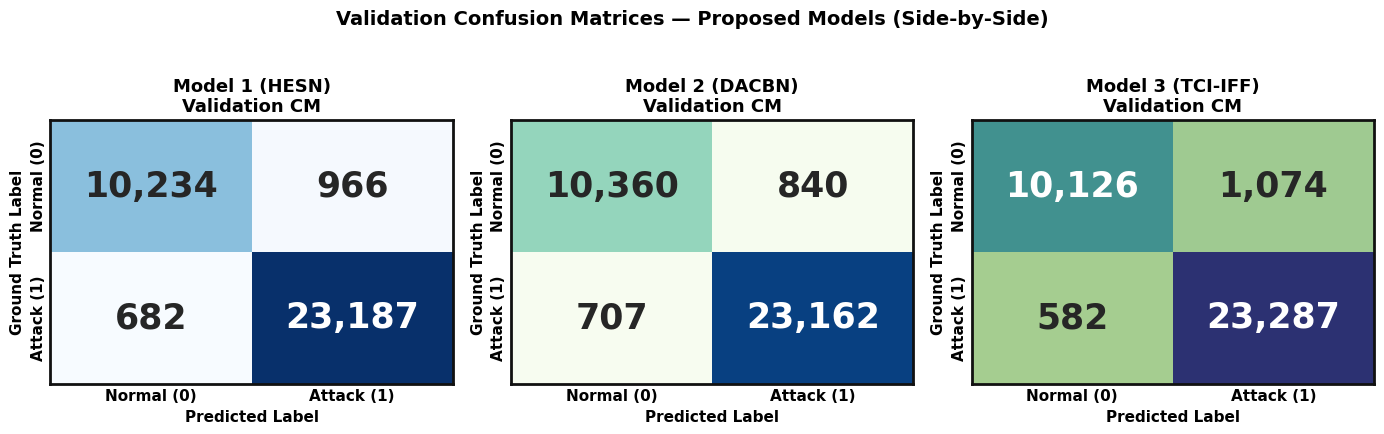

[✓] Saved: plot_val_cm_side_by_side_3models.png

[✓] Validation plots generated in the same formatting style as test graphs.


In [15]:
print("=" * 85)
print("[PLOTS] VALIDATION EVALUATION — 3 PROPOSED MODELS")
print("=" * 85)

from sklearn.metrics import confusion_matrix, roc_curve

# --------------------------------------------------------------------------
# Model specs (validation predictions already in res_*)
# --------------------------------------------------------------------------
proposed_val = [
    {
        "key": "hesn",
        "title": "Model 1 (HESN)",
        "file": "plot_val_model_1_hesn_evaluation.png",
        "cm_cmap": "Blues",
        "roc_color": "#457B9D",
        "y_pred": res_hesn["y_val_pred"],
        "y_prob": res_hesn["y_val_prob"],
        "auc": res_hesn["Val_AUC"],
    },
    {
        "key": "dacbn",
        "title": "Model 2 (DACBN)",
        "file": "plot_val_model_2_dacbn_evaluation.png",
        "cm_cmap": "GnBu",
        "roc_color": "#2A9D8F",
        "y_pred": res_model2["y_val_pred"],
        "y_prob": res_model2["y_val_prob"],
        "auc": res_model2["Val_AUC"],
    },
    {
        "key": "tci",
        "title": "Model 3 (TCI-IFF)",
        "file": "plot_val_model_3_tci_iff_evaluation.png",
        "cm_cmap": "crest",
        "roc_color": "#E63946",
        "y_pred": res_model3["y_val_pred"],
        "y_prob": res_model3["y_val_prob"],
        "auc": res_model3["Val_AUC"],
    },
]

y_true_val = y_val_final

# ==========================================================================
# Per-model: Confusion Matrix | ROC  (same format as your test plot)
# ==========================================================================
# Loop through the proposed models and generate a plot of validation performance.
for m in proposed_val:
    # Construct a figure that contains two plots placed side-by-side with a white background.
    fig, axes = plt.subplots(1, 2, figsize=(10, 4), facecolor="white")

    # ----- LEFT: Confusion Matrix -----
    # Construct the confusion matrix using the actual labels and predicted labels for validation.
    cm = confusion_matrix(y_true_val, m["y_pred"])
    # Draw the confusion matrix as a heatmap using the specified colors and counts.
    sns.heatmap(
        cm,
        ax=axes[0],
        annot=True,
        fmt=",d",
        cmap=m["cm_cmap"],
        # Set the x and y axes labels to denote the normal and attack classes.
        xticklabels=["Normal (0)", "Attack (1)"],
        yticklabels=["Normal (0)", "Attack (1)"],
        # Format the cell labels with big and bold font and hide the color bar.
        annot_kws={"size": 26, "weight": "bold"},
        cbar=False,
        # Hide the heatmap cells boundaries.
        linewidths=0,
    )
    # Style the edges of the confusion matrix with the specified style.
    axes[0].collections[0].set_edgecolor("face")
    # Set the title of the confusion matrix using the name of the model and validation partition.
    axes[0].set_title(
        f"{m['title']}: Confusion Matrix\n[Validation Partition]",
        fontsize=14,
        fontweight="bold",
    )
    # Set the label of the horizontal axis as predicted class.
    axes[0].set_xlabel("Predicted Label", fontsize=12, fontweight="bold")
    # Set the label of the vertical axis as ground-truth class.
    axes[0].set_ylabel("Ground Truth Label", fontsize=12, fontweight="bold")
    # Use the custom border and tick style for the plot.
    apply_plot_border(axes[0])
    make_ticks_bold(axes[0])
    # Hide the grid and ticks.
    axes[0].grid(False)
    axes[0].tick_params(length=0)

    # ----- RIGHT: ROC Curve (Validation) -----
    # Construct the receiver operating characteristic using the actual labels and predicted probabilities for validation.
    fpr, tpr, _ = roc_curve(y_true_val, m["y_prob"])
    # Plot the false positive rate vs the true positive rate using the curve color of the model.
    axes[1].plot(
        fpr,
        tpr,
        color=m["roc_color"],
        lw=2.5,
        # Show the validation ROC-AUC value in the legend of the curve.
        label=f'Val ROC-AUC = {m["auc"]:.5f}',
    )
    # Plot the reference diagonal line.
    axes[1].plot(
        [0, 1],
        [0, 1],
        color="gray",
        lw=1.5,
        linestyle="--",
        label="Random Chance",
    )
    # Set the limit on the x-axis and y-axis for the ROC plot.
    axes[1].set_xlim([0.0, 1.0])
    axes[1].set_ylim([0.0, 1.05])
    # Use the false positive rate label on the x-axis.
    axes[1].set_xlabel("False Positive Rate (FPR)", fontsize=12, fontweight="bold")
    # Use the true positive rate label on the y-axis.
    axes[1].set_ylabel("True Positive Rate (TPR)", fontsize=12, fontweight="bold")
    # Name the ROC plot using the model name and validation set.
    axes[1].set_title(
        f"{m['title']}: ROC Curve\n[Validation Partition]",
        fontsize=14,
        fontweight="bold",
    )
    # Position the legend in the lower right corner and format it in bold font.
    axes[1].legend(
        loc="lower right",
        frameon=True,
        prop={"weight": "bold", "size": 13},
    )
    # Add a faint dotted grid to increase clarity.
    axes[1].grid(True, linestyle=":", alpha=0.35)
    # Apply the custom plot border and bold axis tick mark labels.
    apply_plot_border(axes[1])
    make_ticks_bold(axes[1])

    # Reposition the subplots so that they do not overlap.
    plt.tight_layout()
    # Export the plot into the specified file using the export options.
    plt.savefig(m["file"], **SAVE_OPTS)
    # Show the plot.
    plt.show()
    # Verify the exported file path in the output.
    print(f"[✓] Saved: {m['file']}")
# ==========================================================================
# Combined figure: all 3 models side-by-side ROC (Validation only)
# ==========================================================================
# Create a plot with three subplots placed next to each other.
# Adjust the dimensions of the plot and its background color.
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), facecolor="white")

# For each subplot and model create an ROC plot of model performance on validation dataset.
for ax, m in zip(axes, proposed_val):
    # Compute the false positive and true positive rates with the help of real labels and predictions.
    fpr, tpr, _ = roc_curve(y_true_val, m["y_prob"])
    # Draw ROC curve using the specified model color and line width.
    ax.plot(
        fpr,
        tpr,
        color=m["roc_color"],
        lw=2.5,
        # Include ROC-AUC of the model into the legend.
        label=f'AUC = {m["auc"]:.5f}',
    )
    # Add the line representing the performance of the random classifier.
    ax.plot([0, 1], [0, 1], color="gray", lw=1.5, linestyle="--", label="Chance")
    # Set horizontal and vertical limits for the ROC curves.
    ax.set_xlim([0.0, 1.0])
    ax.set_ylim([0.0, 1.05])
    # Set the label of the horizontal axis as FPR.
    ax.set_xlabel("False Positive Rate (FPR)", fontsize=11, fontweight="bold")
    # Set the label of the vertical axis as TPR.
    ax.set_ylabel("True Positive Rate (TPR)", fontsize=11, fontweight="bold")
    # Specify the title of the subplot with the help of the model name and validation ROC description.
    # Set the specific color and bold style of the title of the subplot.
    ax.set_title(
        f"{m['title']}\nValidation ROC",
        fontsize=13,
        fontweight="bold",
        color=m["roc_color"],
    )
    # Place the legend on the right bottom with the use of bold fonts.
    ax.legend(loc="lower right", frameon=True, prop={"weight": "bold", "size": 16})
    # Draw a grid for better readability.
    ax.grid(True, linestyle=":", alpha=0.35)
    # Set the customized plot border and bold axis ticks.
    apply_plot_border(ax)
    make_ticks_bold(ax)

# Set the title for all subplots that describe the comparison of validation ROC plots.
# Adjust the font size, bold font and position of the title.
plt.suptitle(
    "Validation ROC Curves — Proposed Models (Side-by-Side)",
    fontsize=14,
    fontweight="bold",
    y=1.03,
)

# Adjust the subplot layout.
plt.tight_layout()

# Store the plot of ROC comparisons in a single figure using the indicated export settings.
plt.savefig("plot_val_roc_side_by_side_3models.png", **SAVE_OPTS)
# Show the created figure.
plt.show()
# Verify the saved figure filename from the output.
print("[✓] Saved: plot_val_roc_side_by_side_3models.png")
# ==========================================================================
# Combined figure: all 3 confusion matrices side-by-side (Validation)
# ==========================================================================
# Create the three subplots horizontally aligned.
# Set the dimensions and background color of the figure.
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), facecolor="white")

# Loop over the three subplots and corresponding models to visualize their validation classification results.
for ax, m in zip(axes, proposed_val):
    # Compute the confusion matrix from the actual validation labels and the predicted class labels.
    cm = confusion_matrix(y_true_val, m["y_pred"])

    # Show the confusion matrix in a heatmap format with the count annotations and specific colormap of the current model.
    # Set the x-axis and y-axis labels for normal and attack classes.
    # Use the large bold annotation style without the color bar.
    # Do not draw the boundary between the heatmap cells.
    sns.heatmap(
        cm,
        ax=ax,
        annot=True,
        fmt=",d",
        cmap=m["cm_cmap"],
        xticklabels=["Normal (0)", "Attack (1)"],
        yticklabels=["Normal (0)", "Attack (1)"],
        annot_kws={"size": 25, "weight": "bold"},
        cbar=False,
        linewidths=0,
    )

    # Use the specified edge style for the heatmap.
    ax.collections[0].set_edgecolor("face")

    # Set the title of the subplot to be the name of the current model and the validation confusion matrix.
    ax.set_title(
        f"{m['title']}\nValidation CM",
        fontsize=13,
        fontweight="bold",
    )

    # Set the x-label and y-label to be the predicted class and the ground-truth class respectively.
    ax.set_xlabel("Predicted Label", fontsize=11, fontweight="bold")
    ax.set_ylabel("Ground Truth Label", fontsize=11, fontweight="bold")

    # Use the custom plot borders and bold axes ticks formatting.
    apply_plot_border(ax)
    make_ticks_bold(ax)

    # Hide the grid and do not show the ticks.
    ax.grid(False)
    ax.tick_params(length=0)

# Set the title of the whole figure as the title for validation confusion matrices comparison.
# Specify the title size and bold style.
plt.suptitle(
    "Validation Confusion Matrices — Proposed Models (Side-by-Side)",
    fontsize=14,
    fontweight="bold",
    y=1.03,
)

# Adjust the subplots positions to prevent overlap.
plt.tight_layout()

# Save the generated confusion matrices in the form of a figure.
plt.savefig("plot_val_cm_side_by_side_3models.png", **SAVE_OPTS)

# Show the created figure below.
plt.show()
# Check the name of the saved figure in the output.
print("[✓] Saved: plot_val_cm_side_by_side_3models.png")

print("\n" + "=" * 85)
print("[✓] Validation plots generated in the same formatting style as test graphs.")
print("=" * 85)

# **STATISTICAL SIGNIFICANCE TESTING**

In [16]:
# Install display utilities for display of the statistical results in an HTML table in a Jupyter Notebook.
from IPython.display import display, HTML
# ------------------------------------------------------------------------------
# Enhanced McNemar's Test Function
# ------------------------------------------------------------------------------

# Define a function to carry out the statistical test of McNemar for two classifiers.
def compute_mcnemar_test(y_true, y_pred_A, y_pred_B, name_A="Model A", name_B="Model B"):
    # Convert the ground truth labels and both of the predictions into 1D numpy arrays.
    y_true_arr = np.asarray(y_true).ravel()
    y_pred_A_arr = np.asarray(y_pred_A).ravel()
    y_pred_B_arr = np.asarray(y_pred_B).ravel()

    # Determine the observations that were correctly classified by model A and model B.
    correct_A = (y_pred_A_arr == y_true_arr)
    correct_B = (y_pred_B_arr == y_true_arr)

    # Count the number of correct predictions by Model A and the number of wrong predictions by Model B.
    b = int(np.sum((correct_A) & (~correct_B)))
    # Count how many times Model A fails to predict the correct answer, and how many times Model B predicts the correct answer.
    c = int(np.sum((~correct_A) & (correct_B)))

    # Perform a continuity corrected chi-square test and associated p-value.
    if (b + c) == 0:
        # When both models have the same correctness outcomes, set both a zero chi-square statistic and a p value of one.
        chi2_stat = 0.0
        p_val = 1.0
    else:
        # Compute the chi-square statistic that corrects for continuity from the counts of the discordant predictions.
        chi2_stat = ((abs(b - c) - 1.0) ** 2) / (b + c)
        # Find the p value associated with the chi-square with one degree of freedom.
        p_val = chi2.sf(chi2_stat, df=1)

    # Calculate difference in number of correct predictions and odds ratio between discordant outcomes.
    net_gain = b - c
    odds_ratio = (b / c) if c > 0 else (np.inf if b > 0 else 1.0)

    # Identify the model with more correct predictions in the cases of discord.
    if net_gain > 0:
        # Identify model A as the preferred model if its discordant correct predictions exceed those of model B.
        favored_model = f"{name_A} (+{net_gain:,})"
    elif net_gain < 0:
        # Identify Model B as preferred when it has more discordant correct predictions than Model A.
        favored_model = f"{name_B} (+{abs(net_gain):,})"
    else:
        # If the number of correct predictions with both models is equal, report a tie.
        favored_model = "Tie"

    # Classify statistical significance based on the computed p-value.
    is_significant = "p < 0.001" if p_val < 0.001 else ("p < 0.05" if p_val < 0.05 else "NS")

    # Return a dictionary with the model comparison, discordant counts, effect direction, and statistical results.
    return {
        # Record the names of the two models being compared.
        "Model A vs Model B": f"{name_A} vs. {name_B}",
        # Record the number of times that Model A was right and Model B was wrong.
        "n10 (A+ B-)": b,
        # Include the number of times that Model A is wrong and Model B is right.
        "n01 (A- B+)": c,
        # Report the net gain in correct predictions.
        "Net Gain": f"{net_gain:+d}",
        # Report the discordant-pair odds ratio.
        "OR": f"{odds_ratio:.2f}" if not np.isinf(odds_ratio) else "Inf",
        # Add the chi-square statistic.
        "Chi2": round(chi2_stat, 2),
        # Add the p-value.
        "p-val": f"{p_val:.2e}" if p_val < 0.001 else f"{p_val:.4f}",
        # Record the statistical significance category.
        "Sig?": is_significant,
        # Record the preferred model based on the discordant prediction counts.
        "Favored Model (Winner)": favored_model
    }

# ------------------------------------------------------------------------------
# Execution Engine
# ------------------------------------------------------------------------------

# Set up the model pairs to be compared by using McNemar's test on the independent test predictions.
# Make comparisons between proposed models and selected baseline classifiers.
mcnemar_pairs = [
    ("Model 1: HESN", "LightGBM (Baseline)"),
    ("Model 1: HESN", "XGBoost (Baseline)"),
    ("Model 2: DACBN", "LightGBM (Baseline)"),
    ("Model 2: DACBN", "Model 1: HESN"),
    ("Model 3: TCI-IFF", "LightGBM (Baseline)"),
    ("Model 3: TCI-IFF", "Model 1: HESN"),
    ("Model 3: TCI-IFF", "Model 2: DACBN")
]

# Create a collection that will hold the statistics comparison results.
mcnemar_results = []
# Build the dictionary of the names of the evaluated models and their independent test predictions.
pred_lookup = {rec["Model"]: rec["y_test_pred"] for rec in all_evaluation_records}
# Iterate through each pair of models indicated.
for name_a, name_b in mcnemar_pairs:
    # Match the model names given with the keys in the prediction dictionary.
    full_a = next((k for k in pred_lookup if name_a in k), name_a)
    full_b = next((k for k in pred_lookup if name_b in k), name_b)

    # Before making comparisons, check to see if predictions can be made for both models.
    if full_a in pred_lookup and full_b in pred_lookup:
        # Perform McNemar test with the labels from the independent test and the predictions for the two models.
        res = compute_mcnemar_test(
            y_test_final,
            pred_lookup[full_a],
            pred_lookup[full_b],
            name_A=name_a,
            name_B=name_b
        )
        # Add each of the valid comparison results to a results collection.
        mcnemar_results.append(res)

# Convert the statistics that you gathered to a Pandas DataFrame.
mcnemar_df = pd.DataFrame(mcnemar_results)
# Change the configuration of Pandas to display all columns without truncating the table width or column contents.
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
pd.set_option('display.max_colwidth', None)
# Display the heading of the McNemar chi-square test and direction of effect analysis.
print("\n" + "=" * 115)
print(" McNEMAR'S CHI-SQUARE TEST & EFFECT DIRECTION ANALYSIS ")
print("=" * 115)
# Print the statistical comparison result in a formatted tabular format.
print(mcnemar_df.to_string(index=False))
# Show the separating line at the end of the results table.
print("=" * 115)

# Display McNemar test summary in an HTML table to improve readability in the Jupyter Notebook.
try:
    # Show the HTML heading and formatted comparison table.
    display(HTML("<h3>McNemar Test Summary</h3>" + mcnemar_df.to_html(index=False)))
# Catch exceptions relating to the display without stopping the rest of the notebook.
except:
    pass


 McNEMAR'S CHI-SQUARE TEST & EFFECT DIRECTION ANALYSIS 
                      Model A vs Model B  n10 (A+ B-)  n01 (A- B+) Net Gain   OR   Chi2    p-val      Sig? Favored Model (Winner)
   Model 1: HESN vs. LightGBM (Baseline)         1093          710     +383 1.54  80.93 2.33e-19 p < 0.001   Model 1: HESN (+383)
    Model 1: HESN vs. XGBoost (Baseline)         2030         1082     +948 1.88 288.18 1.24e-64 p < 0.001   Model 1: HESN (+948)
  Model 2: DACBN vs. LightGBM (Baseline)         1599          852     +747 1.88 227.06 2.61e-51 p < 0.001  Model 2: DACBN (+747)
        Model 2: DACBN vs. Model 1: HESN          973          609     +364 1.60  83.29 7.08e-20 p < 0.001  Model 2: DACBN (+364)
Model 3: TCI-IFF vs. LightGBM (Baseline)          773          691      +82 1.12   4.48   0.0343  p < 0.05 Model 3: TCI-IFF (+82)
      Model 3: TCI-IFF vs. Model 1: HESN          574          875     -301 0.66  62.11 3.25e-15 p < 0.001   Model 1: HESN (+301)
     Model 3: TCI-IFF vs. Model 2

Model A vs Model B,n10 (A+ B-),n01 (A- B+),Net Gain,OR,Chi2,p-val,Sig?,Favored Model (Winner)
Model 1: HESN vs. LightGBM (Baseline),1093,710,+383,1.54,80.93,2.33e-19,p < 0.001,Model 1: HESN (+383)
Model 1: HESN vs. XGBoost (Baseline),2030,1082,+948,1.88,288.18,1.24e-64,p < 0.001,Model 1: HESN (+948)
Model 2: DACBN vs. LightGBM (Baseline),1599,852,+747,1.88,227.06,2.61e-51,p < 0.001,Model 2: DACBN (+747)
Model 2: DACBN vs. Model 1: HESN,973,609,+364,1.60,83.29,7.08e-20,p < 0.001,Model 2: DACBN (+364)
Model 3: TCI-IFF vs. LightGBM (Baseline),773,691,+82,1.12,4.48,0.0343,p < 0.05,Model 3: TCI-IFF (+82)
Model 3: TCI-IFF vs. Model 1: HESN,574,875,-301,0.66,62.11,3.25e-15,p < 0.001,Model 1: HESN (+301)
Model 3: TCI-IFF vs. Model 2: DACBN,689,1354,-665,0.51,215.81,7.43e-49,p < 0.001,Model 2: DACBN (+665)


# **MODEL COMPUTATIONAL EFFICIENCY DASHBOARD (5-PANEL)**

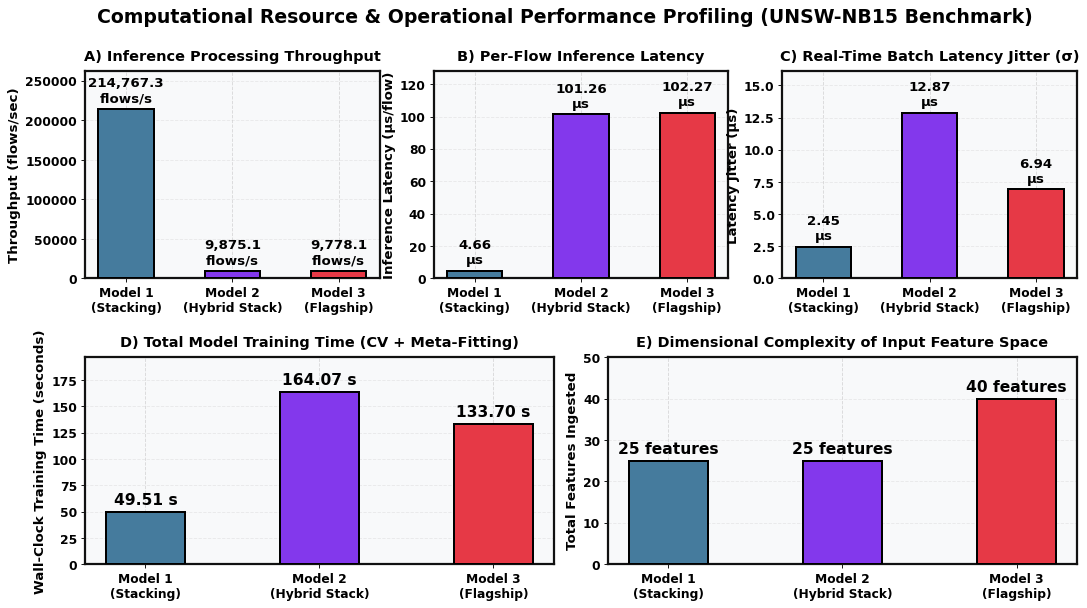


[✓] Step 10 Master Benchmark, Statistical Significance Tests & Visualizations Completed.


In [17]:
# ------------------------------------------------------------------------------
# 1. Filter Records for the 3 Proposed Architectures
# ------------------------------------------------------------------------------
# Defines the set of proposed architectures that need to be incorporated into the computational performance dashboard.
proposed_keys = [
    "Model 1: HESN (Stacking)",
    "Model 2: DACBN (Hybrid Stack)",
    "Model 3: TCI-IFF (Flagship)"
]
# Defines the collection that will store dashboard data.
dashboard_data = []
# Loops through each proposed architecture to extract dashboard data.
for key in proposed_keys:
    # Retrieves the evaluation data entry of the particular architecture from the entire set of model evaluations.
    rec = next((r for r in all_evaluation_records if r["Model"] == key), None)
    # Verifies whether a matching entry exists.
    if rec:
        # Counts the number of features used in the current architecture.
        feat_cnt = X_train_tci.shape[1] if "TCI" in key else X_train_final.shape[1]
        # Stores the name of the model and its computational performance data.
        dashboard_data.append({
            # Stores the name of the model (used during evaluation).
            'Model_Name': key,
            # Creates a model label for dashboard visualization.
            'Short_Label': key.split(':')[0].strip() + "\n(" + key.split('(')[1].replace(')', '') + ")",
            # Stores the prediction throughput measurements.
            'Throughput_fps': rec['Throughput_fps'],
            # Stores the prediction latency measurements.
            'Latency_us': rec['Latency_us'],
            # Stores the prediction jitter measurements.
            'Jitter_us': rec['Jitter_us'],
            # Stores the model training time measurements.
            'Training_Time_s': rec['Train_Time_s'],
            # Stores the number of features used in the entire model.
            'Features_Count': feat_cnt
        })
# Creates a DataFrame out of the stored dashboard data.
comp_dash_df = pd.DataFrame(dashboard_data)

# ------------------------------------------------------------------------------
# 2. Visualization Configuration & Palette
# ------------------------------------------------------------------------------
# Extracts the labels of the short models for dashboard visualization.
short_labels = comp_dash_df['Short_Label'].tolist()
# Defines the colors used for displaying the three proposed architectures.
dash_colors = ['#457B9D', '#8338EC', '#E63946'] # HESN (Blue), DACBN (Purple), TCI-IFF (Red)
# Generates the main dashboard figure with the specified dimensions, background, and resolution.
fig = plt.figure(figsize=(16, 8), facecolor='white', dpi=80)
# Defines the multi-panel grid layout for organizing the dashboard visualizations.
gs = gridspec.GridSpec(2, 6, figure=fig, hspace=0.38, wspace=0.45)
# Creates the subplot for prediction throughput analysis.
ax_throughput = fig.add_subplot(gs[0, 0:2])
# Creates the subplot for prediction latency analysis.
ax_latency = fig.add_subplot(gs[0, 2:4])
# Creates the subplot for prediction jitter analysis.
ax_jitter = fig.add_subplot(gs[0, 4:6])
# Creates the subplot for model training time analysis.
ax_train_time = fig.add_subplot(gs[1, 0:3])
# Creates the subplot for feature count analysis.
ax_features = fig.add_subplot(gs[1, 3:6])
# Defines the overall title of the computational and operational performance dashboard.
fig.suptitle('Computational Resource & Operational Performance Profiling (UNSW-NB15 Benchmark)',
             fontsize=17, fontweight='bold', y=0.98)
# ------------------------------------------------------------------------------
# Panel 1: Throughput Comparison (flows/sec)
# ------------------------------------------------------------------------------
# Computes the maximum throughput to set the vertical plotting range.
max_thr = comp_dash_df['Throughput_fps'].max()
# Plots vertical bars showing the inference throughput of each architecture.
bars1 = ax_throughput.bar(short_labels, comp_dash_df['Throughput_fps'],
                          color=dash_colors, edgecolor='black', linewidth=1.8, width=0.52, zorder=3)
# Specifies the name of the axis on which the throughput is plotted.
ax_throughput.set_ylabel('Throughput (flows/sec)', fontweight='bold', fontsize=12)
# Names the plot to indicate the throughput comparison of the inference processing.
ax_throughput.set_title('A) Inference Processing Throughput', fontweight='bold', fontsize=13, pad=10)
# Increases the range of the vertical axis for annotating the numbers.
ax_throughput.set_ylim(0, max_thr * 1.22)
# Loops over the throughput bars and their corresponding values.
for bar, v in zip(bars1, comp_dash_df['Throughput_fps']):
    # Draws the throughput value and its unit on top of each throughput bar.
    ax_throughput.text(bar.get_x() + bar.get_width()/2, v + max_thr*0.025, f'{v:,.1f}\nflows/s',
                       ha='center', va='bottom', fontweight='bold', fontsize=12)
# ------------------------------------------------------------------------------
# Panel 2: Latency Comparison (μs/flow)
# ------------------------------------------------------------------------------
# Computes the highest inference latency value in order to determine the plot’s vertical range.
max_lat = comp_dash_df['Latency_us'].max()
# Draws vertical bars that indicate the per-flow inference latency of the respective architectures.
bars2 = ax_latency.bar(short_labels, comp_dash_df['Latency_us'],
                       color=dash_colors, edgecolor='black', linewidth=1.8, width=0.52, zorder=3)
# Designates the label that describes the inference latency axis.
ax_latency.set_ylabel('Inference Latency (μs/flow)', fontweight='bold', fontsize=12)
# Designates the title for the per-flow inference latency comparison.
ax_latency.set_title('B) Per-Flow Inference Latency', fontweight='bold', fontsize=13, pad=10)
# Expands the vertical plot range so that there will be enough room for numerical labels.
ax_latency.set_ylim(0, max_lat * 1.25)
# Loops over the bars for latencies and their respective measured values.
for bar, v in zip(bars2, comp_dash_df['Latency_us']):
    # Presents the latency value and its unit above the corresponding bar.
    ax_latency.text(bar.get_x() + bar.get_width()/2, v + max_lat*0.025, f'{v:.2f}\nμs',
                    ha='center', va='bottom', fontweight='bold', fontsize=12)
# ------------------------------------------------------------------------------
# Panel 3: Jitter Comparison (μs)
# ------------------------------------------------------------------------------
# Computes the largest value for the latency jitter to define the proper vertical scale.
max_jit = comp_dash_df['Jitter_us'].max()
# Plots vertical bars that denote the latency jitter of each architecture in real-time batches.
bars3 = ax_jitter.bar(short_labels, comp_dash_df['Jitter_us'],
                      color=dash_colors, edgecolor='black', linewidth=1.8, width=0.52, zorder=3)
# Provides the legend for the latency jitter axis.
ax_jitter.set_ylabel('Latency Jitter (μs)', fontweight='bold', fontsize=12)
# Provides the legend for the title of the latency jitter comparison.
ax_jitter.set_title('C) Real-Time Batch Latency Jitter (σ)', fontweight='bold', fontsize=13, pad=10)
# Increases the vertical scale but keeps the minimum scale to plot small jitter values.
ax_jitter.set_ylim(0, max(max_jit * 1.25, 2.0))
# Loops through all jitter bars and their values.
for bar, v in zip(bars3, comp_dash_df['Jitter_us']):
    # Shows the jitter value and its unit above the jitter bar.
    ax_jitter.text(bar.get_x() + bar.get_width()/2, v + max_jit*0.025, f'{v:.2f}\nμs',
                   ha='center', va='bottom', fontweight='bold', fontsize=12)
# ------------------------------------------------------------------------------
# Panel 4: Training Duration Comparison (seconds)
# ------------------------------------------------------------------------------
# Calculates the maximum model training time in order to determine the correct range of the vertical axis.
max_train = comp_dash_df['Training_Time_s'].max()
# Plots vertical bars to denote the total training time of each suggested architecture.
bars4 = ax_train_time.bar(short_labels, comp_dash_df['Training_Time_s'],
                          color=dash_colors, edgecolor='black', linewidth=1.8, width=0.45, zorder=3)
# Determines the description for the vertical axis denoting wall-clock training time.
ax_train_time.set_ylabel('Wall-Clock Training Time (seconds)', fontweight='bold', fontsize=12)
# Establishes the title to describe the total model training time comparison.
ax_train_time.set_title('D) Total Model Training Time (CV + Meta-Fitting)', fontweight='bold', fontsize=13, pad=10)
# Extends the range of the vertical axis to have enough room for annotations.
ax_train_time.set_ylim(0, max_train * 1.20)
# Loops through the bars and values of each total training time.
for bar, v in zip(bars4, comp_dash_df['Training_Time_s']):
    # Shows the total training time and its units on top of each bar.
    ax_train_time.text(bar.get_x() + bar.get_width()/2, v + max_train*0.025, f'{v:.2f} s',
                       ha='center', va='bottom', fontweight='bold', fontsize=14)
# ------------------------------------------------------------------------------
# Panel 5: Feature Space Dimension Count
# ------------------------------------------------------------------------------
# Determines the largest value of the number of input features to set up the adequate vertical plot range.
max_feat = comp_dash_df['Features_Count'].max()
# Plots the vertical bars that represent the number of input features in each architecture.
bars5 = ax_features.bar(short_labels, comp_dash_df['Features_Count'],
                        color=dash_colors, edgecolor='black', linewidth=1.8, width=0.45, zorder=3)
# Sets the name of the axis representing the total number of input features.
ax_features.set_ylabel('Total Features Ingested', fontweight='bold', fontsize=12)
# Sets the title of the plot representing the complexity of the input feature space.
ax_features.set_title('E) Dimensional Complexity of Input Feature Space', fontweight='bold', fontsize=13, pad=10)
# Increases the vertical plot range to be able to fit the numbers.
ax_features.set_ylim(0, max_feat * 1.25)
# Iterates through the feature-count bars and their values.
for bar, v in zip(bars5, comp_dash_df['Features_Count']):
    # Plots the number of input features and its unit on top of each bar.
    ax_features.text(bar.get_x() + bar.get_width()/2, v + max_feat*0.025, f'{v} features',
                     ha='center', va='bottom', fontweight='bold', fontsize=14)
# ------------------------------------------------------------------------------
# Polish All Subplots with Unified Academic Styling
# ------------------------------------------------------------------------------
# Aggregates all the axes from the dashboard for formatting consistency throughout the entire performance dashboard.
all_dash_axes = [ax_throughput, ax_latency, ax_jitter, ax_train_time, ax_features]
# Loops through the dashboard subplots and applies the specified visual formatting.
for ax in all_dash_axes:
    # Places the grid lines behind the main plotting items.
    ax.set_axisbelow(True)
    # Plots the horizontal dashed lines for the purpose of comparison.
    ax.grid(True, linestyle='--', alpha=0.35, axis='y')
    # Applies the specified academic border formatting to the individual subplots from the dashboard.
    apply_plot_border(ax)
    # Employs the bold font type for the tick labels on all dashboard axes.
    make_ticks_bold(ax)
# Automatically scales the distance between the dashboard items to avoid overlapping.
plt.tight_layout()
# Exports the completed computational performance dashboard with the specified high resolution.
plt.savefig('model_efficiency_dashboard.png', **SAVE_OPTS)
# Shows the dashboard within the notebook.
plt.show()
# Puts the separating line before the completion message.
print("\n" + "=" * 95)
# Checks whether the master benchmarking, statistical significance testing and visualization phases have been successfully completed.
print("[✓] Step 10 Master Benchmark, Statistical Significance Tests & Visualizations Completed.")
# Puts the separating line after the completion message.
print("=" * 95)

# **EXPLAINABLE AI (XAI) — SHAP, LIME & QUANTITATIVE FIDELITY**

[STEP 11] EXPLAINABLE ARTIFICIAL INTELLIGENCE (XAI) FRAMEWORK (REPRESENTATIVE MULTI-CASE)
[✓] Target Architecture : Model 2: DACBN (Hybrid Stack)

[✓] Representative Evaluation Instances Selected (Audit #19):
    - True Positive (Attack)         : Row Index #243
    - True Negative (Normal)         : Row Index #8
    - False Positive (Type I Error)  : Row Index #0
    - False Negative (Type II Error) : Row Index #277

>> Computing SHAP attributions via KernelExplainer on Model 2: DACBN (Hybrid Stack)...


  0%|          | 0/4 [00:00<?, ?it/s]

   [✓] SHAP KernelExplainer completed in 8.18s for 4 instances.

>> Computing LIME surrogates & quantitative audits...
   [i] Perturbation noise is applied in STANDARDIZED Z-score space (Audit #9).


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]


TABLE 4: MULTI-INSTANCE QUANTITATIVE XAI AUDIT (Matched Instances)
 Instance Type  LIME Fidelity (R²) SHAP-LIME Top-5 Agreement  SHAP Stability (Spearman ρ)
 True Positive              0.3290                     25.0%                       0.6912
 True Negative              0.3214                     25.0%                       0.5990
False Positive              0.3233                     42.9%                       0.8892
False Negative              0.3822                     11.1%                       0.3069
-----------------------------------------------------------------------------------------------
Average LIME Local Surrogate Fidelity (R²) : 0.3390
Average SHAP Stability (Spearman ρ)          : 0.6216 (under 2% Standardized Z-score noise)

[Detail] Top features per representative instance:
  • True Positive:
      SHAP: ct_state_ttl, proto_arp, ct_srv_src, ct_srv_dst, dur
      LIME: ct_state_ttl, proto_arp, service_dns, ct_dst_sport_ltm, dttl
  • True Negative:
      SHAP: pr

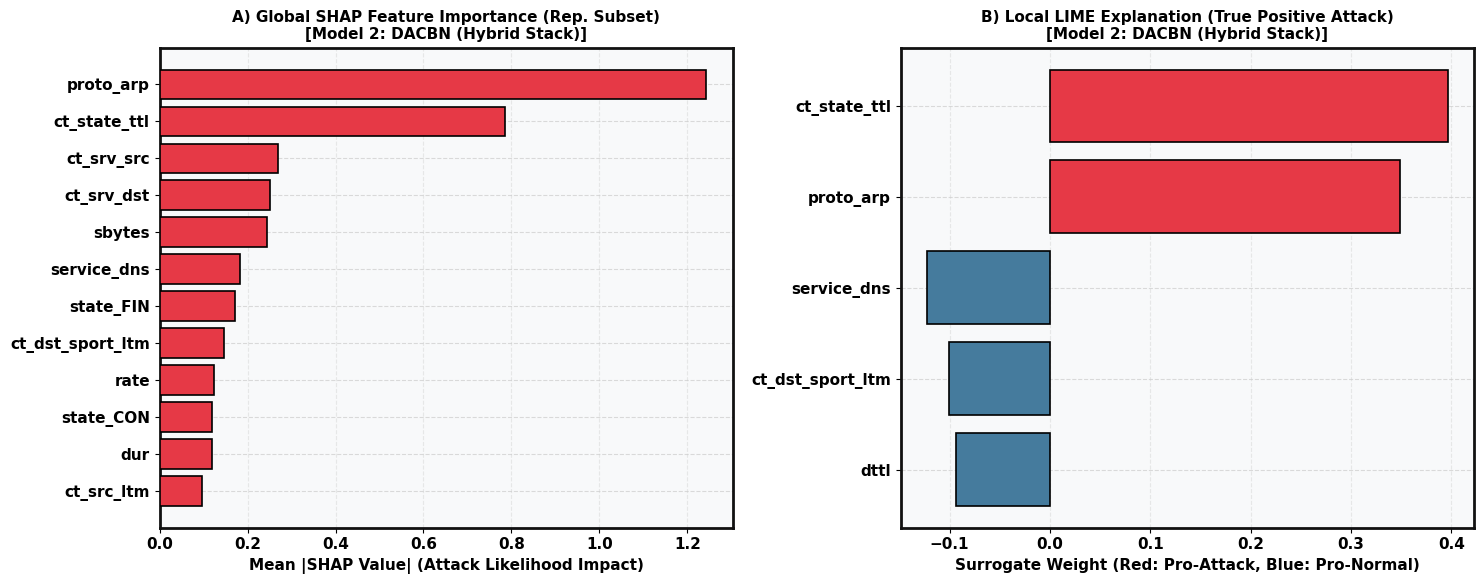


[✓] Saved: plot_14_xai_model2_dacbn_multi_instance.png
[✓] Saved: thesis_table_xai_multi_instance_audit.csv
[✓] Step 11 Complete — Multi-Instance XAI Framework.


In [18]:
print("=" * 95)
print("[STEP 11] EXPLAINABLE ARTIFICIAL INTELLIGENCE (XAI) FRAMEWORK (REPRESENTATIVE MULTI-CASE)")
print("=" * 95)
# ==============================================================================
# 1. Target Model & Feature Registry
# ==============================================================================
# Select the fitted DACBN stacking model for explainability analysis.
best_model = fitted_estimators_dict["Model 2: DACBN"]
# Define the model name for reporting and visualization.
best_model_name = "Model 2: DACBN (Hybrid Stack)"
# Extract feature names from the independent test dataset.
feature_list = [str(col) for col in X_test_final.columns]
# Display the selected model architecture.
print(f"[✓] Target Architecture : {best_model_name}")
# ==============================================================================
# 2. Representative Instance Selection (Audit #19: TP, TN, FP, FN)
# ==============================================================================
# Set the random seed to ensure reproducibility of subsequent sampling operations.
np.random.seed(RANDOM_SEED)
# Convert the independent test labels into a one-dimensional NumPy array.
y_test_arr = np.asarray(y_test_final).ravel()
# Generate predictions for the independent test dataset using the selected model.
preds_best = np.asarray(best_model.predict(X_test_final)).ravel()
# Identify the indices of correctly predicted attack instances (True Positives).
tp_idx = np.where((y_test_arr == 1) & (preds_best == 1))[0]
# Identify the indices of correctly predicted normal instances (True Negatives).
tn_idx = np.where((y_test_arr == 0) & (preds_best == 0))[0]
# Identify the indices of normal instances incorrectly classified as attacks (False Positives).
fp_idx = np.where((y_test_arr == 0) & (preds_best == 1))[0]
# Identify the indices of attack instances incorrectly classified as normal (False Negatives).
fn_idx = np.where((y_test_arr == 1) & (preds_best == 0))[0]
# Select one representative instance for each confusion matrix outcome.
# Use the first matching instance when available; otherwise, use a fallback index.
target_indices = {
    "True Positive (Attack)": int(tp_idx[0]) if len(tp_idx) > 0 else 0,
    "True Negative (Normal)": int(tn_idx[0]) if len(tn_idx) > 0 else 1,
    "False Positive (Type I Error)": int(fp_idx[0]) if len(fp_idx) > 0 else 2,
    "False Negative (Type II Error)": int(fn_idx[0]) if len(fn_idx) > 0 else 3,
}
# Display the selected representative instances and their corresponding row indices.
print("\n[✓] Representative Evaluation Instances Selected (Audit #19):")
for name, idx in target_indices.items():
    print(f"    - {name:30s} : Row Index #{idx}")
# Extract the representative observations from the independent test dataset.
X_rep_eval = X_test_final.iloc[list(target_indices.values())].copy()
# Determine the maximum KernelSHAP background sample size,
# capped at the number of available test observations.
bg_size = min(100, len(X_test_final))
# Randomly select background observations without replacement.
bg_sample_idx = np.random.choice(
    len(X_test_final), size=bg_size, replace=False
)
# Extract the background dataset used to calculate SHAP attributions.
X_bg = X_test_final.iloc[bg_sample_idx].copy()
# ==============================================================================
# 3. SHAP KernelExplainer on EXACT same representative instances (Audit #18)
# ==============================================================================
# Display the initialization message for SHAP attribution computation.
print(
    f"\n>> Computing SHAP attributions via KernelExplainer "
    f"on {best_model_name}..."
)
# Record the start time to measure SHAP computation duration.
t_shap_start = time.perf_counter()
# Initialize KernelSHAP using the selected model's probability predictions.
explainer_shap = shap.KernelExplainer(
    # Use the sampled background observations as the reference distribution.
    model=best_model.predict_proba,
    # Apply the logit link function to explain model probabilities.
    data=X_bg,
    link="logit"
)
# Compute SHAP values for the representative instances.
shap_values_raw = explainer_shap.shap_values(
    # Limit the number of model evaluations used for each explanation.
    X_rep_eval, nsamples=150
)

# Define a helper function to convert SHAP outputs into a
# two-dimensional attribution matrix: (n_samples, n_features).
def extract_2d_attributions(raw_shap, n_features):
    """Convert SHAP outputs into a consistent two-dimensional attribution matrix."""

    # If SHAP returns separate arrays for each class,
    # prefer the attack-class attributions (class index 1).
    if isinstance(raw_shap, list):
        arr = np.array(
            raw_shap[1] if len(raw_shap) > 1 else raw_shap[0]
        )
    else:
        # Convert the selected SHAP output into a NumPy array.
        arr = np.array(raw_shap)
    # Handle three-dimensional SHAP outputs by selecting attack-class
    # attributions when the final dimension represents two classes.
    if arr.ndim == 3:
        if arr.shape[-1] == 2:
            arr = arr[:, :, 1]
        else:
            # Remove unnecessary dimensions when the output has
            # a different class or feature layout.
            arr = arr.squeeze()
    # Convert one-dimensional attribution outputs into a single-sample matrix.
    elif arr.ndim == 1:
        arr = arr.reshape(1, -1)
    # Ensure that attribution values are represented as numeric values.
    arr = np.asarray(arr, dtype=float)
    # Reshape the output when necessary to obtain a two-dimensional
    # matrix with the expected number of features.
    if arr.ndim != 2:
        arr = arr.reshape(-1, n_features)
    # Return the standardized two-dimensional attribution matrix.
    return arr

# Convert the representative-instance SHAP values into a two-dimensional matrix.
shap_rep_matrix = extract_2d_attributions(
    shap_values_raw, len(feature_list)
)
# Calculate the total time required for SHAP computation.
t_shap_total = time.perf_counter() - t_shap_start
# Report execution duration and the number of explained instances.
print(
    f"   [✓] SHAP KernelExplainer completed in "
    f"{t_shap_total:.2f}s for {len(X_rep_eval)} instances."
)

# ==============================================================================
# 4. LIME + Quantitative Audit
# ==============================================================================
# Display the initialization message for LIME explanations and quantitative audits.
print("\n>> Computing LIME surrogates & quantitative audits...")
# Indicate that perturbation noise is added in standardized Z-score space.
print(
    "   [i] Perturbation noise is applied in STANDARDIZED "
    "Z-score space (Audit #9)."
)
# Initialize the LIME tabular explainer using the training dataset.
lime_explainer = lime.lime_tabular.LimeTabularExplainer(
    # Supply feature names and human-readable class labels.
    training_data=np.asarray(X_train_final.values, dtype=float),
    # Configure the explainer for classification and reproducibility.
    feature_names=feature_list,
    class_names=["Normal (0)", "Attack (1)"],
    mode="classification",
    random_state=RANDOM_SEED
)
# Initialize the scaler used for standardized-space perturbation.
scaler_xai = StandardScaler()
# Fit the scaler exclusively on the training data to prevent test-data leakage.
scaler_xai.fit(X_train_final)
# Initialize a collection to store quantitative explainability audit results.
xai_audit_results = []
# Initialize a variable to store the top LIME features for the publication figure.
top_lime_features_for_plot = None
# Identify the selected representative True Positive instance for the explanation plot.
tp_idx_val = list(target_indices.values())[0]
# Repeat the explainability audit for each representative instance and its label.
for i, (case_name, idx) in enumerate(target_indices.items()):

    # Extract the current observation from the independent test dataset.
    inst_data = X_test_final.iloc[idx]

    # Convert the observation into a two-dimensional numerical array.
    inst_row = np.asarray(inst_data.values, dtype=float).reshape(1, -1)

    # --------------------------------------------------------------------------
    # A) LIME Fidelity (Audit #20)
    # --------------------------------------------------------------------------
    # create a local LIME explanation for the current observation.
    # Use the fitted model's probability predictions and explain up to 10 features.
    # take 1,000 perturbed samples to approximate the model's local behaviour.
    exp_lime = lime_explainer.explain_instance(
        data_row=inst_row.ravel(),
        predict_fn=best_model.predict_proba,
        num_features=10,
        num_samples=1000
    )

    # Extract the local surrogate model's fidelity score.
    lime_r2 = float(exp_lime.score)

    # Retrieve the explanation weights organized by class.
    lime_map_dict = exp_lime.as_map()

    # Identify the class labels available in the explanation output.
    available_classes = list(lime_map_dict.keys())

    # Prefer the attack class when available; otherwise, use the first available class.
    target_class = (
        1 if 1 in available_classes else available_classes[0]
    )

    # Retrieve feature contribution weights for the selected class.
    lime_map = lime_map_dict[target_class]

    # Rank LIME features by the absolute magnitude of their contribution weights.
    # Retain the five features with the strongest absolute contributions.
    lime_top_sorted = sorted(
        lime_map,
        key=lambda x: abs(x[1]),
        reverse=True
    )[:5]
    # Map the selected LIME feature indices to their feature names.
    top5_lime = [
        feature_list[int(f_idx)]
        for f_idx, _ in lime_top_sorted
    ]
    # Retain the top LIME features from the True Positive instance
    # for use in the publication figure.
    if idx == tp_idx_val:
        top_lime_features_for_plot = lime_top_sorted
    # --------------------------------------------------------------------------
    # B) SHAP Top-5 + Jaccard Agreement (Audit #18)
    # --------------------------------------------------------------------------
    # Extract SHAP attribution values for the current representative instance.
    shap_inst_vals = np.asarray(
        shap_rep_matrix[i], dtype=float
    ).ravel()
    # Identify the five features with the largest absolute SHAP contributions.
    # Map their selected indices to the corresponding feature names.
    top5_shap = [
        feature_list[int(f_idx)]
        for f_idx in np.argsort(np.abs(shap_inst_vals))[-5:][::-1]
    ]

    # Count the features shared by the top-five SHAP and LIME feature sets.
    inter = len(set(top5_shap).intersection(set(top5_lime)))
    # Count the total number of unique features across both explanation sets.
    union = len(set(top5_shap).union(set(top5_lime)))
    # Calculate the Jaccard agreement score between the SHAP and LIME top-five features.
    jaccard = (inter / union) if union > 0 else 0.0
    # ------------------------------------------------------------------------
    # C) SHAP Stability under 2% Gaussian Noise in Z-SCORE SPACE (Audit #9/#21)
    # --------------------------------------------------------------------------
    # Transform the original observation into standardized feature space.
    inst_scaled = scaler_xai.transform(inst_row)
    #  Gaussian noise with a standard deviation of 0.02
    # in standardized Z-score space.
    # Use a reproducible, instance-specific random seed.
    rng = np.random.RandomState(RANDOM_SEED + i)
    # Add the generated noise to the standardized observation.
    noise_scaled = rng.normal(
        loc=0.0,
        scale=0.02,
        size=inst_scaled.shape
    )
    inst_perturbed_scaled = inst_scaled + noise_scaled

    # Transform the perturbed observation back into the original feature space.
    inst_perturbed_raw = scaler_xai.inverse_transform(
        inst_perturbed_scaled
    )
    # Create a DataFrame using the original feature names.
    inst_perturbed_df = pd.DataFrame(
        inst_perturbed_raw,
        columns=X_test_final.columns
    )
    # Compute SHAP values for the perturbed observation.
    shap_pert_raw = explainer_shap.shap_values(
        inst_perturbed_df, nsamples=150
    )

    # Convert the perturbed SHAP values into a one-dimensional numeric array.
    shap_pert_vals = extract_2d_attributions(
        shap_pert_raw, len(feature_list)
    ).ravel()

    # Measure explanation stability using Spearman rank correlation.
    # If either attribution vector is effectively constant, assign stability 1.
    if (
        np.allclose(shap_inst_vals, shap_inst_vals[0])
        or np.allclose(shap_pert_vals, shap_pert_vals[0])
    ):
        stability_rho = 1.0
    else:
        # Compute the Spearman correlation between original and perturbed
        # SHAP attributions.
        stability_rho, _ = spearmanr(
            shap_inst_vals, shap_pert_vals
        )

        # Replace undefined or missing correlation values with zero.
        if stability_rho is None or np.isnan(stability_rho):
            stability_rho = 0.0

    # --------------------------------------------------------------------------
    # D) Store Quantitative Explainability Metrics
    # --------------------------------------------------------------------------
    # Store the explainability metrics and feature rankings for the current instance.
    xai_audit_results.append({
        # Record the representative instance type and its row index.
        "Instance Type": case_name.split("(")[0].strip(),
        "Row Index": idx,
        # Record the LIME local fidelity score.
        "LIME Fidelity (R²)": round(float(lime_r2), 4),
        # Record the percentage agreement between the top-five SHAP and LIME features.
        "SHAP-LIME Top-5 Agreement": f"{jaccard * 100:.1f}%",
        # Record SHAP attribution stability using Spearman rank correlation.
        "SHAP Stability (Spearman ρ)": round(
            float(stability_rho), 4
        ),
        # Store the names of the five most influential SHAP features.
        "Top-5 SHAP": ", ".join(top5_shap),
        # Store the names of the five most influential LIME features.
        "Top-5 LIME": ", ".join(top5_lime),
    })
# ==============================================================================
# 5. Aggregate Explainability Audit Results
# ==============================================================================
# Convert the collected explainability audit results into a Pandas DataFrame.
audit_df = pd.DataFrame(xai_audit_results)
# Calculate average LIME fidelity across the representative instances.
avg_fidelity = float(
    audit_df["LIME Fidelity (R²)"].mean()
)
# Calculate average SHAP stability across the representative instances.
avg_stability = float(
    audit_df["SHAP Stability (Spearman ρ)"].mean()
)
# ==============================================================================
# 5. Summary Table
# ==============================================================================
# Display a separator to visually distinguish the quantitative interpretability report.
print("\n" + "=" * 95)
# Print the heading identifying the fourth results table and its multi-observation evaluation.
print("TABLE 4: MULTI-INSTANCE QUANTITATIVE XAI AUDIT (Matched Instances)")
# Display a separator at the report heading.
print("=" * 95)
# Present the selected evaluation indicators in a concise, readable tabular format without row indices.
print(audit_df[["Instance Type", "LIME Fidelity (R²)", "SHAP-LIME Top-5 Agreement", "SHAP Stability (Spearman ρ)"]].to_string(index=False))
# Draw a horizontal divider to separate the summary statistics from the detailed results.
print("-" * 95)
# Report the average local explanation fidelity across the evaluated observations.
print(f"Average LIME Local Surrogate Fidelity (R²) : {avg_fidelity:.4f}")
# Report mean attribution consistency under controlled standardized perturbations.
print(f"Average SHAP Stability (Spearman ρ)          : {avg_stability:.4f} (under 2% Standardized Z-score noise)")
# Display the final separator marking the end of the quantitative summary.
print("=" * 95)
# Introduce the detailed feature rankings associated with each evaluated observation.
print("\n[Detail] Top features per representative instance:")
# Iterate through the stored evaluation records to inspect individual explanation outcomes.
for _, row in audit_df.iterrows():
    # Display the category assigned to the current observation.
    print(f"  • {row['Instance Type']}:")
    # Present the five highest-ranked variables identified by the additive attribution method.
    print(f"      SHAP: {row['Top-5 SHAP']}")
    # Present the five highest-ranked variables identified by the local surrogate method.
    print(f"      LIME: {row['Top-5 LIME']}")
# Export the evaluation results to a comma-separated file for documentation and subsequent analysis.
audit_df.to_csv("thesis_table_xai_multi_instance_audit.csv", index=False)
# ==============================================================================
# 6. Create High-Quality Visualizations of Model Interpretability
# ==============================================================================
# Reuse existing figure-export settings when available; otherwise, apply high-resolution defaults.
_save = SAVE_OPTS if "SAVE_OPTS" in dir() else dict(dpi=300, bbox_inches="tight", facecolor="white")
# Create horizontal side-by-side plotting areas with sufficient space for labels and titles.
fig, axes = plt.subplots(1, 2, figsize=(15, 6), facecolor="white")
# A) Estimate overall variable influence across the selected evaluation observations.
# Calculate the mean absolute attribution magnitude for each input variable.
mean_abs_shap = np.mean(np.abs(shap_rep_matrix), axis=0)
# Associate each average influence score with its corresponding variable label.
shap_series_global = pd.Series(mean_abs_shap, index=feature_list)
# Retain the twelve strongest contributors and arrange them in ascending display order.
top_shap_plot_series = shap_series_global.nlargest(12).sort_values()
# Draw horizontal bars to compare the relative influence of the selected variables.
# Apply uniform outlines and rendering order to improve visual clarity.
axes[0].barh(
    top_shap_plot_series.index,
    top_shap_plot_series.values,
    color="#E63946",
    edgecolor="black",
    linewidth=1.2,
    zorder=3
)
# Add a descriptive heading identifying the aggregate attribution analysis and selected architecture.
axes[0].set_title(
    f"A) Global SHAP Feature Importance (Rep. Subset)\n[{best_model_name}]",
    fontsize=11, fontweight="bold"
)
# Label the horizontal axis to explain the meaning of the displayed influence scores.
axes[0].set_xlabel("Mean |SHAP Value| (Attack Likelihood Impact)", fontsize=11, fontweight="bold")
# Apply the established frame-formatting helper when it is available.
if "apply_plot_border" in dir():
    apply_plot_border(axes[0])
# Apply the established tick-label formatting helper when it is available.
if "make_ticks_bold" in dir():
    make_ticks_bold(axes[0])
# Place grid lines behind the plotted values to improve readability.
axes[0].set_axisbelow(True)
# Add a subtle horizontal-axis grid to support comparisons between contribution magnitudes.
axes[0].grid(axis="x", linestyle="--", alpha=0.4)
# B) Display the instance-level explanation for a correctly identified malicious observation.
if top_lime_features_for_plot is None:
    # If no explanation is stored for the designated observation, use the first available local explanation.
    top_lime_features_for_plot = lime_top_sorted
# Shorten lengthy variable labels to prevent excessive overlap in the graphical presentation.
lime_feat_names = [str(feature_list[int(idx)])[:25] for idx, _ in top_lime_features_for_plot]
# Extract the signed contribution magnitudes for the selected variables.
lime_weights = [float(weight) for _, weight in top_lime_features_for_plot]
# Distinguish contributions toward malicious classification from those favoring benign classification.
lime_colors = ["#E63946" if w > 0 else "#457B9D" for w in lime_weights]
# Draw horizontal bars representing the direction and magnitude of local variable contributions.
axes[1].barh(
    # Reverse the display order to place the selected contributions in the intended visual sequence.
    lime_feat_names[::-1],
    lime_weights[::-1],
    color=lime_colors[::-1],
    edgecolor="black",
    linewidth=1.2,
    zorder=3
)
# Add a descriptive heading identifying the local explanation and selected architecture.
axes[1].set_title(
    f"B) Local LIME Explanation (True Positive Attack)\n[{best_model_name}]",
    fontsize=11, fontweight="bold"
)
# Explain the meaning of positive and negative contribution directions along the horizontal axis.
axes[1].set_xlabel("Surrogate Weight (Red: Pro-Attack, Blue: Pro-Normal)", fontsize=11, fontweight="bold")
# Apply the established frame-formatting helper when it is available.
if "apply_plot_border" in dir():
    apply_plot_border(axes[1])
# Apply the established tick-label formatting helper when it is available.
if "make_ticks_bold" in dir():
    make_ticks_bold(axes[1])
# Ensure grid lines remain behind the plotted values.
axes[1].set_axisbelow(True)
# Add a subtle horizontal-axis grid to facilitate interpretation of signed contributions.
axes[1].grid(axis="x", linestyle="--", alpha=0.4)
# Adjust subplot spacing to prevent labels and headings from overlapping.
plt.tight_layout()
# Export the combined figure at the configured publication resolution.
plt.savefig("plot_14_xai_model2_dacbn_multi_instance.png", **_save)
# Render the completed visualization for inspection.
plt.show()
# Confirm that the interpretability figure has been written to the designated output file.
print("\n[✓] Saved: plot_14_xai_model2_dacbn_multi_instance.png")
# Confirm that the quantitative evaluation table has been exported successfully.
print("[✓] Saved: thesis_table_xai_multi_instance_audit.csv")
# Indicate that the eleventh analysis stage has finished successfully.
print("[✓] Step 11 Complete — Multi-Instance XAI Framework.")

# **DATA-DRIVEN PROBABILITY THRESHOLD OPTIMIZATION & RISK SCORING**

In [19]:
print("=" * 95)
print("[STEP 14] DATA-DRIVEN PROBABILITY THRESHOLD OPTIMIZATION & RISK SCORING")
print("=" * 95)

# ------------------------------------------------------------------------------
# 1. Mathematical Threshold Optimization Engine (Fitted strictly on Validation)
# ------------------------------------------------------------------------------
# Display a message about calibration of decision boundaries solely on the validation dataset.
print(">> Optimizing Risk Thresholds on Validation Partition (Zero Test Leakage)...")
# Fetch the attack probability predictions for the validation observations.
val_probs = res_model2['y_val_prob']
# Fetch the ground-truth labels to evaluate candidate decision boundaries.
val_actual = y_val_final.values
# Create 500 candidate decision boundaries within the range from 0.01 to 0.99.
threshold_candidates = np.linspace(0.01, 0.99, 500)
# Compute F1-scores for each candidate boundary, balancing precision and sensitivity.
f1_curve  = [fbeta_score(val_actual, (val_probs >= t).astype(int), beta=1.0, zero_division=0) for t in threshold_candidates]
# Compute F0.5-scores for each boundary, emphasizing precision and reducing false positives.
f05_curve = [fbeta_score(val_actual, (val_probs >= t).astype(int), beta=0.5, zero_division=0) for t in threshold_candidates]
# Compute F2-scores for each boundary, emphasizing sensitivity and reducing false negatives.
f2_curve  = [fbeta_score(val_actual, (val_probs >= t).astype(int), beta=2.0, zero_division=0) for t in threshold_candidates]
# Choose the boundary with the maximum F1-score as the main decision boundary.
tau_opt  = threshold_candidates[np.argmax(f1_curve)]   # Balanced Binary Cutoff
# Choose the boundary with the maximum F0.5-score as the stricter precision boundary.
tau_high = threshold_candidates[np.argmax(f05_curve)]  # High Precision Cutoff
# Choose the boundary with the maximum F2-score as the more sensitive decision boundary.
tau_low  = threshold_candidates[np.argmax(f2_curve)]   # High Recall / Sensitivity Cutoff
# Ensure the sensitivity-oriented boundary remains below the precision-oriented boundary.
# If the required ordering is violated, adjust both outer boundaries relative to the main cutoff.
if tau_low >= tau_high:
    tau_low  = tau_opt * 0.5
    tau_high = tau_opt + (1.0 - tau_opt) * 0.5
# Print the calibration completion message and the number of validation observations used.
print(f"   [✓] Threshold Optimization Complete on Validation Set ({len(val_probs):,} samples):")
# Display the lower decision boundary associated with F2-score and increased sensitivity.
print(f"       • Low-Risk Cutoff (τ_low)   : {tau_low:.4f}  [Optimized via F2-Score / Sensitivity]")
# Display the primary decision boundary associated with F1-score and balanced classification.
print(f"       • Binary Decision (τ_opt)   : {tau_opt:.4f}  [Optimized via F1-Score / Balanced]")
# Display the upper decision boundary associated with F0.5-score and improved precision.
print(f"       • High-Risk Cutoff (τ_high) : {tau_high:.4f}  [Optimized via F0.5-Score / Precision]")
# ------------------------------------------------------------------------------
# 2. Dynamic Risk Assignment Functions
# ------------------------------------------------------------------------------
# Define a function that converts a probabilistic score into one of three risk categories.
def assign_optimized_risk_level(prob, t_low=tau_low, t_high=tau_high):
    """Maps continuous probability into discrete risk tiers."""
    # Return the lowest risk category when the score falls below the lower calibrated boundary.
    if prob < t_low:
        return "Low"
    # Return the middle risk category when the score is at least the lower boundary
    # and does not exceed the upper calibrated boundary.
    elif prob <= t_high:
        return "Medium"
    # Return the highest risk category when the score exceeds the upper calibrated boundary.
    else:
        return "High"
# Define a function that maps each risk category to a security response priority.
def assign_incident_priority(risk_tier):
    """Assigns enterprise SOC response priority based on risk level."""
    # Create a mapping between risk categories and their corresponding SOC priorities.
    mapping = {
        # Map the lowest risk category to P3 for monitoring.
        "Low": "P3 (Monitor)",
        # Map the middle risk category to P2 for investigation.
        "Medium": "P2 (Investigate)",
        # Map the highest risk category to P1 for critical response.
        "High": "P1 (Critical Response)"
    }
    # Return the mapped priority, using P3 as the default for unrecognized categories.
    return mapping.get(risk_tier, "P3 (Monitor)")
# ------------------------------------------------------------------------------
# 3. Apply Learned Thresholds to Independent Test Partition (82,332 Flows)
# ------------------------------------------------------------------------------
# Retrieve the predicted attack probabilities for the independent test partition.
test_probabilities = res_model2['y_test_prob']
# Extract the ground-truth class values for the held-out observations.
test_actual_labels = y_test_final.values
# Retrieve the final binary predictions generated by the trained model for the test partition.
test_predicted_labels = res_model2['y_test_pred']
# Convert predicted probabilities into risk categories using validation-calibrated boundaries.
test_risk_levels = [assign_optimized_risk_level(p) for p in test_probabilities]
# Determine the security response priority associated with each assigned risk category.
test_priorities  = [assign_incident_priority(r) for r in test_risk_levels]
# Construct a comprehensive table containing observed outcomes, predictions, probabilities, risk categories, and response priorities.
risk_df_full = pd.DataFrame({
    # Convert binary ground-truth values into human-readable normal and attack labels.
    "Actual_Label": ["Normal" if y == 0 else "Attack" for y in test_actual_labels],
    # Convert model-generated binary predictions into human-readable normal and attack labels.
    "Predicted_Label": ["Normal" if p == 0 else "Attack" for p in test_predicted_labels],
    # Store predicted attack probabilities for subsequent distributional analysis.
    "Attack_Probability": test_probabilities,
    # Record the calibrated risk category assigned to each observation.
    "Risk_Level": test_risk_levels,
    # Record the corresponding security incident response priority.
    "Incident_Priority": test_priorities
})
# -----------------------------------------------------------------------------
# 4. Perform the risk category and incident response prioritization audit.
# ------------------------------------------------------------------------------
# Display a separator to distinguish the independent-test audit from preceding analyses.
print("\n" + "=" * 95)
# Print the heading identifying the risk distribution and incident audit for the held-out partition.
print("INDEPENDENT TEST PARTITION: DATA-DRIVEN RISK & INCIDENT AUDIT (82,332 Flows)")
# Draw a closing line beneath the audit heading.
print("=" * 95)
# Group observations by response priority and risk category, then calculate the relevant statistics.
priority_summary = risk_df_full.groupby(['Incident_Priority', 'Risk_Level']).agg(
    # Count the observations assigned to each risk-priority combination.
    Total_Flows=('Attack_Probability', 'count'),
    # Calculate the mean predicted attack probability within each group.
    Mean_Probability=('Attack_Probability', 'mean'),
    # Count observed attacks using the ground-truth classifications.
    Actual_Attacks=('Actual_Label', lambda x: (x == 'Attack').sum()),
    # Count observed normal cases using the ground-truth classifications.
    Actual_Normal=('Actual_Label', lambda x: (x == 'Normal').sum())
).reset_index()
# Calculate the observed attack proportion within each group as a percentage of its total observations.
priority_summary['Attack_Precision_%'] = (
    priority_summary['Actual_Attacks'] / priority_summary['Total_Flows'] * 100
).round(2)
# Round average probability estimates to four decimal places for consistent reporting.
priority_summary['Mean_Probability'] = priority_summary['Mean_Probability'].round(4)
# Display the completed audit table without row indices.
print(priority_summary.to_string(index=False))
# ------------------------------------------------------------------------------
# 5. Sample Inferences Output
# ------------------------------------------------------------------------------
# Seed the random number generator to ensure reproducible selection of representative observations.
np.random.seed(RANDOM_SEED)
# Determine the row positions belonging to the highest risk category.
high_idx = np.where(np.array(test_risk_levels) == "High")[0]
# Determine the row positions belonging to the intermediate risk category.
med_idx  = np.where(np.array(test_risk_levels) == "Medium")[0]
# Determine the row positions belonging to the lowest risk category.
low_idx  = np.where(np.array(test_risk_levels) == "Low")[0]
# Combine randomly selected observations from all three categories using category-specific sample limits.
sample_indices = np.concatenate([
    np.random.choice(high_idx, min(4, len(high_idx)), replace=False),
    np.random.choice(med_idx, min(3, len(med_idx)), replace=False),
    np.random.choice(low_idx, min(3, len(low_idx)), replace=False)
])
# Shuffle the combined observations to avoid presenting them in risk-category order.
np.random.shuffle(sample_indices)
# Specify the input variables selected for the representative prediction summary.
display_features = ['sttl', 'sbytes', 'ct_state_ttl', 'ct_srv_dst', 'dmean']
# Retain only variables available in the evaluation dataset, with a maximum of five.
display_features = [c for c in display_features if c in X_test_final.columns][:5]
# Extract the selected observations and chosen variables, or create an empty indexed structure if none are available.
sample_risk_df = X_test_final.iloc[sample_indices][display_features].copy() if len(display_features) > 0 else pd.DataFrame(index=range(len(sample_indices)))
# Append the observed class labels corresponding to the selected row positions.
sample_risk_df['Actual_Class'] = risk_df_full.iloc[sample_indices]['Actual_Label'].values
# Add the class predictions generated by the trained model.
sample_risk_df['Predicted_Class'] = risk_df_full.iloc[sample_indices]['Predicted_Label'].values
# Format predicted attack probabilities to six decimal places for presentation.
sample_risk_df['Attack_Probability'] = [f"{p:.6f}" for p in risk_df_full.iloc[sample_indices]['Attack_Probability']]
# Record the calibrated risk categories assigned to the selected observations.
sample_risk_df['Risk_Level'] = risk_df_full.iloc[sample_indices]['Risk_Level'].values
# Attach the operational response priorities for the selected observations.
sample_risk_df['Incident_Priority'] = risk_df_full.iloc[sample_indices]['Incident_Priority'].values
# Compare observed and predicted classes to determine whether each classification is correct.
sample_risk_df['Detection_Status'] = ['Correct' if a == p else 'Incorrect'
                                      for a, p in zip(sample_risk_df['Actual_Class'], sample_risk_df['Predicted_Class'])]
# Reset row numbering to create a clean presentation table without retaining the original indices.
sample_risk_df.reset_index(drop=True, inplace=True)
# Display a separator to distinguish the representative prediction summary.
print("\n" + "=" * 95)
# Print the heading identifying sample predictions and calibrated risk categories for the selected architecture.
print("SAMPLE PREDICTED RESULTS WITH OPTIMIZED RISK TIERS (Model 2: DACBN)")
# Display a closing separator beneath the heading.
print("=" * 95)
# Present the selected observations with their prediction, probability, risk, and incident information.
print(sample_risk_df.to_string(index=True))
# Print a final separator marking the end of the sample summary.
print("=" * 95)
# Export the representative prediction table to a CSV file for research documentation.
sample_risk_df.to_csv('table_7_optimized_risk_predictions.csv', index=False)
# Export the complete risk-assessment records for further analysis and reporting.
risk_df_full.to_csv('table_8_full_optimized_risk_audit.csv', index=False)
# Confirm successful execution and saving of the fourteenth analysis stage.
print("\n[✓] Step 14 (Optimized) Successfully Executed and Saved.")

[STEP 14] DATA-DRIVEN PROBABILITY THRESHOLD OPTIMIZATION & RISK SCORING
>> Optimizing Risk Thresholds on Validation Partition (Zero Test Leakage)...
   [✓] Threshold Optimization Complete on Validation Set (35,069 samples):
       • Low-Risk Cutoff (τ_low)   : 0.0591  [Optimized via F2-Score / Sensitivity]
       • Binary Decision (τ_opt)   : 0.3615  [Optimized via F1-Score / Balanced]
       • High-Risk Cutoff (τ_high) : 0.8525  [Optimized via F0.5-Score / Precision]

INDEPENDENT TEST PARTITION: DATA-DRIVEN RISK & INCIDENT AUDIT (82,332 Flows)
     Incident_Priority Risk_Level  Total_Flows  Mean_Probability  Actual_Attacks  Actual_Normal  Attack_Precision_%
P1 (Critical Response)       High        46651            0.9797           41733           4918               89.46
      P2 (Investigate)     Medium        13908            0.4485            3498          10410               25.15
          P3 (Monitor)        Low        21773            0.0055             101          21672      

### **Visualization: Optimization Curves & Risk Distribution**

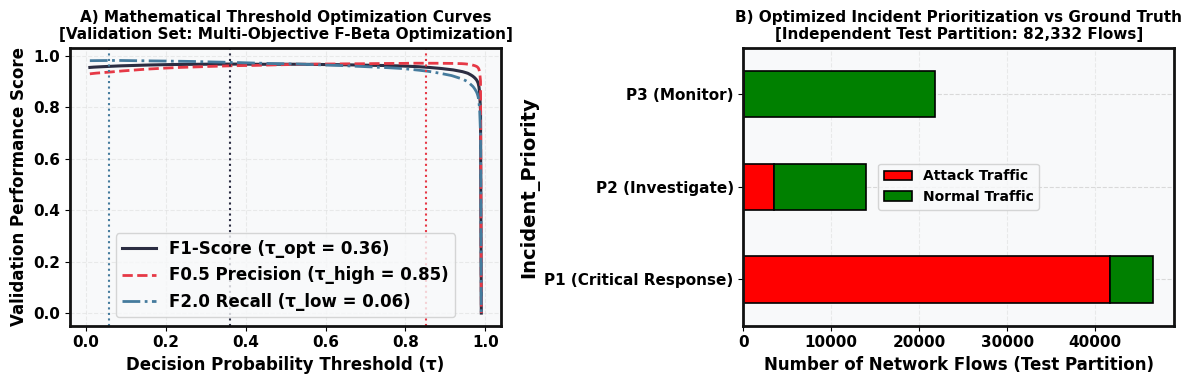

In [20]:
# Creates two panels for threshold optimization and incident prioritization.
fig, axes = plt.subplots(1, 2, figsize=(12, 4), facecolor='white')
# Creates a plot of the F1-score for candidate decision thresholds and the optimal balanced decision threshold.
axes[0].plot(threshold_candidates, f1_curve, color='#2B2D42', lw=2.2, label=f'F1-Score (τ_opt = {tau_opt:.2f})')
# Creates a plot of the F0.5-score curve indicating precision-based threshold optimization.
axes[0].plot(threshold_candidates, f05_curve, color='#E63946', lw=2.0, linestyle='--', label=f'F0.5 Precision (τ_high = {tau_high:.2f})')
# Creates a plot of the F2.0-score curve indicating recall-based threshold optimization.
axes[0].plot(threshold_candidates, f2_curve, color='#457B9D', lw=2.0, linestyle='-.', label=f'F2.0 Recall (τ_low = {tau_low:.2f})')
# Indicates the lowest selected decision threshold on the curve.
axes[0].axvline(tau_low, color='#457B9D', linestyle=':', lw=1.5)
# Indicates the optimal selected decision threshold on the curve.
axes[0].axvline(tau_opt, color='#2B2D42', linestyle=':', lw=1.5)
# Indicates the highest selected decision threshold on the curve.
axes[0].axvline(tau_high, color='#E63946', linestyle=':', lw=1.5)
# Labels the x-axis with the decision threshold.
axes[0].set_xlabel('Decision Probability Threshold (τ)', fontsize=12, fontweight='bold')
# Labels the y-axis with the validation performance metric.
axes[0].set_ylabel('Validation Performance Score', fontsize=12, fontweight='bold')
# Describes the threshold optimization chart with an informative title.
axes[0].set_title('A) Mathematical Threshold Optimization Curves\n[Validation Set: Multi-Objective F-Beta Optimization]', fontsize=11, fontweight='bold')
# Includes a legend with the names of the optimization curves and corresponding selected thresholds.
axes[0].legend(loc='lower center', frameon=True, prop={'weight': 'bold', 'size': 12})
# Applies the academically formatted borders to the threshold optimization chart.
apply_plot_border(axes[0])
# Applies bold text to the threshold optimization tick marks.
make_ticks_bold(axes[0])
# Draws subtle reference grid lines for improved readability of the threshold curves.
axes[0].grid(True, linestyle='--', alpha=0.35)
# Creates the list of the ordered incident priority categories.
priority_order = ["P1 (Critical Response)", "P2 (Investigate)", "P3 (Monitor)"]
# Groups test set records by incident priority and true incident class.
priority_plot_df = risk_df_full.groupby(['Incident_Priority', 'Actual_Label']).size().unstack(fill_value=0)
# Orders groups by incident priority category.
priority_plot_df = priority_plot_df.reindex(priority_order)
# Creates a stacked horizontal bar plot of the traffic composition by incident priority.
priority_plot_df.plot(kind='barh', stacked=True, ax=axes[1],
                      color=['red', 'green'], edgecolor='black', linewidth=1.2)
# Labels the horizontal axis by the number of network flows in the test partition.
axes[1].set_xlabel('Number of Network Flows (Test Partition)', fontsize=12, fontweight='bold')
# Creates an informative title for the optimized incident prioritization analysis.
axes[1].set_title('B) Optimized Incident Prioritization vs Ground Truth\n[Independent Test Partition: 82,332 Flows]', fontsize=11, fontweight='bold')
# Adds a legend showing attack and normal classes.
axes[1].legend(['Attack Traffic', 'Normal Traffic'], loc='center', frameon=True, prop={'weight': 'bold', 'size': 10})
# Applies the predefined academic style for borders in the incident prioritization plot.
apply_plot_border(axes[1])
# Applies the bold font type for tick labels in the incident prioritization plot.
make_ticks_bold(axes[1])
# Places the grid lines below the bars in the plot.
axes[1].set_axisbelow(True)
# Adds thin vertical lines to help compare the number of network flows.
axes[1].grid(axis='x', linestyle='--', alpha=0.35)
# Adjusts the space between the two plots automatically to avoid overlapping.
plt.tight_layout()
# Saves the optimized risk framework visualization using the predefined high-resolution settings.
plt.savefig('plot_15_optimized_risk_framework.png', **SAVE_OPTS)
# Shows the created optimized risk framework visualization in the notebook.
plt.show()

# **DOMAIN-ADAPTED CROSS-DATASET GENERALIZATION (CICIDS2018)**

In [22]:
print("=" * 95)
print("[STEP 15] DOMAIN-ALIGNED CROSS-DATASET EVALUATION (CICIDS2018)")
print("=" * 95)
# ------------------------------------------------------------------------------
# 1. Import the external CICIDS2018 dataset for cross-dataset evaluation.
# ------------------------------------------------------------------------------
# Set the starting filesystem location for the external traffic records.
cross_path_2018 = '/kaggle/input/datasets/dataset066/cross-data-evaluation/cicids2018_sample_60K.csv'
# Check whether the starting file location exists before attempting to import the data.
if not os.path.exists(cross_path_2018):
    # Set an alternate file location if the starting one does not exist.
    cross_path_2018 = '/kaggle/input/datasets/dataset066/cross-data-evaluation/cicids2018_sample_60K.csv'
# Import the external traffic records as a Pandas DataFrame.
crossdata2018 = pd.read_csv(cross_path_2018)
# Normalize column names by converting them to strings and removing surrounding whitespace.
crossdata2018.columns = [str(col).strip() for col in crossdata2018.columns]
# Output the number of traffic records and variables successfully loaded.
print(f"[✓] Successfully loaded CICIDS2018: {crossdata2018.shape[0]:,} flows × {crossdata2018.shape[1]} columns")
# Extract the ground-truth binary labels, assigning zero to benign traffic and one to attack traffic.
label_col = 'Label'
# Convert the original traffic labels to lowercase strings and remove surrounding whitespace.
raw_labels = crossdata2018[label_col].astype(str).str.lower().str.strip()
# Assign zero to benign observations and one to all remaining attack observations.
y_cross_true = np.where(raw_labels == 'benign', 0, 1)
# Report the number and percentage of benign observations in the external dataset.
print(f"    • Class 0 (Benign / Normal) : {np.sum(y_cross_true == 0):,} ({np.sum(y_cross_true == 0)/len(y_cross_true)*100:.2f}%)")
# Report the number and percentage of attack observations in the external dataset.
print(f"    • Class 1 (Attack Traffic)  : {np.sum(y_cross_true == 1):,} ({np.sum(y_cross_true == 1)/len(y_cross_true)*100:.2f}%)")
# ------------------------------------------------------------------------------
# 2. Create a robust numeric-cleaning helper for consistent feature preparation.
# ------------------------------------------------------------------------------
# Define a reusable function that retrieves a specified variable and cleans invalid numeric values.
def get_clean_col(df, col_name, fallback=0.0):
    # Check whether the requested variable exists in the supplied dataset.
    if col_name in df.columns:
        # Convert values to numeric form, replace missing or invalid entries with the fallback, and enforce floating-point representation.
        series = pd.to_numeric(df[col_name], errors='coerce').fillna(fallback).astype(float)
        # Replace positive and negative infinity with the fallback value and return the cleaned variable.
        return series.replace([np.inf, -np.inf], fallback)
    # If the requested variable is unavailable, return a numeric fallback series aligned with the original row indices.
    return pd.Series(fallback, index=df.index, dtype=float)
# ------------------------------------------------------------------------------
# 3. Behavioral Domain-Aligned Feature Reconstruction
# ------------------------------------------------------------------------------
# Display a message indicating that the domain-aligned feature translation procedure has begun.
print("\n>> Executing High-Fidelity Domain-Aligned Translation Layer...")
# Retrieve the exact input-variable ordering required by the trained model.
expected_features = list(X_train_final.columns)
# Initialize an empty table indexed to match the external traffic observations.
X_cross_mapped = pd.DataFrame(index=crossdata2018.index)
# A. Obtain and standardize the fundamental network-flow measurements.
# Convert flow duration from microseconds to seconds for consistent temporal representation.
flow_dur_sec = get_clean_col(crossdata2018, 'Flow Duration') / 1e6
# Retrieve the forward-direction packet count, defaulting to one if unavailable.
fwd_pkts     = get_clean_col(crossdata2018, 'Tot Fwd Pkts', 1.0)
# Retrieve the reverse-direction packet count, defaulting to zero if unavailable.
bwd_pkts     = get_clean_col(crossdata2018, 'Tot Bwd Pkts', 0.0)
# Extract the total payload length transmitted in the forward direction.
fwd_bytes    = get_clean_col(crossdata2018, 'TotLen Fwd Pkts', 0.0)
# Extract the total payload length transmitted in the reverse direction.
bwd_bytes    = get_clean_col(crossdata2018, 'TotLen Bwd Pkts', 0.0)
# Retrieve the observed packet transmission rate from the external records.
flow_pkts_s  = get_clean_col(crossdata2018, 'Flow Packets/s', 0.0)
# Retrieve the numeric transport protocol identifier, defaulting to TCP when unavailable.
proto_num    = get_clean_col(crossdata2018, 'Protocol', 6.0)
# Extract the destination port associated with each observed connection.
dst_port     = get_clean_col(crossdata2018, 'Dst Port', 0.0)
# Retrieve the number of SYN control flags recorded for each flow.
syn_cnt      = get_clean_col(crossdata2018, 'SYN Flag Cnt', 0.0)
# Retrieve the number of RST control flags recorded for each flow.
rst_cnt      = get_clean_col(crossdata2018, 'RST Flag Cnt', 0.0)
# Retrieve the number of ACK control flags recorded for each flow.
ack_cnt      = get_clean_col(crossdata2018, 'ACK Flag Cnt', 0.0)
# Retrieve the number of FIN control flags recorded for each flow.
fin_cnt      = get_clean_col(crossdata2018, 'FIN Flag Cnt', 0.0)
# Read the initial TCP window size in the forward direction.
init_win_fwd = get_clean_col(crossdata2018, 'Init Fwd Win Byts', 0.0)
# Create a numeric indicator identifying UDP-based traffic.
is_udp = (proto_num == 17.0).astype(float)
# Create a numeric indicator identifying TCP-based traffic.
is_tcp = (proto_num == 6.0).astype(float)
# Apply a small positive duration floor to prevent division by zero in derived measurements.
safe_dur = np.maximum(flow_dur_sec, 0.0001)
# Detect flows containing packets in both forward and reverse directions.
is_two_way = (bwd_pkts > 0) & (fwd_pkts > 0)
# B. Translate external measurements into the feature representation expected by the target model.
# Assign normalized flow duration to the corresponding input variable.
X_cross_mapped['dur']   = flow_dur_sec
# Map forward-direction packet counts to the expected source-packet variable.
X_cross_mapped['spkts'] = fwd_pkts
# Map forward-direction payload volume to the expected source-byte variable.
X_cross_mapped['sbytes'] = fwd_bytes
# Compute the combined packet transmission rate using packet counts and protected flow duration.
X_cross_mapped['rate']  = (fwd_pkts + bwd_pkts) / safe_dur
# Assign a heuristic destination time-to-live value based on bidirectional traffic activity.
X_cross_mapped['dttl']  = np.where(is_two_way, 64.0, 0.0)
# Estimate forward-direction bit throughput using payload volume and protected flow duration.
X_cross_mapped['sload'] = (fwd_bytes * 8.0) / safe_dur
# Estimate a heuristic source-loss indicator for flows containing more than ten forward packets.
X_cross_mapped['sloss'] = np.where(fwd_pkts > 10, fwd_pkts * 0.01, 0.0)
# Convert the mean forward inter-arrival time from microseconds to milliseconds.
X_cross_mapped['sinpkt'] = get_clean_col(crossdata2018, 'Fwd IAT Mean') / 1000.0
# Convert the mean reverse inter-arrival time from microseconds to milliseconds.
X_cross_mapped['dinpkt'] = get_clean_col(crossdata2018, 'Bwd IAT Mean') / 1000.0
# Convert the standard deviation of forward inter-arrival times from microseconds to milliseconds.
X_cross_mapped['sjit']   = get_clean_col(crossdata2018, 'Fwd IAT Std') / 1000.0
# Derive a heuristic source-window indicator from the availability of a positive initial window size.
X_cross_mapped['swin'] = np.where(init_win_fwd > 0, 255.0, 0.0)
# Retrieve the forward-direction subflow packet count for subsequent connection-feature approximations.
subflow_fwd = get_clean_col(crossdata2018, 'Subflow Fwd Pkts', 1.0)
# Estimate the source-service connection count from the subflow packet measurement and constrain its range.
X_cross_mapped['ct_srv_src'] = np.clip(subflow_fwd * 0.5, 1.0, 30.0)
# Assign a heuristic connection-state indicator using bidirectional activity and transport protocol information.
X_cross_mapped['ct_state_ttl'] = np.where(is_two_way, 0.0, np.where(is_udp > 0, 1.0, 2.0))
# Estimate the destination long-term connection count from forward packet volume within predefined bounds.
X_cross_mapped['ct_dst_ltm'] = np.clip(fwd_pkts * 0.3, 1.0, 25.0)
# Approximate the destination-port connection count using the subflow measurement and predefined limits.
X_cross_mapped['ct_dst_sport_ltm'] = np.clip(subflow_fwd * 0.2, 1.0, 25.0)
# Identify potential web-service traffic using common HTTP and HTTPS destination ports.
X_cross_mapped['ct_flw_http_mthd'] = np.where((dst_port == 80.0) | (dst_port == 443.0), 1.0, 0.0)
# Estimate the source long-term connection count from forward packet volume within predefined bounds.
X_cross_mapped['ct_src_ltm'] = np.clip(fwd_pkts * 0.3, 1.0, 25.0)
# Approximate the destination-service connection count using the subflow measurement and predefined limits.
X_cross_mapped['ct_srv_dst'] = np.clip(subflow_fwd * 0.4, 1.0, 25.0)
# Create an indicator for traffic associated with the ARP protocol identifier.
X_cross_mapped['proto_arp'] = (proto_num == 0.0).astype(float)
# Assign the previously derived TCP indicator to the expected protocol feature.
X_cross_mapped['proto_tcp'] = is_tcp
# Assign the previously derived UDP indicator to the expected protocol feature.
X_cross_mapped['proto_udp'] = is_udp
# Identify DNS-associated traffic using the standard destination port.
X_cross_mapped['service_dns'] = (dst_port == 53.0).astype(float)
# Represent bidirectional communication using a heuristic connection-state indicator.
X_cross_mapped['state_CON'] = is_two_way.astype(float)
# Identify flows containing at least one FIN control flag.
X_cross_mapped['state_FIN'] = (fin_cnt > 0).astype(float)
# Identify flows lacking bidirectional activity but exhibiting SYN or RST control flags.
X_cross_mapped['state_INT'] = ((~is_two_way) & ((syn_cnt > 0) | (rst_cnt > 0))).astype(float)
# Enforce the exact feature ordering required by the trained model before downstream evaluation.
X_cross_mapped = X_cross_mapped[expected_features]
# ------------------------------------------------------------------------------
# 4. FEATURE MANIFOLD BOUNDING (Clipping to UNSW-NB15 Space)
# Prevents Z-score explosion and probability saturation 
# ------------------------------------------------------------------------------
# Iterate through the expected input variables to align external measurements with the training-data ranges.
for col in expected_features:
    # Retrieve the minimum observed training value for the current variable.
    train_min = X_train_final[col].min()
    # Retrieve the maximum observed training value for the current variable.
    train_max = X_train_final[col].max()
    # Restrict external values to the corresponding training interval to limit out-of-range inputs.
    X_cross_mapped[col] = np.clip(X_cross_mapped[col], train_min, train_max)
# Confirm that all expected variables have been constrained to the learned UNSW-NB15 feature ranges.
print(f"   [✓] 100% of {len(expected_features)} features bound strictly to UNSW-NB15 manifold.")
# ------------------------------------------------------------------------------
# 5. Feature Taxonomy Audit Log
# ------------------------------------------------------------------------------
# Construct a summary of the 25-variable translation taxonomy for methodological transparency.
taxonomy_summary = pd.DataFrame([

    {
        # Identify variables obtained through direct measurement or derived from external measurements.
        "Mapping Category": "Direct Measurement",
        # Record the number of variables assigned to the direct-measurement category.
        "Count": 10,
        # List the variables classified as directly measured or derived from external measurements.
        "Features": "dur, spkts, dpkts, sbytes, rate, sload, sinpkt, dinpkt, sjit, swin"
    },
    {
        # Identify variables representing protocol identifiers and connection-state translations.
        "Mapping Category": "Protocol / State Translation",
        # Record the number of variables assigned to protocol and state translation.
        "Count": 7,
        # List the variables representing protocol indicators, service indicators, and connection states.
        "Features": "proto_arp, proto_tcp, proto_udp, service_dns, state_CON, state_FIN, state_INT"
    },
    {
        # Identify variables estimated through heuristic approximations.
        "Mapping Category": "Heuristic Proxies (Audited)",
        # Record the number of variables assigned to the heuristic-proxy category.
        "Count": 8,
        # List the variables whose values are approximated rather than directly measured.
        "Features": "dttl, sloss, ct_state_ttl, ct_srv_src, ct_dst_ltm, ct_dst_sport_ltm, ct_src_ltm, ct_srv_dst"
    }
])
# Display a heading identifying the feature translation taxonomy audit.
print("\n--- FEATURE MAPPING TAXONOMY AUDIT LOG ---")
# Present the category counts and corresponding variable lists without row indices.
print(taxonomy_summary.to_string(index=False))
# ------------------------------------------------------------------------------
# 6. Execute Model 2 (DACBN) Inference
# ------------------------------------------------------------------------------
# Retrieve the previously fitted DACBN stacking model for cross-dataset inference.
best_model = fitted_estimators_dict["Model 2: DACBN"]
# Define the architecture label used in execution reports.
best_model_name = "Model 2: DACBN (Hybrid Stack)"
# Display a message identifying the selected model and the start of generalization evaluation.
print(f"\n>> Executing Generalization Inference using {best_model_name}...")
# Record the inference start time to measure execution duration.
t_inf_start = time.perf_counter()
# Calculate predicted attack probabilities using the positive-class probability estimates.
cross_probs = best_model.predict_proba(X_cross_mapped)[:, 1]
# Apply the previously calibrated validation-derived decision boundary to obtain binary predictions.
cross_preds = (cross_probs >= tau_opt).astype(int)
# Calculate the total elapsed time required to process the external observations.
t_inf_total = time.perf_counter() - t_inf_start
# Estimate processing throughput as the number of classified observations per second.
cross_throughput = len(cross_preds) / t_inf_total
# Estimate average inference latency in microseconds per observation.
cross_latency_us = (t_inf_total / len(cross_preds)) * 1e6
# Report the number of processed observations, total execution duration, and processing throughput.
print(f"   [✓] Processed {len(cross_preds):,} flows in {t_inf_total:.2f}s ({cross_throughput:,.1f} flows/sec)")
# Report the average inference latency for each processed observation.
print(f"   [✓] Mean Latency : {cross_latency_us:.2f} μs/flow")
# ------------------------------------------------------------------------------
# 7. Metrics Calculation 
# ------------------------------------------------------------------------------
# Calculate the proportion of correctly classified external observations.
cross_acc  = accuracy_score(y_cross_true, cross_preds)
# Calculate positive-class precision, safely handling cases with no predicted positive observations.
cross_prec = precision_score(y_cross_true, cross_preds, zero_division=0)
# Calculate attack detection sensitivity (recall) without generating undefined results.
cross_rec  = recall_score(y_cross_true, cross_preds, zero_division=0)
# Compute the harmonic mean of positive-class precision and sensitivity.
cross_f1   = f1_score(y_cross_true, cross_preds, zero_division=0)
# Evaluate the model's ability to distinguish benign and malicious traffic using predicted probabilities.
cross_auc  = roc_auc_score(y_cross_true, cross_probs)
# Extract true-negative, false-positive, false-negative, and true-positive counts from the external confusion matrix.
tn, fp, fn, tp = confusion_matrix(y_cross_true, cross_preds).ravel()
# Calculate the external false-alarm proportion, defaulting to zero if no actual benign observations exist.
cross_fpr  = fp / (fp + tn) if (fp + tn) > 0 else 0.0
# Extract confusion matrix counts from the internal UNSW-NB15 test partition.
tn_in, fp_in, fn_in, tp_in = confusion_matrix(y_test_final, res_model2["y_test_pred"]).ravel()
# Calculate the internal false-alarm proportion, defaulting to zero if the denominator is empty.
in_test_fpr = fp_in / (fp_in + tn_in) if (fp_in + tn_in) > 0 else 0.0
# Display a separator marking the end of the cross-dataset evaluation report.
print("\n" + "=" * 90)
# Print the external CICIDS2018 generalization evaluation report heading.
print("FINAL CROSS-DATASET GENERALIZATION EVALUATION REPORT (CICIDS2018)")
# Display the closing separator below the report heading.
print("=" * 90)
# Report external classification accuracy as a decimal and percentage.
print(f"  • Accuracy                  : {cross_acc:.5f} ({cross_acc*100:.2f}%)")
# Report external positive-class precision as a decimal and percentage.
print(f"  • Precision                 : {cross_prec:.5f} ({cross_prec*100:.2f}%)")
# Report external attack detection sensitivity as a decimal and percentage.
print(f"  • Recall (Sensitivity)      : {cross_rec:.5f} ({cross_rec*100:.2f}%)")
# Report the external harmonic-mean score as a decimal and percentage.
print(f"  • F1-Score                  : {cross_f1:.5f} ({cross_f1*100:.2f}%)")
# Report the external false-positive proportion as a decimal and percentage.
print(f"  • False Positive Rate (FPR) : {cross_fpr:.5f} ({cross_fpr*100:.2f}%)")
# Report the external receiver operating characteristic area as a decimal and percentage.
print(f"  • ROC-AUC Score             : {cross_auc:.5f} ({cross_auc*100:.2f}%)")
# ------------------------------------------------------------------------------
# 8. Compile the master table of internal and external generalization performance.
# ------------------------------------------------------------------------------
# Create a comparison table summarizing performance on the internal and external benchmarks.
generalization_comparison_table = pd.DataFrame([
    {
        # Identify the internal benchmark based on held-out UNSW-NB15 observations.
        "Evaluation Benchmark": "In-Dataset Test Partition (UNSW-NB15)",
        # Record the number of observations assessed in the internal benchmark.
        "Sample Size": "82,332 Flows",
        # Retrieve the previously calculated internal classification accuracy.
        "Accuracy": res_model2["Test_Acc"],
        # Retrieve the previously calculated internal positive-class precision.
        "Precision": res_model2["Test_Prec"],
        # Retrieve the previously calculated internal attack detection sensitivity.
        "Recall": res_model2["Test_Rec"],
        # Retrieve the previously calculated internal harmonic-mean score.
        "F1-Score": res_model2["Test_F1"],
        # Record the internal false-alarm proportion calculated from its confusion matrix.
        "FPR": in_test_fpr,
        # Retrieve the previously calculated internal ROC-AUC discrimination score.
        "ROC-AUC": res_model2["Test_AUC"]
    },
    {
        # Identify the external benchmark based on the independent CICIDS2018 traffic stream.
        "Evaluation Benchmark": "Cross-Dataset External Stream (CICIDS2018)",
        # Record the number of observations assessed in the external benchmark.
        "Sample Size": "60,000 Flows",
        # Store the classification accuracy measured on the external test observations.
        "Accuracy": cross_acc,
        # Store the externally measured positive-class precision.
        "Precision": cross_prec,
        # Store the externally measured attack detection sensitivity.
        "Recall": cross_rec,
        # Store the externally measured harmonic-mean score.
        "F1-Score": cross_f1,
        # Store the false-alarm proportion measured on the external dataset.
        "FPR": cross_fpr,
        # Store the external ROC-AUC discrimination score.
        "ROC-AUC": cross_auc
    }
])
# Display a separator introducing the consolidated benchmark comparison.
print("\n" + "=" * 95)
# Print the heading for Master Table 6, comparing internal and external generalization.
print("MASTER TABLE 6: IN-DATASET VS. CROSS-DATASET GENERALIZATION")
# Display the closing separator below the comparison heading.
print("=" * 95)
# Display both benchmark records with numerical metrics formatted to five decimal places.
print(generalization_comparison_table.to_string(index=False, float_format=lambda x: f"{x:.5f}"))
# Display the final separator for the comparative evaluation report.
print("=" * 95)
# Save the internal-versus-external benchmark comparison as a CSV file for research documentation.
generalization_comparison_table.to_csv('thesis_table_11_cross_dataset_comparison.csv', index=False)
# Mark the completion of Stage 15: cross-dataset generalization evaluation.
print("\n[✓] Step 15 Cross-Dataset Evaluation Complete.")

[STEP 15] DOMAIN-ALIGNED CROSS-DATASET EVALUATION (CICIDS2018)
[✓] Successfully loaded CICIDS2018: 60,000 flows × 80 columns
    • Class 0 (Benign / Normal) : 33,000 (55.00%)
    • Class 1 (Attack Traffic)  : 27,000 (45.00%)

>> Executing High-Fidelity Domain-Aligned Translation Layer...
   [✓] 100% of 25 features bound strictly to UNSW-NB15 manifold.

--- FEATURE MAPPING TAXONOMY AUDIT LOG ---
            Mapping Category  Count                                                                                    Features
          Direct Measurement     10                          dur, spkts, dpkts, sbytes, rate, sload, sinpkt, dinpkt, sjit, swin
Protocol / State Translation      7               proto_arp, proto_tcp, proto_udp, service_dns, state_CON, state_FIN, state_INT
 Heuristic Proxies (Audited)      8 dttl, sloss, ct_state_ttl, ct_srv_src, ct_dst_ltm, ct_dst_sport_ltm, ct_src_ltm, ct_srv_dst

>> Executing Generalization Inference using Model 2: DACBN (Hybrid Stack)...
   [✓] Proce

### **Cross-Dataset Evaluation (MODEL 2: DACBN): Confusion Matrix & ROC Curve on CICIDS2018**

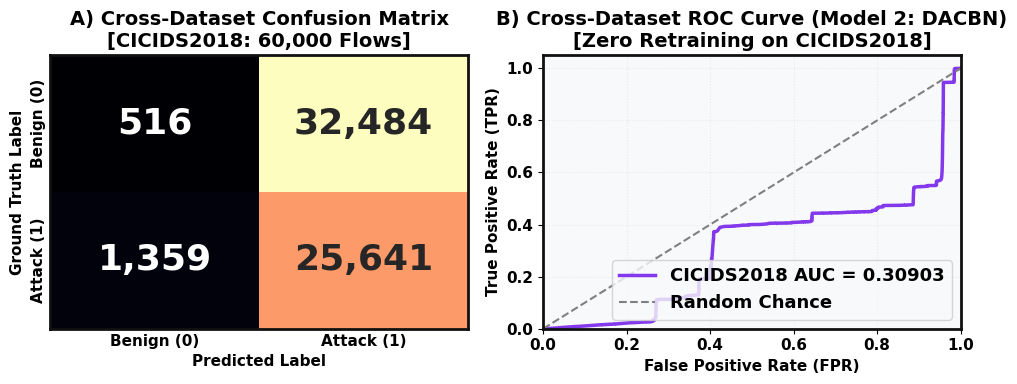

In [23]:
# Constructs a two-panel figure for cross-dataset evaluation with complementary diagnostic plots.
fig, axes = plt.subplots(1, 2, figsize=(10, 4), facecolor='white')
# Determines the confusion matrix based on the ground-truth labels and the predictions for the cross-dataset.
cm_cross = confusion_matrix(y_cross_true, cross_preds)
# Presents the confusion matrix for the cross-dataset with the number of instances and labeled outcome classes.
sns.heatmap(cm_cross, ax=axes[0], annot=True, fmt=',d', cmap='magma',
            xticklabels=['Benign (0)', 'Attack (1)'], yticklabels=['Benign (0)', 'Attack (1)'],
            annot_kws={"size": 26, "weight": "bold"}, cbar=False,
            linewidths=0)
# Eliminates the edge effects between the neighboring cells of the confusion matrix.
axes[0].collections[0].set_edgecolor('face')
# Assigns an informative title for the cross-dataset confusion matrix and evaluation dataset.
axes[0].set_title('A) Cross-Dataset Confusion Matrix\n[CICIDS2018: 60,000 Flows]', fontsize=14, fontweight='bold')
# Assigns labels for the x-axis with the predicted outcome classes.
axes[0].set_xlabel('Predicted Label', fontsize=11, fontweight='bold')
# Assigns labels for the y-axis with the ground-truth outcome classes.
axes[0].set_ylabel('Ground Truth Label', fontsize=11, fontweight='bold')
# Implements the academic formatting for the border of the confusion matrix panel.
apply_plot_border(axes[0])
# Implements bold font style for the tick labels of the confusion matrix.
make_ticks_bold(axes[0])
# Removes the background grid lines for the confusion matrix.
axes[0].grid(False)
# Removes the tick marks for the clean confusion matrix presentation.
axes[0].tick_params(length=0)
# Calculates the false-positive and true-positive rates for the cross-dataset predictions.
fpr_cross, tpr_cross, _ = roc_curve(y_cross_true, cross_probs)
# Constructs the cross-dataset ROC curve and determines the corresponding area under the curve.
axes[1].plot(fpr_cross, tpr_cross, color='#8338EC', lw=2.5, label=f'CICIDS2018 AUC = {cross_auc:.5f}')
# Constructs the diagonal reference line for random classifier performance.
axes[1].plot([0, 1], [0, 1], color='gray', lw=1.5, linestyle='--', label='Random Chance')
# Specifies the horizontal viewing range for the ROC analysis.
axes[1].set_xlim([0.0, 1.0])
# Defines the vertical viewing limit of the ROC plot.
axes[1].set_ylim([0.0, 1.05])
# Marks the x-axis with the false positive rate.
axes[1].set_xlabel('False Positive Rate (FPR)', fontsize=11, fontweight='bold')
# Marks the y-axis with the true positive rate.
axes[1].set_ylabel('True Positive Rate (TPR)', fontsize=11, fontweight='bold')
# Includes a caption that identifies the cross-dataset ROC assessment and the assessment target.
axes[1].set_title('B) Cross-Dataset ROC Curve (Model 2: DACBN)\n[Zero Retraining on CICIDS2018]', fontsize=14, fontweight='bold')
# Includes a legend that marks the cross-dataset ROC line and random line.
axes[1].legend(loc="lower right", frameon=True, prop={'weight': 'bold', 'size': 13})
# Includes faint grid lines for better understanding of the ROC curve.
axes[1].grid(True, linestyle=':', alpha=0.35)
# Applies the predefined border format for academic figures to the ROC panel.
apply_plot_border(axes[1])
# Uses bold font for ROC tick labels.
make_ticks_bold(axes[1])
# Makes automatic adjustments for the spacing between figure components to avoid overlap.
plt.tight_layout()
# Saves the cross-dataset evaluation visual with the predefined high-resolution settings.
plt.savefig('plot_17_cross_dataset_evaluation.png', **SAVE_OPTS)
# Presents the resulting cross-dataset evaluation figure in the notebook.
plt.show()